In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
#Cell R1 — Clone source và kiểm tra môi trường
%cd /kaggle/working

!git clone https://github.com/ThaoTo2806/FineZip28.git
!git -C /kaggle/working/FineZip28 checkout 62f09e3105296d62c39e8d95cf8b8775e63f2677

!pip install -q transformers==5.0.0 accelerate sentencepiece

!nvidia-smi
!git -C /kaggle/working/FineZip28 rev-parse HEAD

/kaggle/working
Cloning into 'FineZip28'...
remote: Enumerating objects: 218, done.
remote: Counting objects: 100% (143/143), done.
remote: Compressing objects: 100% (120/120), done.
remote: Total 218 (delta 48), reused 109 (delta 21), pack-reused 75 (from 1)
Receiving objects: 100% (218/218), 83.94 MiB | 28.40 MiB/s, done.
Resolving deltas: 100% (60/60), done.
Updating files: 100% (115/115), done.
Note: switching to '62f09e3105296d62c39e8d95cf8b8775e63f2677'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 62f

In [2]:
#Stage 6A — Cell R2: Khôi phục checkpoint và kiểm tra SHA-256
from pathlib import Path
import shutil
import json
import hashlib
import pandas as pd

ROOT = Path("/kaggle/working/FineZip28")
STAGE = Path("/kaggle/working/stage6A")

EVIDENCE = Path(
    "/kaggle/input/datasets/thothanh28/"
    "stage6a-part1-evidence/stage6A"
)

ARTIFACTS = Path(
    "/kaggle/input/datasets/thothanh28/"
    "stage6a-part1-artifacts/stage6A/artifacts"
)

assert EVIDENCE.exists(), "Missing evidence input"
assert ARTIFACTS.exists(), "Missing artifacts input"

# Khôi phục checkpoint
shutil.copytree(EVIDENCE, STAGE, dirs_exist_ok=True)

shutil.copytree(
    ARTIFACTS,
    STAGE / "artifacts",
    dirs_exist_ok=True
)

print("=== RESTORE CHECKPOINT ===")

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

encode_results = json.loads(
    (STAGE / "results/encode_1mb.json").read_text()
)

decode_results = json.loads(
    (STAGE / "results/decode_1mb.json").read_text()
)

metadata = json.loads(
    (STAGE / "results/session_part1.json").read_text()
)

assert len(encode_results) == 9
assert len(decode_results) == 5

print("\n=== VERIFY ENCODE ARTIFACTS ===")

for r in encode_results:

    name = r["method"]

    p = STAGE / "artifacts" / f"{name}_1mb.fzac"

    assert p.exists(), f"Missing: {name}"

    assert sha256_bytes(p.read_bytes()) == r["artifact_sha256"], \
        f"Checksum mismatch: {name}"

    print(f"PASS | {name:22s} | {p.stat().st_size:,} B")

print("\n=== VERIFY COMPLETED FULL DECODE ===")

for r in decode_results:

    name = r["method"]

    p = STAGE / "artifacts" / f"{name}_decoded.txt"

    assert p.exists()
    assert r["full_decode"] == "PASS"
    assert r["byte_exact"] and r["token_exact"]

    assert sha256_bytes(p.read_bytes()) == \
        metadata["original_sha256"]

    print(f"PASS | {name:22s} | SHA-256 verified")

print("\n=== COMPLETED RESULTS ===")

display(pd.DataFrame(decode_results)[[
    "method",
    "compressed_bytes",
    "ratio",
    "encode_seconds",
    "decode_seconds",
    "byte_exact",
    "full_decode"
]].round(4))

print("\n=== PENDING ===")

for name in metadata["pending"]:
    print("PENDING:", name)

print("\nEncode restored: 9/9")
print("Full decode restored: 5/9")
print("Previous session:", metadata["session_id"])
print("CHECKPOINT RESTORE: PASS")
print("CELL R2 DONE")

=== RESTORE CHECKPOINT ===

=== VERIFY ENCODE ARTIFACTS ===
PASS | Fixed-32               | 300,576 B
PASS | Fixed-64               | 271,704 B
PASS | Fixed-128              | 246,976 B
PASS | Fixed-256              | 228,006 B
PASS | Fixed-512              | 213,691 B
PASS | Adaptive-DP-1000       | 216,534 B
PASS | Adaptive-DP-5000       | 238,128 B
PASS | Adaptive-DP-12000      | 258,127 B
PASS | Adaptive-DP-40000      | 288,012 B

=== VERIFY COMPLETED FULL DECODE ===
PASS | Fixed-32               | SHA-256 verified
PASS | Fixed-64               | SHA-256 verified
PASS | Fixed-128              | SHA-256 verified
PASS | Fixed-256              | SHA-256 verified
PASS | Fixed-512              | SHA-256 verified

=== COMPLETED RESULTS ===


,method,compressed_bytes,ratio,encode_seconds,decode_seconds,byte_exact,full_decode
0,Fixed-32,300576,3.3269,28.5648,838.8019,True,PASS
1,Fixed-64,271704,3.6805,28.9751,1662.7138,True,PASS
2,Fixed-128,246976,4.0490,28.5877,3157.6798,True,PASS
3,Fixed-256,228006,4.3858,29.0480,6356.6881,True,PASS
4,Fixed-512,213691,4.6797,29.4712,12950.8678,True,PASS



=== PENDING ===
PENDING: Adaptive-DP-1000
PENDING: Adaptive-DP-5000
PENDING: Adaptive-DP-12000
PENDING: Adaptive-DP-40000

Encode restored: 9/9
Full decode restored: 5/9
Previous session: Stage6A-Session01
CHECKPOINT RESTORE: PASS
CELL R2 DONE


In [3]:
#Stage 6A — Cell R3: Khôi phục GPT-2 và kiểm tra tương thích
import sys
import time
import gc
import torch
import numpy as np
import transformers
from transformers import AutoTokenizer

sys.path.insert(0, str(ROOT / "update"))

import adaptive_context_finezip_v3 as fz
import stage5_tools as s5

SESSION_ID = "Stage6A-Session02"

torch.cuda.set_device(0)
torch.backends.cuda.matmul.allow_tf32 = False
torch.set_float32_matmul_precision("highest")

print("=== ENVIRONMENT ===")
print("Session:", SESSION_ID)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("NumPy:", np.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))

# Khôi phục dữ liệu gốc
data_path = ROOT / "notebook/finezip_experiment2/data/baseline_1mb.txt"
raw = data_path.read_bytes()

assert sha256_bytes(raw) == metadata["original_sha256"]

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.model_max_length = 10**9

tokens = np.asarray(
    tokenizer.encode(
        raw.decode("utf-8"),
        add_special_tokens=False
    ),
    dtype=np.int64
)

assert len(tokens) == metadata["tokens"]

assert tokenizer.decode(
    tokens.tolist(),
    clean_up_tokenization_spaces=False
).encode("utf-8") == raw

print("\n=== DATASET ===")
print("Bytes:", len(raw))
print("Tokens:", len(tokens))
print("SHA-256: PASS")
print("Tokenizer roundtrip: PASS")

# Load model
print("\n=== LOAD GPT-2 ===")

lm = fz.HFLM(
    name="gpt2",
    device="cuda:0",
    max_batch_tokens=1024,
    eps=None
)

cfg, env = lm.describe()

print(json.dumps(cfg, indent=2))
print(json.dumps(env, indent=2))

assert cfg == metadata["model_config"], \
    "Model configuration mismatch"

print("\nEnvironment identical:", env == metadata["environment"])

# Kiểm tra tương thích header của cả 9 artifact
print("\n=== ARTIFACT COMPATIBILITY ===")

for r in encode_results:

    name = r["method"]
    blob = (
        STAGE / "artifacts" / f"{name}_1mb.fzac"
    ).read_bytes()

    header = fz._read_header(blob)

    assert header["fp"] == fz._fingerprint(lm)[0], \
        f"Fingerprint mismatch: {name}"

    print(f"PASS | {name}")

# Kiểm tra nhanh Adaptive-DP-1000
print("\n=== QUICK CHECK ===", flush=True)

blob = (
    STAGE / "artifacts/Adaptive-DP-1000_1mb.fzac"
).read_bytes()

ok = fz.quick_check(blob, lm, tokens)

assert ok, "Quick check failed"

# Lưu metadata session mới
session2 = {
    "session_id": SESSION_ID,
    "model_config": cfg,
    "environment": env,
    "transformers_version": transformers.__version__,
    "numpy_version": np.__version__,
    "original_sha256": sha256_bytes(raw),
    "artifact_compatibility": True,
    "quick_check": bool(ok)
}

(STAGE / "results/session_part2.json").write_text(
    json.dumps(session2, indent=2)
)

print("\nMODEL COMPATIBILITY: PASS")
print("CELL R3 DONE")

=== ENVIRONMENT ===
Session: Stage6A-Session02
PyTorch: 2.10.0+cu128
Transformers: 5.0.0
NumPy: 2.0.2
CUDA: 12.8
GPU: Tesla T4


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

{
  "name": "gpt2",
  "V": 50257,
  "bos": 50256,
  "dtype": "torch.float32",
  "attn": "sdpa",
  "adapter_sha256": null
}
{
  "torch": "2.10.0+cu128",
  "cuda": "12.8",
  "gpu": "Tesla T4",
  "tf32": false,
  "matmul_precision": "highest"
}

Environment identical: True

=== ARTIFACT COMPATIBILITY ===
PASS | Fixed-32
PASS | Fixed-64
PASS | Fixed-128
PASS | Fixed-256
PASS | Fixed-512
PASS | Adaptive-DP-1000
PASS | Adaptive-DP-5000
PASS | Adaptive-DP-12000
PASS | Adaptive-DP-40000

=== QUICK CHECK ===
quick_check: OK

MODEL COMPATIBILITY: PASS
CELL R3 DONE


In [4]:
#Stage 6A — Cell R4: Khôi phục hàm Full Decode Benchmark
from datetime import datetime, timezone

# Bổ sung session ID cho kết quả Part 1
result_path = STAGE / "results/decode_1mb.json"

decode_results = json.loads(result_path.read_text())

for r in decode_results:
    r.setdefault("encode_session_id", "Stage6A-Session01")
    r.setdefault("decode_session_id", "Stage6A-Session01")

result_path.write_text(json.dumps(decode_results, indent=2))

pd.DataFrame(decode_results).to_csv(
    STAGE / "results/decode_1mb.csv",
    index=False
)

# Khôi phục hàm benchmark
def full_decode_benchmark(name):

    artifact_path = STAGE / "artifacts" / f"{name}_1mb.fzac"
    result_path = STAGE / "results/decode_1mb.json"

    results = json.loads(result_path.read_text())

    # Không chạy lại cấu hình đã PASS
    previous = next(
        (r for r in results
         if r["method"] == name
         and r["full_decode"] == "PASS"),
        None
    )

    if previous is not None:
        print(f"SKIP: {name} already completed")
        return previous

    blob = artifact_path.read_bytes()

    enc = next(
        r for r in encode_results
        if r["method"] == name
    )

    assert sha256_bytes(blob) == enc["artifact_sha256"]

    print(f"=== FULL DECODE: {name} ===", flush=True)
    print("Session:", SESSION_ID)
    print("Compressed bytes:", len(blob))
    print("Original bytes:", len(raw))
    print("Effective L:", round(enc["effective_L"], 4))
    print("GPU:", torch.cuda.get_device_name(0))

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(0)
    torch.cuda.synchronize()

    started_at = datetime.now(timezone.utc).isoformat()

    t0 = time.perf_counter()

    decoded_tokens = fz.decode(blob, lm)

    torch.cuda.synchronize()

    decode_s = time.perf_counter() - t0
    peak_mib = torch.cuda.max_memory_allocated(0) / 1024**2

    decoded_raw = tokenizer.decode(
        decoded_tokens.tolist(),
        clean_up_tokenization_spaces=False
    ).encode("utf-8")

    token_exact = bool(np.array_equal(tokens, decoded_tokens))
    byte_exact = raw == decoded_raw

    result = {
        **enc,
        "encode_session_id": "Stage6A-Session01",
        "decode_session_id": SESSION_ID,
        "started_at": started_at,
        "finished_at": datetime.now(timezone.utc).isoformat(),
        "decode_seconds": decode_s,
        "decode_minutes": decode_s / 60,
        "decode_peak_mib": peak_mib,
        "decode_bytes_per_second": len(raw) / decode_s,
        "decoded_bytes": len(decoded_raw),
        "decoded_tokens": len(decoded_tokens),
        "token_exact": token_exact,
        "byte_exact": byte_exact,
        "decoded_sha256": sha256_bytes(decoded_raw),
        "full_decode": "PASS" if token_exact and byte_exact else "FAIL",
        "total_seconds": enc["encode_seconds"] + decode_s,
        "gpu_id": 0,
        "gpu_name": torch.cuda.get_device_name(0)
    }

    results = [
        r for r in results
        if r["method"] != name
    ]

    results.append(result)

    # Lưu checkpoint
    result_path.write_text(json.dumps(results, indent=2))

    pd.DataFrame(results).to_csv(
        STAGE / "results/decode_1mb.csv",
        index=False
    )

    (STAGE / "artifacts" / f"{name}_decoded.txt").write_bytes(
        decoded_raw
    )

    print("\n=== DECODE RESULT ===")
    print(json.dumps(result, indent=2))

    print("\nCheckpoint saved:", result_path)
    print("STATUS:", result["full_decode"])

    assert token_exact and byte_exact, "LOSSLESS FAILED"

    return result

print("=== BENCHMARK FUNCTION RESTORED ===")
print("Session:", SESSION_ID)
print("Full decode completed:", len(decode_results), "/ 9")
print("Ready for Cell 11")
print("CELL R4 DONE")

=== BENCHMARK FUNCTION RESTORED ===
Session: Stage6A-Session02
Full decode completed: 5 / 9
Ready for Cell 11
CELL R4 DONE


In [5]:
#Stage 6A — Cell 11: Full Decode Adaptive-DP-1000
adaptive1000_result = full_decode_benchmark("Adaptive-DP-1000")

print("\nCELL 11 DONE")

=== FULL DECODE: Adaptive-DP-1000 ===
Session: Stage6A-Session02
Compressed bytes: 216534
Original bytes: 1000000
Effective L: 410.7853
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Adaptive-DP-1000",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 216534,
  "ratio": 4.6182123823510395,
  "bpb": 1.732272,
  "encode_seconds": 176.24337966199982,
  "encode_peak_mib": 889.861328125,
  "effective_L": 410.78529115904774,
  "total_chunks": 811,
  "chunk_counts": {
    "32": 1,
    "64": 17,
    "128": 50,
    "256": 397,
    "512": 346
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 216534,
    "header_bytes": 278,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "1f2cb534810906dc902bcdf86dc6365e8e99b5cbab9f1d7208e25185e11c1d

In [6]:
#Stage 6A — Cell 12: Full Decode Adaptive-DP-5000
adaptive5000_result = full_decode_benchmark("Adaptive-DP-5000")

print("\nCELL 12 DONE")

=== FULL DECODE: Adaptive-DP-5000 ===
Session: Stage6A-Session02
Compressed bytes: 238128
Original bytes: 1000000
Effective L: 164.4922
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Adaptive-DP-5000",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 238128,
  "ratio": 4.199422159510851,
  "bpb": 1.905024,
  "encode_seconds": 174.88948573400012,
  "encode_peak_mib": 889.861328125,
  "effective_L": 164.49223203308372,
  "total_chunks": 2125,
  "chunk_counts": {
    "32": 39,
    "64": 380,
    "128": 1401,
    "256": 292,
    "512": 13
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 238128,
    "header_bytes": 602,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "5c21feda4ad6ee9ca34a595205aab540cd2dcbdd9e3f45d56abdea89603

In [7]:
#Stage 6A — Cell 13: Full Decode Adaptive-DP-12000
adaptive12000_result = full_decode_benchmark("Adaptive-DP-12000")

print("\nCELL 13 DONE")

=== FULL DECODE: Adaptive-DP-12000 ===
Session: Stage6A-Session02
Compressed bytes: 258127
Original bytes: 1000000
Effective L: 86.0498
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Adaptive-DP-12000",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 258127,
  "ratio": 3.8740619927400077,
  "bpb": 2.065016,
  "encode_seconds": 175.2941382140002,
  "encode_peak_mib": 889.861328125,
  "effective_L": 86.049849111434,
  "total_chunks": 3983,
  "chunk_counts": {
    "32": 563,
    "64": 2694,
    "128": 703,
    "256": 23,
    "512": 0
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 258127,
    "header_bytes": 1001,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "37f98216d6062d1af22c399d5e72d9c89cbdcde7c4ca858a112a9ef8fa97c

In [8]:
#Stage 6A — Cell 14: Full Decode Adaptive-DP-40000
adaptive40000_result = full_decode_benchmark("Adaptive-DP-40000")

print("\nCELL 14 DONE")

=== FULL DECODE: Adaptive-DP-40000 ===
Session: Stage6A-Session02
Compressed bytes: 288012
Original bytes: 1000000
Effective L: 39.9973
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Adaptive-DP-40000",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 288012,
  "ratio": 3.4720775523242087,
  "bpb": 2.304096,
  "encode_seconds": 176.70669095599987,
  "encode_peak_mib": 889.861328125,
  "effective_L": 39.99731753660445,
  "total_chunks": 7838,
  "chunk_counts": {
    "32": 6735,
    "64": 1100,
    "128": 3,
    "256": 0,
    "512": 0
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 288012,
    "header_bytes": 1193,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "f68fc28a2f0691e5ff1d7876a546f3baaeba8193d5231078edd8f66e3af2

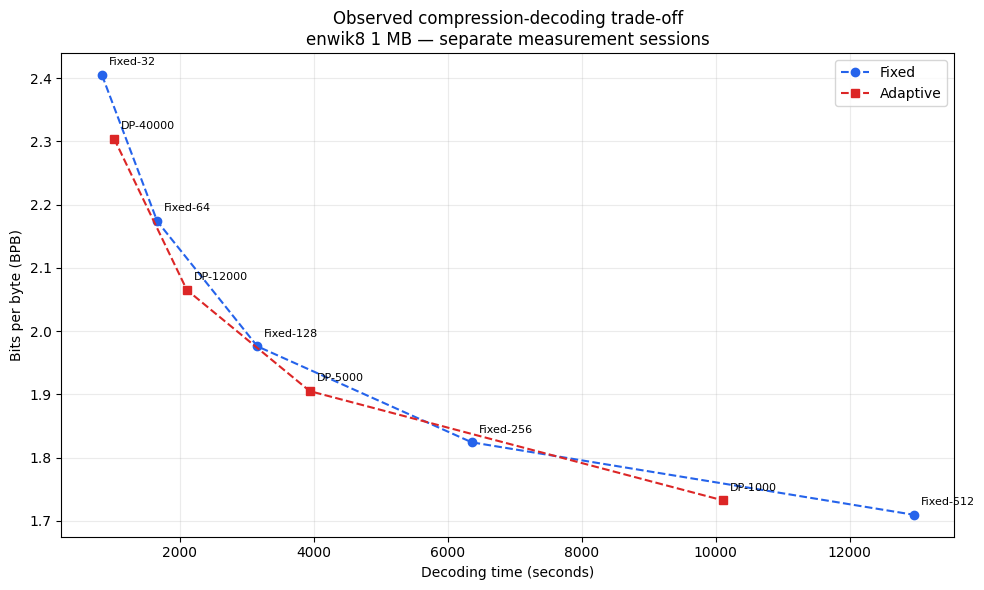

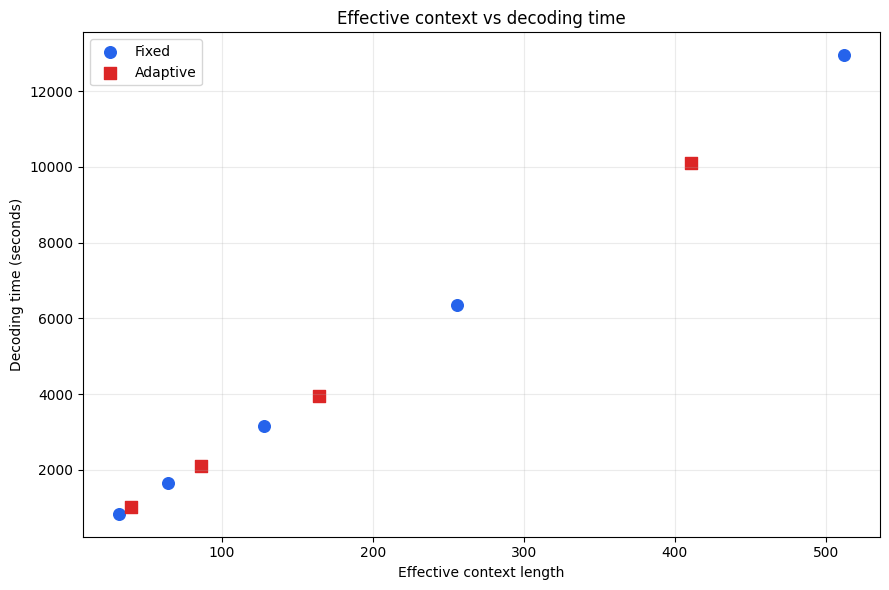

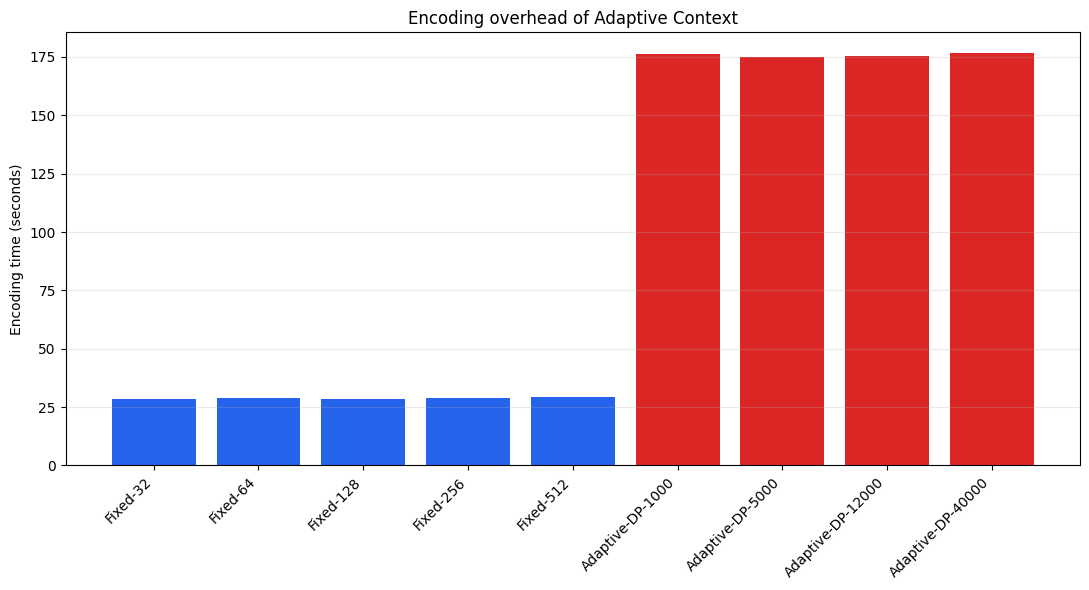

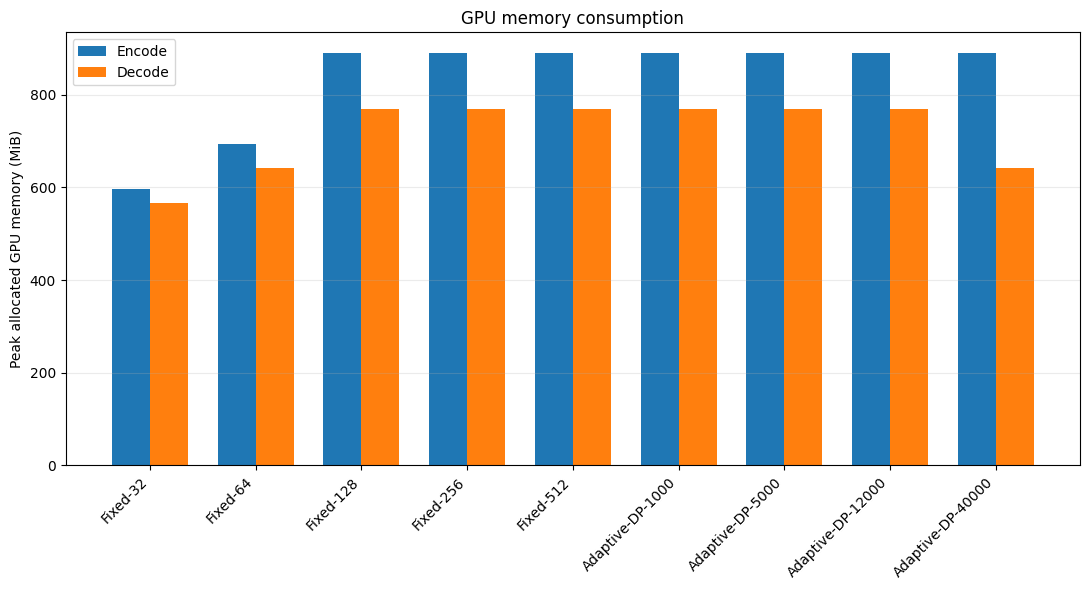

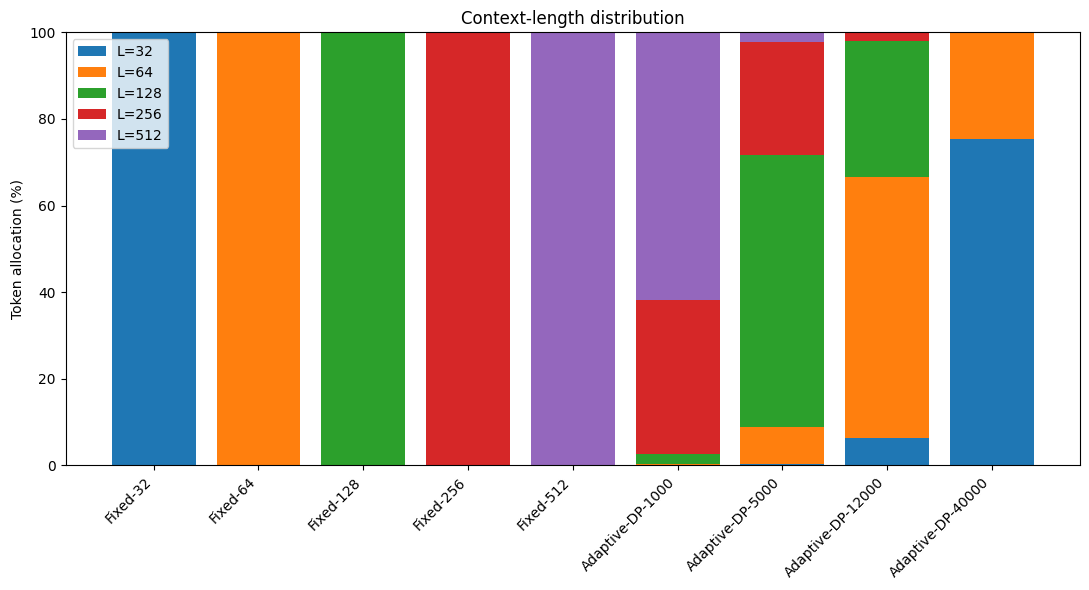

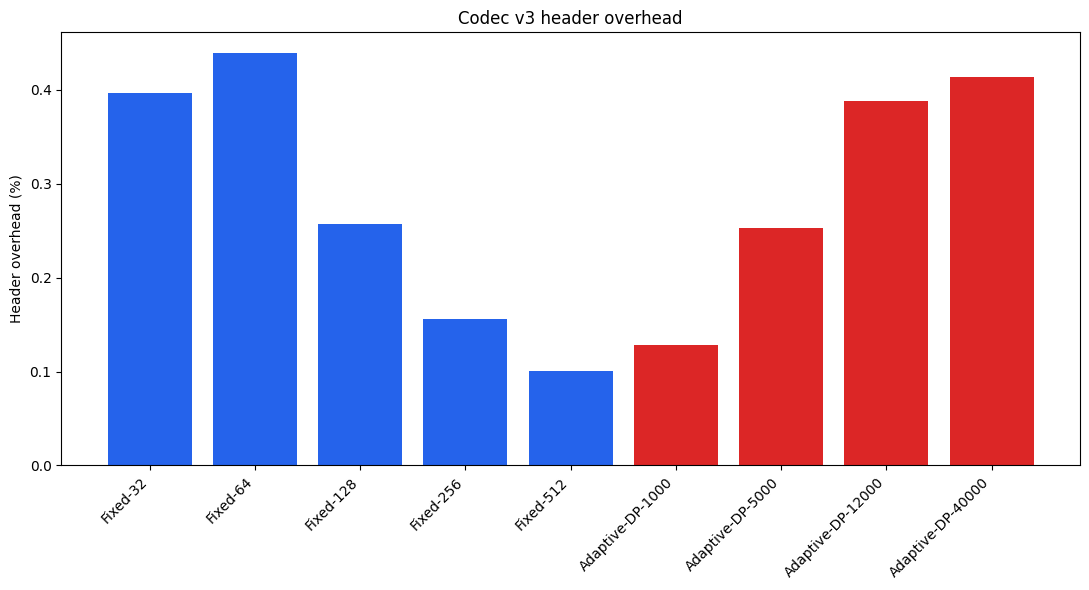

=== STAGE 6A FINAL SUMMARY ===


,method,family,compressed_bytes,ratio,bpb,effective_L,encode_seconds,decode_seconds,decode_minutes,total_seconds,encode_peak_mib,decode_peak_mib,header_pct,byte_exact,full_decode,observed_pareto,encode_session_id,decode_session_id
0,Fixed-32,Fixed,300576,3.3269,2.4046,32.0000,28.5648,838.8019,13.9800,867.3668,597.2168,566.9624,0.3972,True,PASS,True,Stage6A-Session01,Stage6A-Session01
1,Fixed-64,Fixed,271704,3.6805,2.1736,63.9964,28.9751,1662.7138,27.7119,1691.6889,693.5371,640.8750,0.4394,True,PASS,True,Stage6A-Session01,Stage6A-Session01
2,Fixed-128,Fixed,246976,4.0490,1.9758,127.9750,28.5877,3157.6798,52.6280,3186.2675,889.8613,768.5371,0.2571,True,PASS,True,Stage6A-Session01,Stage6A-Session01
3,Fixed-256,Fixed,228006,4.3858,1.8240,255.9320,29.0480,6356.6881,105.9448,6385.7361,889.8613,768.5371,0.1557,True,PASS,True,Stage6A-Session01,Stage6A-Session01
4,Fixed-512,Fixed,213691,4.6797,1.7095,511.8462,29.4712,12950.8678,215.8478,12980.3390,889.8613,768.5371,0.1006,True,PASS,True,Stage6A-Session01,Stage6A-Session01
5,Adaptive-DP-1000,Adaptive,216534,4.6182,1.7323,410.7853,176.2434,10103.9862,168.3998,10280.2296,889.8613,768.5371,0.1284,True,PASS,True,Stage6A-Session01,Stage6A-Session02
6,Adaptive-DP-5000,Adaptive,238128,4.1994,1.9050,164.4922,174.8895,3939.2909,65.6548,4114.1804,889.8613,768.5371,0.2528,True,PASS,True,Stage6A-Session01,Stage6A-Session02
7,Adaptive-DP-12000,Adaptive,258127,3.8741,2.0650,86.0498,175.2941,2104.7104,35.0785,2280.0045,889.8613,768.5371,0.3878,True,PASS,True,Stage6A-Session01,Stage6A-Session02
8,Adaptive-DP-40000,Adaptive,288012,3.4721,2.3041,39.9973,176.7067,1020.1877,17.0031,1196.8944,889.8613,640.8750,0.4142,True,PASS,True,Stage6A-Session01,Stage6A-Session02



=== OBSERVED PARETO POINTS ===


,method,bpb,decode_seconds,decode_session_id
0,Fixed-32,2.4046,838.8019,Stage6A-Session01
1,Fixed-64,2.1736,1662.7138,Stage6A-Session01
2,Fixed-128,1.9758,3157.6798,Stage6A-Session01
3,Fixed-256,1.8240,6356.6881,Stage6A-Session01
4,Fixed-512,1.7095,12950.8678,Stage6A-Session01
5,Adaptive-DP-1000,1.7323,10103.9862,Stage6A-Session02
6,Adaptive-DP-5000,1.9050,3939.2909,Stage6A-Session02
7,Adaptive-DP-12000,2.0650,2104.7104,Stage6A-Session02
8,Adaptive-DP-40000,2.3041,1020.1877,Stage6A-Session02



=== GENERATED FIGURES ===
01_observed_pareto.pdf
01_observed_pareto.png
02_context_vs_decode.pdf
02_context_vs_decode.png
03_encode_time.pdf
03_encode_time.png
04_gpu_memory.pdf
04_gpu_memory.png
05_chunk_distribution.pdf
05_chunk_distribution.png
06_header_overhead.pdf
06_header_overhead.png

Full decode: 9/9
Byte-exact: 9/9
CELL 15 DONE


In [9]:
#Stage 6A — Cell 15: Tổng hợp kết quả và vẽ biểu đồ
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

RESULTS = STAGE / "results"
PLOTS = STAGE / "plots"

PLOTS.mkdir(exist_ok=True)

df = pd.DataFrame(
    json.loads(
        (RESULTS / "decode_1mb.json").read_text()
    )
)

assert len(df) == 9
assert df["byte_exact"].all()
assert df["token_exact"].all()
assert df["full_decode"].eq("PASS").all()

df["family"] = np.where(
    df["method"].str.startswith("Fixed"),
    "Fixed",
    "Adaptive"
)

df["decode_minutes"] = df["decode_seconds"] / 60
df["header_pct"] = df["encode_stats"].apply(
    lambda x: 100 * x["header_bytes"] / x["total_bytes"]
)

# ==================== PARETO ====================

def is_pareto_optimal(i):

    x = df.loc[i, "decode_seconds"]
    y = df.loc[i, "bpb"]

    dominated = (
        (df["decode_seconds"] <= x)
        & (df["bpb"] <= y)
        & (
            (df["decode_seconds"] < x)
            | (df["bpb"] < y)
        )
    )

    return not dominated.any()

df["observed_pareto"] = [
    is_pareto_optimal(i)
    for i in df.index
]

columns = [
    "method",
    "family",
    "compressed_bytes",
    "ratio",
    "bpb",
    "effective_L",
    "encode_seconds",
    "decode_seconds",
    "decode_minutes",
    "total_seconds",
    "encode_peak_mib",
    "decode_peak_mib",
    "header_pct",
    "byte_exact",
    "full_decode",
    "observed_pareto",
    "encode_session_id",
    "decode_session_id"
]

summary = df[columns].copy()

summary.to_csv(
    RESULTS / "stage6A_final_summary.csv",
    index=False
)

summary.to_json(
    RESULTS / "stage6A_final_summary.json",
    orient="records",
    indent=2
)

styles = {
    "Fixed": ("#2563eb", "o"),
    "Adaptive": ("#dc2626", "s")
}

def save_plot(name):

    plt.tight_layout()

    plt.savefig(
        PLOTS / f"{name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.savefig(
        PLOTS / f"{name}.pdf",
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


# FIGURE 1: Pareto

plt.figure(figsize=(10, 6))

for family, (color, marker) in styles.items():

    g = df[df["family"] == family].sort_values(
        "decode_seconds"
    )

    plt.plot(
        g["decode_seconds"],
        g["bpb"],
        color=color,
        marker=marker,
        linestyle="--",
        label=family
    )

    for _, r in g.iterrows():

        plt.annotate(
            r["method"].replace("Adaptive-DP", "DP"),
            (r["decode_seconds"], r["bpb"]),
            xytext=(5, 7),
            textcoords="offset points",
            fontsize=8
        )

plt.xlabel("Decoding time (seconds)")
plt.ylabel("Bits per byte (BPB)")
plt.title(
    "Observed compression-decoding trade-off\n"
    "enwik8 1 MB — separate measurement sessions"
)
plt.grid(alpha=0.25)
plt.legend()

save_plot("01_observed_pareto")


# FIGURE 2: Effective context vs decode

plt.figure(figsize=(9, 6))

for family, (color, marker) in styles.items():

    g = df[df["family"] == family]

    plt.scatter(
        g["effective_L"],
        g["decode_seconds"],
        color=color,
        marker=marker,
        s=70,
        label=family
    )

plt.xlabel("Effective context length")
plt.ylabel("Decoding time (seconds)")
plt.title("Effective context vs decoding time")
plt.grid(alpha=0.25)
plt.legend()

save_plot("02_context_vs_decode")


# FIGURE 3: Encoding time

colors = [
    styles[f][0] for f in df["family"]
]

plt.figure(figsize=(11, 6))

plt.bar(
    df["method"],
    df["encode_seconds"],
    color=colors
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Encoding time (seconds)")
plt.title("Encoding overhead of Adaptive Context")
plt.grid(axis="y", alpha=0.25)

save_plot("03_encode_time")


# FIGURE 4: GPU memory

plt.figure(figsize=(11, 6))

x = np.arange(len(df))
width = 0.36

plt.bar(
    x - width/2,
    df["encode_peak_mib"],
    width,
    label="Encode"
)

plt.bar(
    x + width/2,
    df["decode_peak_mib"],
    width,
    label="Decode"
)

plt.xticks(x, df["method"], rotation=45, ha="right")
plt.ylabel("Peak allocated GPU memory (MiB)")
plt.title("GPU memory consumption")
plt.legend()
plt.grid(axis="y", alpha=0.25)

save_plot("04_gpu_memory")


# FIGURE 5: Chunk distribution

plt.figure(figsize=(11, 6))

bottom = np.zeros(len(df))

for L in [32, 64, 128, 256, 512]:

    # Tỷ lệ token đã padding thuộc mỗi context
    values = df["chunk_counts"].apply(
        lambda c:
        100 * int(c[str(L)]) * L /
        sum(int(k) * int(v) for k, v in c.items())
    ).to_numpy()

    plt.bar(
        df["method"],
        values,
        bottom=bottom,
        label=f"L={L}"
    )

    bottom += values

plt.xticks(rotation=45, ha="right")
plt.ylabel("Token allocation (%)")
plt.title("Context-length distribution")
plt.legend()

save_plot("05_chunk_distribution")


# FIGURE 6: Metadata overhead

plt.figure(figsize=(11, 6))

plt.bar(
    df["method"],
    df["header_pct"],
    color=colors
)

plt.xticks(rotation=45, ha="right")
plt.ylabel("Header overhead (%)")
plt.title("Codec v3 header overhead")

save_plot("06_header_overhead")


# ==================== FINAL SUMMARY ====================

print("=== STAGE 6A FINAL SUMMARY ===")

display(summary.round(4))

print("\n=== OBSERVED PARETO POINTS ===")

display(
    summary[summary["observed_pareto"]][[
        "method",
        "bpb",
        "decode_seconds",
        "decode_session_id"
    ]].round(4)
)

print("\n=== GENERATED FIGURES ===")

for p in sorted(PLOTS.glob("*")):
    print(p.name)

print("\nFull decode: 9/9")
print("Byte-exact: 9/9")
print("CELL 15 DONE")

In [10]:
#Stage 6A — Cell 16: ZIP toàn bộ kết quả
import zipfile
import json
import hashlib
import subprocess
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import FileLink, display

WORK = Path("/kaggle/working")

# ==================== VERIFY RESULTS ====================

results = json.loads(
    (STAGE / "results/decode_1mb.json").read_text()
)

assert len(results) == 9

assert all(
    r["full_decode"] == "PASS"
    and r["byte_exact"]
    and r["token_exact"]
    for r in results
)

for r in results:

    name = r["method"]

    compressed = STAGE / "artifacts" / f"{name}_1mb.fzac"
    decoded = STAGE / "artifacts" / f"{name}_decoded.txt"

    assert sha256_bytes(compressed.read_bytes()) == \
        r["artifact_sha256"]

    assert sha256_bytes(decoded.read_bytes()) == \
        r["original_sha256"]

figures = list((STAGE / "plots").glob("*.png"))
pdfs = list((STAGE / "plots").glob("*.pdf"))

assert len(figures) == 6
assert len(pdfs) == 6

print("Results: 9/9 PASS")
print("Artifacts: PASS")
print("PNG figures:", len(figures))
print("PDF figures:", len(pdfs))

# ==================== SAVE PART 2 CODE ====================

history = get_ipython().user_ns.get("In", [])

(STAGE / "code/notebook_history_part2.py").write_text(
    "\n\n".join(
        f"# Executed input {i}\n{cell}"
        for i, cell in enumerate(history[:-1])
    ),
    encoding="utf-8"
)

# ==================== SAVE FINAL METADATA ====================

final_metadata = {
    "stage": "6A",
    "status": "COMPLETED",
    "saved_at": datetime.now(timezone.utc).isoformat(),
    "git_commit": subprocess.check_output(
        ["git", "-C", str(ROOT), "rev-parse", "HEAD"],
        text=True
    ).strip(),
    "dataset_bytes": len(raw),
    "dataset_sha256": sha256_bytes(raw),
    "tokens": len(tokens),
    "model": "gpt2",
    "codec_version": 3,
    "encode_completed": 9,
    "decode_completed": 9,
    "lossless_pass": 9,
    "measurement_sessions": [
        "Stage6A-Session01",
        "Stage6A-Session02"
    ],
    "png_figures": sorted(p.name for p in figures),
    "pdf_figures": sorted(p.name for p in pdfs),
    "next_stage": "Stage 7 - Decode-Aware Adaptive DP"
}

(STAGE / "results/stage6A_metadata.json").write_text(
    json.dumps(final_metadata, indent=2),
    encoding="utf-8"
)

# ==================== UPDATE README ====================

readme = """# Stage 6A - Full Decode and Observed Pareto

Status: COMPLETED

## Environment

- Model: GPT-2 FP32, SDPA
- GPU: Tesla T4
- PyTorch: 2.10.0+cu128
- Transformers: 5.0.0
- NumPy: 2.0.2
- Codec: Adaptive FineZip v3

## Dataset

- enwik8: first 1,000,000 bytes
- GPT-2 tokens: 286,273
- All methods verified byte-exact and token-exact.

## Completed experiments

- Five fixed context configurations: 32, 64, 128, 256, 512.
- Four adaptive DP configurations:
  lambda = 1000, 5000, 12000, 40000.
- Full decode: 9/9 PASS.
- SHA-256 verification: 9/9 PASS.
- Compression ratio, BPB, encode/decode time,
  GPU memory and header overhead.

## Main results

| Method | Compressed B | Ratio | Encode s | Decode s |
|---|---:|---:|---:|---:|
| Fixed-32 | 300576 | 3.3269 | 28.56 | 838.80 |
| Fixed-64 | 271704 | 3.6805 | 28.98 | 1662.71 |
| Fixed-128 | 246976 | 4.0490 | 28.59 | 3157.68 |
| Fixed-256 | 228006 | 4.3858 | 29.05 | 6356.69 |
| Fixed-512 | 213691 | 4.6797 | 29.47 | 12950.87 |
| Adaptive-DP-1000 | 216534 | 4.6182 | 176.24 | 10103.99 |
| Adaptive-DP-5000 | 238128 | 4.1994 | 174.89 | 3939.29 |
| Adaptive-DP-12000 | 258127 | 3.8741 | 175.29 | 2104.71 |
| Adaptive-DP-40000 | 288012 | 3.4721 | 176.71 | 1020.19 |

## Findings

1. All nine configurations achieved byte-exact lossless
   compression and decompression.
2. Larger context improves compression but increases
   decoding time.
3. Adaptive context provides intermediate operating points.
4. All nine measured points are non-dominated with respect
   to BPB and observed decoding time.
5. Adaptive-DP-1000 increases compressed size by 1.33%
   compared with Fixed-512.
6. Its observed decoding time is 21.98% lower,
   but measurements belong to different Kaggle sessions.
7. Adaptive DP encoding is approximately six times slower
   than Fixed-512.
8. Adaptive superiority at matched measured decoding cost
   has not yet been established.

## Limitations

- Fixed decoding: Session01.
- Adaptive decoding: Session02.
- Cross-session timing comparisons are exploratory.
- Repeated and paired timing measurements are required.
- Pareto analysis does not include encoding time.

## Files

- results/: CSV and JSON measurements and metadata.
- plots/: six figures, each in PNG and PDF.
- code/: executed notebook history.
- artifacts/: compressed and reconstructed files.

## Next stage

Stage 7: hardware-calibrated Decode-Aware Adaptive DP.
"""

(STAGE / "README.md").write_text(
    readme, encoding="utf-8"
)

# ==================== ZIP EVIDENCE ====================

evidence_zip = WORK / "stage6A_final_evidence.zip"

with zipfile.ZipFile(
    evidence_zip, "w", zipfile.ZIP_DEFLATED
) as z:

    for p in sorted(STAGE.rglob("*")):

        if p.is_file() and \
            "artifacts" not in p.relative_to(STAGE).parts:

            z.write(p, p.relative_to(WORK))

# ==================== ZIP ARTIFACTS ====================

artifacts_zip = WORK / "stage6A_final_artifacts.zip"

with zipfile.ZipFile(
    artifacts_zip, "w", zipfile.ZIP_DEFLATED
) as z:

    for p in sorted((STAGE / "artifacts").rglob("*")):

        if p.is_file():

            z.write(p, p.relative_to(WORK))

# ==================== VERIFY ZIP ====================

for path in [evidence_zip, artifacts_zip]:

    with zipfile.ZipFile(path, "r") as z:

        assert z.testzip() is None

        names = z.namelist()

        print(f"\nZIP: {path.name}")
        print("Files:", len(names))
        print("Size:", round(
            path.stat().st_size / 1024**2, 3
        ), "MB")

        if path == evidence_zip:

            png_count = sum(
                n.endswith(".png") for n in names
            )

            pdf_count = sum(
                n.endswith(".pdf") for n in names
            )

            assert png_count == 6
            assert pdf_count == 6

            print("PNG included:", png_count)
            print("PDF included:", pdf_count)

            print("\n=== FIGURES INCLUDED ===")

            for n in names:
                if n.endswith((".png", ".pdf")):
                    print(n)

    print("SHA-256:", sha256_bytes(path.read_bytes()))
    print("Integrity: PASS")

    display(FileLink(path.name))

print("\n=== STAGE 6A COMPLETED ===")
print("Encode: 9/9")
print("Full decode: 9/9")
print("Lossless: 9/9")
print("Figures: 12/12")
print("Next: Stage 7")
print("CELL 16 DONE")

Results: 9/9 PASS
Artifacts: PASS
PNG figures: 6
PDF figures: 6

ZIP: stage6A_final_evidence.zip
Files: 25
Size: 0.812 MB
PNG included: 6
PDF included: 6

=== FIGURES INCLUDED ===
stage6A/plots/01_observed_pareto.pdf
stage6A/plots/01_observed_pareto.png
stage6A/plots/02_context_vs_decode.pdf
stage6A/plots/02_context_vs_decode.png
stage6A/plots/03_encode_time.pdf
stage6A/plots/03_encode_time.png
stage6A/plots/04_gpu_memory.pdf
stage6A/plots/04_gpu_memory.png
stage6A/plots/05_chunk_distribution.pdf
stage6A/plots/05_chunk_distribution.png
stage6A/plots/06_header_overhead.pdf
stage6A/plots/06_header_overhead.png
SHA-256: 7fd7c2882de12f64897c36ab5c72fc784372ea08b252ae202b231691fefc8b11
Integrity: PASS


/kaggle/working/stage6A_final_evidence.zip


ZIP: stage6A_final_artifacts.zip
Files: 20
Size: 5.224 MB
SHA-256: 77b2875c2802471e4e07b48c796d35a11d5b1b048f8d992be3cd0f2a6b116f35
Integrity: PASS


/kaggle/working/stage6A_final_artifacts.zip


=== STAGE 6A COMPLETED ===
Encode: 9/9
Full decode: 9/9
Lossless: 9/9
Figures: 12/12
Next: Stage 7
CELL 16 DONE


In [1]:
#Stage 6A — Cell 1: Clone source và kiểm tra GPU
%cd /kaggle/working

!git clone https://github.com/ThaoTo2806/FineZip28.git
!pip install -q transformers accelerate sentencepiece
!nvidia-smi

!git -C /kaggle/working/FineZip28 rev-parse HEAD

/kaggle/working
Cloning into 'FineZip28'...
remote: Enumerating objects: 218, done.
remote: Counting objects: 100% (143/143), done.
remote: Compressing objects: 100% (120/120), done.
remote: Total 218 (delta 48), reused 109 (delta 21), pack-reused 75 (from 1)
Receiving objects: 100% (218/218), 83.94 MiB | 29.99 MiB/s, done.
Resolving deltas: 100% (60/60), done.
Updating files: 100% (115/115), done.
Sat Nov 21 01:14:44 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=============

In [2]:
#Stage 6A — Cell 2: Kiểm tra dữ liệu và thư viện
from pathlib import Path
import torch
import transformers
import numpy as np
import hashlib
import json

ROOT = Path("/kaggle/working/FineZip28")
INPUT = Path("/kaggle/input/datasets/thothanh28")
STAGE = Path("/kaggle/working/stage6A")

for folder in ["code", "results", "plots", "artifacts"]:
    (STAGE / folder).mkdir(parents=True, exist_ok=True)

print("=== ENVIRONMENT ===")
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("NumPy:", np.__version__)
print("CUDA:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())

print("\n=== SOURCE FILES ===")

files = [
    "update/adaptive_context_finezip_v3.py",
    "update/stage5_tools.py",
    "stage5_session_D.json",
    "adaptive_lambda1000_v3.fzac",
    "notebook/finezip_experiment2/data/enwik8",
    "notebook/finezip_experiment2/data/baseline_1mb.txt"
]

for name in files:
    p = ROOT / name
    print(f"{'OK' if p.exists() else 'MISSING'} | {name}")
    if p.exists():
        print(f"    Size: {p.stat().st_size:,} bytes")

print("\n=== DATASET SHA-256 ===")

data_path = ROOT / "notebook/finezip_experiment2/data/baseline_1mb.txt"
raw = data_path.read_bytes()

print("Original bytes:", len(raw))
print("SHA-256:", hashlib.sha256(raw).hexdigest())

print("\n=== EXISTING KAGGLE INPUT ===")

for p in sorted(INPUT.rglob("*")):
    if p.is_file() and p.suffix in [".json", ".gpz", ".txt"]:
        print(f"{p.relative_to(INPUT)} | {p.stat().st_size:,} B")

print("\n=== OUTPUT FOLDER ===")
print(STAGE)
print("CELL 2 DONE")

=== ENVIRONMENT ===
PyTorch: 2.10.0+cu128
Transformers: 5.0.0
NumPy: 2.0.2
CUDA: 12.8
GPU count: 2

=== SOURCE FILES ===
OK | update/adaptive_context_finezip_v3.py
    Size: 34,234 bytes
OK | update/stage5_tools.py
    Size: 12,684 bytes
OK | stage5_session_D.json
    Size: 1,687 bytes
OK | adaptive_lambda1000_v3.fzac
    Size: 216,534 bytes
OK | notebook/finezip_experiment2/data/enwik8
    Size: 100,000,000 bytes
OK | notebook/finezip_experiment2/data/baseline_1mb.txt
    Size: 1,000,000 bytes

=== DATASET SHA-256 ===
Original bytes: 1000000
SHA-256: 369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad

=== EXISTING KAGGLE INPUT ===
llmzip-ctx512/llmzip_lite_ctx512/0_AC.txt | 142,294 B
llmzip-ctx512/llmzip_lite_ctx512/metrics.json | 178 B
llmzip-lite-ctx128/llmzip_lite_ctx128/0_AC.txt | 156,856 B
llmzip-lite-ctx128/llmzip_lite_ctx128/metrics.json | 177 B
llmzip-lite-ctx256/llmzip_lite_ctx256/0_AC.txt | 145,521 B
llmzip-lite-ctx256/llmzip_lite_ctx256/metrics.json | 177 B
ll

In [3]:
#Stage 6A — Cell 3: Load GPT-2 và kiểm tra tokenizer
import sys
import time
import torch
import numpy as np
from transformers import AutoTokenizer

sys.path.insert(0, str(ROOT / "update"))

import adaptive_context_finezip_v3 as fz
import stage5_tools as s5

torch.cuda.set_device(0)
torch.backends.cuda.matmul.allow_tf32 = False
torch.set_float32_matmul_precision("highest")

print("=== LOAD TOKENIZER ===")

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.model_max_length = 10**9

text = raw.decode("utf-8", errors="strict")

tokens = np.asarray(
    tokenizer.encode(text, add_special_tokens=False),
    dtype=np.int64
)

reconstructed = tokenizer.decode(
    tokens.tolist(),
    clean_up_tokenization_spaces=False
).encode("utf-8")

print("Original bytes:", len(raw))
print("Characters:", len(text))
print("Tokens:", len(tokens))
print("Tokenizer byte-exact:", reconstructed == raw)

assert reconstructed == raw, "Tokenizer roundtrip failed"

print("\n=== LOAD GPT-2 ===")

t0 = time.perf_counter()

lm = fz.HFLM(
    name="gpt2",
    device="cuda:0",
    max_batch_tokens=1024,
    eps=None
)

torch.cuda.synchronize()

print("Model load time:", round(time.perf_counter() - t0, 2), "s")

cfg, env = lm.describe()

print("\n=== MODEL CONFIG ===")
print(json.dumps(cfg, indent=2))

print("\n=== ENVIRONMENT ===")
print(json.dumps(env, indent=2))

print("\n=== EFFECTIVE BATCH PLAN ===")

for L in fz.CTX_SIZES:
    print(f"Context {L:3d} | Batch {lm.batch_size(L, 8)}")

print("\nGPU allocated:",
      round(torch.cuda.memory_allocated(0) / 1024**2, 2),
      "MiB")

print("\nCELL 3 DONE")

=== LOAD TOKENIZER ===


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Model load time: 5.21 s

=== MODEL CONFIG ===
{
  "name": "gpt2",
  "V": 50257,
  "bos": 50256,
  "dtype": "torch.float32",
  "attn": "sdpa",
  "adapter_sha256": null
}

=== ENVIRONMENT ===
{
  "torch": "2.10.0+cu128",
  "cuda": "12.8",
  "gpu": "Tesla T4",
  "tf32": false,
  "matmul_precision": "highest"
}

=== EFFECTIVE BATCH PLAN ===
Context  32 | Batch 8
Context  64 | Batch 8
Context 128 | Batch 8
Context 256 | Batch 4
Context 512 | Batch 2

GPU allocated: 487.46 MiB

CELL 3 DONE


In [4]:
#Stage 6A — Cell 4: Kiểm thử Full Decode và SHA-256
import gc
import time
import hashlib
import json

# Tạo dữ liệu pilot 10 KB, bảo đảm UTF-8 hợp lệ
pilot_raw = raw[:10_000].decode(
    "utf-8", errors="ignore"
).encode("utf-8")

pilot_tokens = np.asarray(
    tokenizer.encode(
        pilot_raw.decode("utf-8"),
        add_special_tokens=False
    ),
    dtype=np.int64
)

print("=== PILOT DATASET ===")
print("Bytes:", len(pilot_raw))
print("Tokens:", len(pilot_tokens))

def sha256_bytes(data):
    return hashlib.sha256(data).hexdigest()

pilot_results = []

policies = [
    ("Fixed-512", fz.FixedPolicy(512)),
    ("Adaptive-DP-1000", fz.DPPolicy(lam=1000))
]

for name, policy in policies:

    print(f"\n=== {name} ===", flush=True)

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(0)
    torch.cuda.synchronize()

    # ENCODE
    t0 = time.perf_counter()

    blob, leaves = fz.encode(
        pilot_tokens,
        lm,
        policy,
        batch=8
    )

    torch.cuda.synchronize()

    encode_s = time.perf_counter() - t0
    encode_peak = torch.cuda.max_memory_allocated(0) / 1024**2

    print("Compressed bytes:", len(blob))
    print("Encode time:", round(encode_s, 3), "s")

    # Lưu artifact
    (STAGE / "artifacts" / f"pilot_{name}.fzac").write_bytes(blob)

    # FULL DECODE
    torch.cuda.reset_peak_memory_stats(0)
    torch.cuda.synchronize()

    t0 = time.perf_counter()

    decoded_tokens = fz.decode(blob, lm)

    torch.cuda.synchronize()

    decode_s = time.perf_counter() - t0
    decode_peak = torch.cuda.max_memory_allocated(0) / 1024**2

    decoded_raw = tokenizer.decode(
        decoded_tokens.tolist(),
        clean_up_tokenization_spaces=False
    ).encode("utf-8")

    token_exact = bool(np.array_equal(
        pilot_tokens, decoded_tokens
    ))

    byte_exact = pilot_raw == decoded_raw

    result = {
        "method": name,
        "original_bytes": len(pilot_raw),
        "tokens": len(pilot_tokens),
        "compressed_bytes": len(blob),
        "ratio": len(pilot_raw) / len(blob),
        "bpb": 8 * len(blob) / len(pilot_raw),
        "encode_seconds": encode_s,
        "decode_seconds": decode_s,
        "encode_peak_mib": encode_peak,
        "decode_peak_mib": decode_peak,
        "token_exact": token_exact,
        "byte_exact": byte_exact,
        "original_sha256": sha256_bytes(pilot_raw),
        "decoded_sha256": sha256_bytes(decoded_raw),
        "chunk_counts": {
            str(L): sum(l == L for _, l in leaves)
            for L in fz.CTX_SIZES
        }
    }

    pilot_results.append(result)

    # Checkpoint ngay sau mỗi cấu hình
    (STAGE / "results" / "pilot_results.json").write_text(
        json.dumps(pilot_results, indent=2)
    )

    print(json.dumps(result, indent=2), flush=True)

    assert token_exact and byte_exact, f"{name}: LOSSLESS FAILED"

print("\n=== CELL 4 DONE ===")

=== PILOT DATASET ===
Bytes: 10000
Tokens: 3679

=== Fixed-512 ===
Compressed bytes: 2887
Encode time: 1.681 s
{
  "method": "Fixed-512",
  "original_bytes": 10000,
  "tokens": 3679,
  "compressed_bytes": 2887,
  "ratio": 3.4638032559750607,
  "bpb": 2.3096,
  "encode_seconds": 1.681389382999896,
  "decode_seconds": 152.52100948300017,
  "encode_peak_mib": 889.861328125,
  "decode_peak_mib": 768.537109375,
  "token_exact": true,
  "byte_exact": true,
  "original_sha256": "321868b6f37a7bc0b1253c7fa04c3823de4a6f4a61f939cd514720d2aef38284",
  "decoded_sha256": "321868b6f37a7bc0b1253c7fa04c3823de4a6f4a61f939cd514720d2aef38284",
  "chunk_counts": {
    "32": 1,
    "64": 1,
    "128": 0,
    "256": 0,
    "512": 7
  }
}

=== Adaptive-DP-1000 ===
Compressed bytes: 2887
Encode time: 2.262 s
{
  "method": "Adaptive-DP-1000",
  "original_bytes": 10000,
  "tokens": 3679,
  "compressed_bytes": 2887,
  "ratio": 3.4638032559750607,
  "bpb": 2.3096,
  "encode_seconds": 2.261655608000183,
  "decode_s

In [5]:
#Stage 6A — Cell 5: Encode toàn bộ cấu hình trên enwik8 1 MB
import gc
import pandas as pd
from collections import Counter

configs = [
    ("Fixed-32", lambda: fz.FixedPolicy(32)),
    ("Fixed-64", lambda: fz.FixedPolicy(64)),
    ("Fixed-128", lambda: fz.FixedPolicy(128)),
    ("Fixed-256", lambda: fz.FixedPolicy(256)),
    ("Fixed-512", lambda: fz.FixedPolicy(512)),
    ("Adaptive-DP-1000", lambda: fz.DPPolicy(lam=1000)),
    ("Adaptive-DP-5000", lambda: fz.DPPolicy(lam=5000)),
    ("Adaptive-DP-12000", lambda: fz.DPPolicy(lam=12000)),
    ("Adaptive-DP-40000", lambda: fz.DPPolicy(lam=40000))
]

result_path = STAGE / "results" / "encode_1mb.json"

encode_results = (
    json.loads(result_path.read_text())
    if result_path.exists() else []
)

for name, make_policy in configs:

    artifact_path = STAGE / "artifacts" / f"{name}_1mb.fzac"

    if (
        artifact_path.exists()
        and any(r["method"] == name for r in encode_results)
    ):
        print(f"SKIP: {name} — already completed")
        continue

    print(f"\n=== {name} ===", flush=True)

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(0)
    torch.cuda.synchronize()

    policy = make_policy()

    t0 = time.perf_counter()

    blob, leaves = fz.encode(
        tokens,
        lm,
        policy,
        batch=8
    )

    torch.cuda.synchronize()

    encode_s = time.perf_counter() - t0
    peak_mib = torch.cuda.max_memory_allocated(0) / 1024**2

    counts = Counter(L for _, L in leaves)

    effective_L = (
        sum(L**2 for _, L in leaves)
        / sum(L for _, L in leaves)
    )

    artifact_path.write_bytes(blob)

    result = {
        "method": name,
        "original_bytes": len(raw),
        "original_sha256": sha256_bytes(raw),
        "tokens": len(tokens),
        "compressed_bytes": len(blob),
        "ratio": len(raw) / len(blob),
        "bpb": 8 * len(blob) / len(raw),
        "encode_seconds": encode_s,
        "encode_peak_mib": peak_mib,
        "effective_L": effective_L,
        "total_chunks": len(leaves),
        "chunk_counts": {
            str(L): counts.get(L, 0)
            for L in fz.CTX_SIZES
        },
        "encode_stats": dict(fz.encode.last_stats),
        "artifact_sha256": sha256_bytes(blob),
        "full_decode": "PENDING"
    }

    encode_results = [
        r for r in encode_results
        if r["method"] != name
    ]

    encode_results.append(result)

    # Lưu checkpoint sau mỗi cấu hình
    result_path.write_text(
        json.dumps(encode_results, indent=2)
    )

    pd.DataFrame(encode_results).to_csv(
        STAGE / "results" / "encode_1mb.csv",
        index=False
    )

    print("Compressed:", len(blob), "bytes")
    print("Ratio:", round(result["ratio"], 4))
    print("Encode:", round(encode_s, 2), "s")
    print("GPU peak:", round(peak_mib, 2), "MiB")
    print("Effective L:", round(effective_L, 2))
    print("Chunks:", dict(sorted(counts.items())))
    print("Artifact saved:", artifact_path.name, flush=True)

print("\n=== ENCODE SUMMARY ===")

display(pd.DataFrame(encode_results)[[
    "method",
    "compressed_bytes",
    "ratio",
    "bpb",
    "encode_seconds",
    "encode_peak_mib",
    "effective_L"
]].round(4))

print("\nCELL 5 DONE")


=== Fixed-32 ===
Compressed: 300576 bytes
Ratio: 3.3269
Encode: 28.56 s
GPU peak: 597.22 MiB
Effective L: 32.0
Chunks: {32: 8947}
Artifact saved: Fixed-32_1mb.fzac

=== Fixed-64 ===
Compressed: 271704 bytes
Ratio: 3.6805
Encode: 28.98 s
GPU peak: 693.54 MiB
Effective L: 64.0
Chunks: {32: 1, 64: 4473}
Artifact saved: Fixed-64_1mb.fzac

=== Fixed-128 ===
Compressed: 246976 bytes
Ratio: 4.049
Encode: 28.59 s
GPU peak: 889.86 MiB
Effective L: 127.97
Chunks: {32: 1, 64: 1, 128: 2236}
Artifact saved: Fixed-128_1mb.fzac

=== Fixed-256 ===
Compressed: 228006 bytes
Ratio: 4.3858
Encode: 29.05 s
GPU peak: 889.86 MiB
Effective L: 255.93
Chunks: {32: 1, 64: 1, 256: 1118}
Artifact saved: Fixed-256_1mb.fzac

=== Fixed-512 ===
Compressed: 213691 bytes
Ratio: 4.6797
Encode: 29.47 s
GPU peak: 889.86 MiB
Effective L: 511.85
Chunks: {32: 1, 64: 1, 512: 559}
Artifact saved: Fixed-512_1mb.fzac

=== Adaptive-DP-1000 ===
Compressed: 216534 bytes
Ratio: 4.6182
Encode: 176.24 s
GPU peak: 889.86 MiB
Effective 

,method,compressed_bytes,ratio,bpb,encode_seconds,encode_peak_mib,effective_L
0,Fixed-32,300576,3.3269,2.4046,28.5648,597.2168,32.0000
1,Fixed-64,271704,3.6805,2.1736,28.9751,693.5371,63.9964
2,Fixed-128,246976,4.0490,1.9758,28.5877,889.8613,127.9750
3,Fixed-256,228006,4.3858,1.8240,29.0480,889.8613,255.9320
4,Fixed-512,213691,4.6797,1.7095,29.4712,889.8613,511.8462
5,Adaptive-DP-1000,216534,4.6182,1.7323,176.2434,889.8613,410.7853
6,Adaptive-DP-5000,238128,4.1994,1.9050,174.8895,889.8613,164.4922
7,Adaptive-DP-12000,258127,3.8741,2.0650,175.2941,889.8613,86.0498
8,Adaptive-DP-40000,288012,3.4721,2.3041,176.7067,889.8613,39.9973



CELL 5 DONE


In [6]:
#Stage 6A — Cell 6: Full Decode Fixed-32
import gc
import time
import pandas as pd

def full_decode_benchmark(name):

    artifact_path = STAGE / "artifacts" / f"{name}_1mb.fzac"
    result_path = STAGE / "results" / "decode_1mb.json"

    results = (
        json.loads(result_path.read_text())
        if result_path.exists() else []
    )

    blob = artifact_path.read_bytes()

    enc = next(
        r for r in encode_results
        if r["method"] == name
    )

    assert sha256_bytes(blob) == enc["artifact_sha256"], \
        "Artifact checksum mismatch"

    print(f"=== FULL DECODE: {name} ===", flush=True)
    print("Compressed bytes:", len(blob))
    print("Original bytes:", len(raw))
    print("Effective L:", round(enc["effective_L"], 4))
    print("GPU:", torch.cuda.get_device_name(0))

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(0)
    torch.cuda.synchronize()

    t0 = time.perf_counter()

    decoded_tokens = fz.decode(blob, lm)

    torch.cuda.synchronize()

    decode_s = time.perf_counter() - t0
    peak_mib = torch.cuda.max_memory_allocated(0) / 1024**2

    decoded_raw = tokenizer.decode(
        decoded_tokens.tolist(),
        clean_up_tokenization_spaces=False
    ).encode("utf-8")

    token_exact = bool(
        np.array_equal(tokens, decoded_tokens)
    )

    byte_exact = raw == decoded_raw

    result = {
        **enc,
        "decode_seconds": decode_s,
        "decode_minutes": decode_s / 60,
        "decode_peak_mib": peak_mib,
        "decode_bytes_per_second": len(raw) / decode_s,
        "decoded_bytes": len(decoded_raw),
        "decoded_tokens": len(decoded_tokens),
        "token_exact": token_exact,
        "byte_exact": byte_exact,
        "decoded_sha256": sha256_bytes(decoded_raw),
        "full_decode": "PASS" if token_exact and byte_exact else "FAIL",
        "total_seconds": enc["encode_seconds"] + decode_s,
        "gpu_id": 0,
        "gpu_name": torch.cuda.get_device_name(0)
    }

    results = [
        r for r in results
        if r["method"] != name
    ]

    results.append(result)

    result_path.write_text(
        json.dumps(results, indent=2)
    )

    pd.DataFrame(results).to_csv(
        STAGE / "results" / "decode_1mb.csv",
        index=False
    )

    (STAGE / "artifacts" / f"{name}_decoded.txt").write_bytes(
        decoded_raw
    )

    print("\n=== DECODE RESULT ===")
    print(json.dumps(result, indent=2))

    print("\nCheckpoint saved:", result_path)
    print("STATUS:", result["full_decode"])

    assert token_exact and byte_exact, "LOSSLESS FAILED"

    return result


fixed32_result = full_decode_benchmark("Fixed-32")

print("\nCELL 6 DONE")

=== FULL DECODE: Fixed-32 ===
Compressed bytes: 300576
Original bytes: 1000000
Effective L: 32.0
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Fixed-32",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 300576,
  "ratio": 3.326945597785585,
  "bpb": 2.404608,
  "encode_seconds": 28.56481875999998,
  "encode_peak_mib": 597.216796875,
  "effective_L": 32.0,
  "total_chunks": 8947,
  "chunk_counts": {
    "32": 8947,
    "64": 0,
    "128": 0,
    "256": 0,
    "512": 0
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 300576,
    "header_bytes": 1194,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "f483d631de1800b370d20231b2105b04da61a313c659ac31ba46943587d61897",
  "full_decode": "PASS",
  "decode_seconds": 838.8019440199

In [7]:
#Stage 6A — Cell 7: Full Decode Fixed-64
fixed64_result = full_decode_benchmark("Fixed-64")

print("\nCELL 7 DONE")

=== FULL DECODE: Fixed-64 ===
Compressed bytes: 271704
Original bytes: 1000000
Effective L: 63.9964
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Fixed-64",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 271704,
  "ratio": 3.680475811912964,
  "bpb": 2.173632,
  "encode_seconds": 28.975073810999675,
  "encode_peak_mib": 693.537109375,
  "effective_L": 63.99642338213926,
  "total_chunks": 4474,
  "chunk_counts": {
    "32": 1,
    "64": 4473,
    "128": 0,
    "256": 0,
    "512": 0
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 271704,
    "header_bytes": 1194,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "530fb244b3cd39c28b8298b81bad5eeefc44790a67596fa0666d35a6b46d0ac5",
  "full_decode": "PASS",
  "decode_seconds

In [8]:
#Stage 6A — Cell 8: Full Decode Fixed-128
fixed128_result = full_decode_benchmark("Fixed-128")

print("\nCELL 8 DONE")

=== FULL DECODE: Fixed-128 ===
Compressed bytes: 246976
Original bytes: 1000000
Effective L: 127.975
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Fixed-128",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 246976,
  "ratio": 4.048976418761337,
  "bpb": 1.975808,
  "encode_seconds": 28.58769588000041,
  "encode_peak_mib": 889.861328125,
  "effective_L": 127.97496367497486,
  "total_chunks": 2238,
  "chunk_counts": {
    "32": 1,
    "64": 1,
    "128": 2236,
    "256": 0,
    "512": 0
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 246976,
    "header_bytes": 635,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "ad9cd2eb4579ba59504ef54b625bc13e70495175e5cbacc0eb8d2f455386ad7b",
  "full_decode": "PASS",
  "decode_second

In [9]:
#Stage 6A — Cell 9: Full Decode Fixed-256
fixed256_result = full_decode_benchmark("Fixed-256")

print("\nCELL 9 DONE")

=== FULL DECODE: Fixed-256 ===
Compressed bytes: 228006
Original bytes: 1000000
Effective L: 255.932
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Fixed-256",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 228006,
  "ratio": 4.385849495188723,
  "bpb": 1.824048,
  "encode_seconds": 29.048009322000325,
  "encode_peak_mib": 889.861328125,
  "effective_L": 255.93204426064602,
  "total_chunks": 1120,
  "chunk_counts": {
    "32": 1,
    "64": 1,
    "128": 0,
    "256": 1118,
    "512": 0
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 228006,
    "header_bytes": 355,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "336556a76aa79f26552ab28a713849d69dda6108f04dfa120a07faef7a911340",
  "full_decode": "PASS",
  "decode_secon

In [10]:
#Stage 6A — Cell 10: Full Decode Fixed-512
fixed512_result = full_decode_benchmark("Fixed-512")

print("\nCELL 10 DONE")

=== FULL DECODE: Fixed-512 ===
Compressed bytes: 213691
Original bytes: 1000000
Effective L: 511.8462
GPU: Tesla T4

=== DECODE RESULT ===
{
  "method": "Fixed-512",
  "original_bytes": 1000000,
  "original_sha256": "369b688978f649681136198fb96db14c1616756260c55fb4b65e9bc049552cad",
  "tokens": 286273,
  "compressed_bytes": 213691,
  "ratio": 4.679654267142744,
  "bpb": 1.709528,
  "encode_seconds": 29.471210960000008,
  "encode_peak_mib": 889.861328125,
  "effective_L": 511.8462054319884,
  "total_chunks": 561,
  "chunk_counts": {
    "32": 1,
    "64": 1,
    "128": 0,
    "256": 0,
    "512": 559
  },
  "encode_stats": {
    "escapes": 0,
    "escape_pct": 0.0,
    "esc_bytes": 0,
    "total_bytes": 213691,
    "header_bytes": 215,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "eps": 0.0
  },
  "artifact_sha256": "aa5314f7e929ca94aa1a2ed3b72f55e6751fe6263a8e35eab8c054a0de0af486",
  "full_decode": "PASS",
  "decode_seconds

In [11]:
#Stage 6A — Cell 10.1: ZIP checkpoint (Part 1)
import json
import hashlib
import zipfile
import subprocess
from pathlib import Path
from datetime import datetime, timezone
from IPython.display import FileLink, display

# ==================== CHECK CHECKPOINT ====================

encode_data = json.loads(
    (STAGE / "results/encode_1mb.json").read_text()
)

decode_data = json.loads(
    (STAGE / "results/decode_1mb.json").read_text()
)

assert len(encode_data) == 9
assert len(decode_data) == 5

assert all(
    r["full_decode"] == "PASS"
    and r["byte_exact"]
    and r["token_exact"]
    for r in decode_data
)

# Kiểm tra toàn bộ 9 artifact
for r in encode_data:
    p = STAGE / "artifacts" / f'{r["method"]}_1mb.fzac'

    assert p.exists(), f"Missing: {p.name}"

    assert hashlib.sha256(p.read_bytes()).hexdigest() == \
        r["artifact_sha256"], f"Checksum mismatch: {p.name}"

print("All checkpoints verified: PASS")

# ==================== SAVE SESSION METADATA ====================

metadata = {
    "stage": "6A",
    "part": 1,
    "session_id": "Stage6A-Session01",
    "saved_at": datetime.now(timezone.utc).isoformat(),
    "git_commit": subprocess.check_output(
        ["git", "-C", str(ROOT), "rev-parse", "HEAD"],
        text=True
    ).strip(),
    "model_config": cfg,
    "environment": env,
    "transformers_version": transformers.__version__,
    "numpy_version": np.__version__,
    "original_bytes": len(raw),
    "original_sha256": sha256_bytes(raw),
    "tokens": len(tokens),
    "encode_completed": 9,
    "full_decode_completed": [
        r["method"] for r in decode_data
    ],
    "pending": [
        r["method"] for r in encode_data
        if r["method"] not in {
            d["method"] for d in decode_data
        }
    ],
    "next_cell": 11
}

(STAGE / "results/session_part1.json").write_text(
    json.dumps(metadata, indent=2)
)

# Lưu lại các cell đã chạy để tái lập
history = get_ipython().user_ns.get("In", [])

(STAGE / "code/notebook_history.py").write_text(
    "\n\n".join(
        f"# Executed input {i}\n{cell}"
        for i, cell in enumerate(history[:-1])
    ),
    encoding="utf-8"
)

# README tạm thời
readme = """# Stage 6A - Part 1

Status: PARTIALLY COMPLETED

Dataset: enwik8, first 1,000,000 bytes.
Model: GPT-2 FP32.
GPU: Tesla T4.
Codec: FineZip Adaptive v3.

Completed:
- Tokenizer byte-exact verification.
- 10 KB pilot full decode.
- Encoding all 9 configurations.
- Full decoding all 5 Fixed configurations.
- SHA-256 verification passed for all 5 Fixed configurations.

Pending:
- Adaptive-DP-1000
- Adaptive-DP-5000
- Adaptive-DP-12000
- Adaptive-DP-40000
- Final Pareto analysis.

Resume from Cell 11.
Do not repeat completed experiments.

Timing across different Kaggle sessions must be
identified separately when reporting results.
"""

(STAGE / "README.md").write_text(
    readme, encoding="utf-8"
)

# ==================== CREATE ZIP FILES ====================

WORK = Path("/kaggle/working")

evidence_zip = WORK / "stage6A_part1_evidence.zip"
artifacts_zip = WORK / "stage6A_part1_artifacts.zip"

# ZIP 1: Evidence, code, results, README
with zipfile.ZipFile(
    evidence_zip, "w", zipfile.ZIP_DEFLATED
) as z:
    for p in sorted(STAGE.rglob("*")):
        if p.is_file() and "artifacts" not in p.relative_to(STAGE).parts:
            z.write(p, p.relative_to(WORK))

# ZIP 2: Artifacts dùng cho session tiếp theo
with zipfile.ZipFile(
    artifacts_zip, "w", zipfile.ZIP_DEFLATED
) as z:
    for p in sorted((STAGE / "artifacts").rglob("*")):
        if p.is_file():
            z.write(p, p.relative_to(WORK))

# ==================== VERIFY ZIP FILES ====================

for path in [evidence_zip, artifacts_zip]:

    with zipfile.ZipFile(path, "r") as z:
        assert z.testzip() is None

    print(f"\nZIP: {path.name}")
    print(f"Size: {path.stat().st_size / 1024**2:.3f} MB")
    print("SHA-256:", sha256_bytes(path.read_bytes()))
    print("Integrity: PASS")

    display(FileLink(path.name))

print("\n=== COMPLETED ===")
print("Encode: 9/9")
print("Full decode: 5/9")
print("Progress: 55.56%")
print("Next cell: 11 — Adaptive-DP-1000")
print("CHECKPOINT READY")

All checkpoints verified: PASS

ZIP: stage6A_part1_evidence.zip
Size: 0.011 MB
SHA-256: 6f98363ea3c40788c414641dbacf3a44e7850bfaee3cb62004e4c1f3eabf3293
Integrity: PASS


/kaggle/working/stage6A_part1_evidence.zip


ZIP: stage6A_part1_artifacts.zip
Size: 3.863 MB
SHA-256: 24599ba453c15c614db412e5be62f34cbd113e18ab92bce1d9a8bfaec1bf4003
Integrity: PASS


/kaggle/working/stage6A_part1_artifacts.zip


=== COMPLETED ===
Encode: 9/9
Full decode: 5/9
Progress: 55.56%
Next cell: 11 — Adaptive-DP-1000
CHECKPOINT READY


In [1]:
%cd /kaggle/working

!git clone https://github.com/ThaoTo2806/FineZip28.git
!pip install -q transformers accelerate sentencepiece
!nvidia-smi

/kaggle/working
Cloning into 'FineZip28'...
remote: Enumerating objects: 206, done.
remote: Counting objects: 100% (131/131), done.
remote: Compressing objects: 100% (108/108), done.
remote: Total 206 (delta 44), reused 101 (delta 21), pack-reused 75 (from 1)
Receiving objects: 100% (206/206), 83.79 MiB | 28.95 MiB/s, done.
Resolving deltas: 100% (56/56), done.
Updating files: 100% (108/108), done.
Thu Oct  8 02:39:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=============

Giai đoạn 5D Phiên D: đo giải nén trong cùng session

In [5]:
#Cell D1: Import và load codec
import sys
import gc
import time
import json
import numpy as np
import torch

sys.path.insert(0, "/kaggle/working/FineZip28/update")

import adaptive_context_finezip_v3 as fz

print("Loaded:", fz.__file__)
print("FILE_VERSION:", fz.FILE_VERSION)

assert fz.FILE_VERSION == 3

Loaded: /kaggle/working/FineZip28/update/adaptive_context_finezip_v3.py
FILE_VERSION: 3


In [6]:
#Cell D2: Đọc dữ liệu và tokenize
from pathlib import Path
from transformers import AutoTokenizer

data_path = Path(
    "/kaggle/working/FineZip28/"
    "notebook/finezip_experiment3.5/data/baseline_1mb.txt"
)

original_text = data_path.read_text(encoding="utf-8")

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.model_max_length = 10**9

original_tokens = np.asarray(
    tokenizer(original_text)["input_ids"],
    dtype=np.int64,
)

print({
    "bytes": len(original_text.encode("utf-8")),
    "tokens": len(original_tokens),
})

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

{'bytes': 1000000, 'tokens': 286273}


In [7]:
#Cell D3: Load GPT-2 base
lm_base = fz.HFLM(
    "gpt2",
    device="cuda",
    max_batch_tokens=1024,
)

lm_base.eps = None

print(lm_base.describe())

model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

({'name': 'gpt2', 'V': 50257, 'bos': 50256, 'dtype': 'torch.float32', 'attn': 'sdpa', 'adapter_sha256': None}, {'torch': '2.10.0+cu128', 'cuda': '12.8', 'gpu': 'Tesla T4', 'tf32': False, 'matmul_precision': 'highest'})


In [8]:
#Cell D4: Hàm đo decode
def measure_decode(blob, model, tokens, name):
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()

    recovered = fz.decode(
        blob,
        model,
    )

    torch.cuda.synchronize()

    decode_seconds = time.perf_counter() - start
    peak_mib = torch.cuda.max_memory_allocated() / 1024**2
    lossless = np.array_equal(recovered, tokens)

    result = {
        "name": name,
        "compressed_bytes": len(blob),
        "decode_seconds": decode_seconds,
        "decode_peak_mib": peak_mib,
        "lossless": bool(lossless),
        "blob_info": fz.inspect_blob(blob),
    }

    print(json.dumps(result, indent=2, default=str))
    return result

In [9]:
#Cell D5: Tạo lại và kiểm tra Fixed-512
torch.cuda.empty_cache()

start = time.perf_counter()

fixed512_blob, fixed512_leaves = fz.encode(
    original_tokens,
    lm_base,
    fz.FixedPolicy(512),
    batch=8,
)

torch.cuda.synchronize()

fixed512_encode_seconds = time.perf_counter() - start

fixed512_quick = fz.quick_check(
    fixed512_blob,
    lm_base,
    original_tokens,
    groups_per_L=3,
)

print({
    "encode_seconds": fixed512_encode_seconds,
    "compressed_bytes": len(fixed512_blob),
    "quick_check": bool(fixed512_quick),
    "chunk_counts": {
        L: sum(length == L for _, length in fixed512_leaves)
        for L in fz.CTX_SIZES
    },
})

quick_check: OK
{'encode_seconds': 27.749200809000058, 'compressed_bytes': 213691, 'quick_check': True, 'chunk_counts': {32: 1, 64: 1, 128: 0, 256: 0, 512: 559}}


In [10]:
#Cell D6: Tạo lại và kiểm tra Adaptive-DP-1000
torch.cuda.empty_cache()

start = time.perf_counter()

adaptive1000_blob, adaptive1000_leaves = fz.encode(
    original_tokens,
    lm_base,
    fz.DPPolicy(lam=1000),
    batch=8,
)

torch.cuda.synchronize()

adaptive1000_encode_seconds = time.perf_counter() - start

adaptive1000_quick = fz.quick_check(
    adaptive1000_blob,
    lm_base,
    original_tokens,
    groups_per_L=3,
)

print({
    "encode_seconds": adaptive1000_encode_seconds,
    "compressed_bytes": len(adaptive1000_blob),
    "quick_check": bool(adaptive1000_quick),
    "chunk_counts": {
        L: sum(length == L for _, length in adaptive1000_leaves)
        for L in fz.CTX_SIZES
    },
})

quick_check: OK
{'encode_seconds': 184.33649530399998, 'compressed_bytes': 216534, 'quick_check': True, 'chunk_counts': {32: 1, 64: 17, 128: 50, 256: 397, 512: 346}}


In [14]:
# Cell D6.5: Lưu Adaptive-DP-1000 blob

from pathlib import Path

save_dir = Path("/kaggle/working/finezip_saved")
save_dir.mkdir(parents=True, exist_ok=True)

adaptive_blob_path = save_dir / "adaptive1000_blob.bin"

adaptive_blob_path.write_bytes(adaptive1000_blob)

print({
    "path": str(adaptive_blob_path),
    "bytes": adaptive_blob_path.stat().st_size,
})


{'path': '/kaggle/working/finezip_saved/adaptive1000_blob.bin', 'bytes': 216534}


In [15]:
#Bạn nên lưu thêm metadata để sau này biết blob được tạo bằng cấu hình nào:

metadata = {
    "name": "Base-Adaptive-DP-1000",
    "file_version": int(fz.FILE_VERSION),
    "compressed_bytes": len(adaptive1000_blob),
    "original_tokens": len(original_tokens),
    "original_bytes": len(original_text.encode("utf-8")),
    "policy": "DPPolicy(lam=1000)",
    "model": "gpt2",
    "batch": 8,
}

(save_dir / "adaptive1000_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print(json.dumps(metadata, indent=2))

{
  "name": "Base-Adaptive-DP-1000",
  "file_version": 3,
  "compressed_bytes": 216534,
  "original_tokens": 286273,
  "original_bytes": 1000000,
  "policy": "DPPolicy(lam=1000)",
  "model": "gpt2",
  "batch": 8
}


In [11]:
#Cell D7: Decode Fixed-512
decode_fixed512 = measure_decode(
    fixed512_blob,
    lm_base,
    original_tokens,
    "Base-Fixed-512",
)

{
  "name": "Base-Fixed-512",
  "compressed_bytes": 213691,
  "decode_seconds": 13621.773218485,
  "decode_peak_mib": 768.537109375,
  "lossless": true,
  "blob_info": {
    "version": 3,
    "n_tokens": 286273,
    "eps": 0.0,
    "n_escapes": 0,
    "batch_plan": {
      "32": 8,
      "64": 8,
      "128": 8,
      "256": 4,
      "512": 2
    },
    "chunk_counts": {
      "32": 1,
      "64": 1,
      "128": 0,
      "256": 0,
      "512": 559
    },
    "env": {
      "cuda": "12.8",
      "gpu": "Tesla T4",
      "matmul_precision": "highest",
      "tf32": false,
      "torch": "2.10.0+cu128"
    },
    "bytes": 213691
  }
}


In [ ]:
# Cell D8: Load Adaptive-DP-1000 blob từ Kaggle Dataset

from pathlib import Path

blob_path = Path(
    "/kaggle/input/finezip-adaptive1000-result/"
    "adaptive1000_blob.bin"
)

adaptive1000_blob = blob_path.read_bytes()

print({
    "blob_path": str(blob_path),
    "compressed_bytes": len(adaptive1000_blob),
})

In [ ]:
#Cell D8: Decode Adaptive-DP-1000
decode_adaptive1000 = measure_decode(
    adaptive1000_blob,
    lm_base,
    original_tokens,
    "Base-Adaptive-DP-1000",
)

In [ ]:
%cd /kaggle/working

!git clone https://github.com/ThaoTo2806/FineZip28.git

In [ ]:
!pip install -q transformers accelerate sentencepiece

In [ ]:
!nvidia-smi

In [ ]:
!python /kaggle/working/FineZip28/update/adaptive_context_finezip.py

In [ ]:
from pathlib import Path

root = Path("/kaggle/working/FineZip28")

print("Root exists:", root.exists())

for p in root.rglob("adaptive_context_finezip.py"):
    print("FOUND:", p)


In [ ]:
#chạy GPT-2 trên dữ liệu 1 MB
import sys
import time
import numpy as np

sys.path.insert(0, "/kaggle/working/FineZip28/update")

from adaptive_context_finezip import demo_gpt2

demo_gpt2(
    "/kaggle/working/FineZip28/notebook/finezip_experiment3.5/data/baseline_1mb.txt"
)

In [ ]:
#restart session/kernel để giải phóng VRAM sau OOM, upload lại file đã sử
import sys
sys.path.insert(0, "/kaggle/working/FineZip28/update")

from adaptive_context_finezip import (
    HFLM,
    FeaturePolicy,
    DPPolicy,
    encode,
)

In [ ]:
lm = HFLM(
    "gpt2",
    device="cuda",
    max_batch_tokens=1024,
)

In [ ]:
print("lm:", "OK" if "lm" in globals() else "MISSING")
print("tokens:", "OK" if "tokens" in globals() else "MISSING")
print("decode:", "OK" if "decode" in globals() else "MISSING")
# chạy qua session mới phải kiểm tra

In [ ]:
#load lại token
import numpy as np
from transformers import AutoTokenizer

path = "/kaggle/working/FineZip28/notebook/finezip_experiment3.5/data/baseline_1mb.txt"

text = open(path, encoding="utf-8").read()

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.model_max_length = 10**9

tokens = np.asarray(
    tokenizer(text)["input_ids"],
    dtype=np.int64
)

print("Tokens:", len(tokens))
print("Batch L=32:", lm.batch_size(32, 64))
print("Batch L=512:", lm.batch_size(512, 64))


In [ ]:
#Dùng phiên bản max_batch_tokens=512 để an toàn hơn. Không cần khởi tạo lm lần nữa nếu đã chạy rồi. Tiếp tục bằng cell sau:
import time
import numpy as np
import torch
from transformers import AutoTokenizer

from adaptive_context_finezip import (
    FeaturePolicy,
    DPPolicy,
    encode,
)

path = "/kaggle/working/FineZip28/notebook/finezip_experiment3.5/data/baseline_1mb.txt"
text = open(path, encoding="utf-8").read()

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.model_max_length = 10**9
tokens = np.asarray(tokenizer(text)["input_ids"], dtype=np.int64)

print("Tokens:", len(tokens))
print("Batch L=32:", lm.batch_size(32, 64))
print("Batch L=512:", lm.batch_size(512, 64))

In [ ]:
#Chạy thử Adaptive-Feature trước:
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

policy = FeaturePolicy()

start = time.perf_counter()
blob, leaves = encode(tokens, lm, policy, batch=64)
torch.cuda.synchronize()
elapsed = time.perf_counter() - start

chunk_counts = {
    L: sum(length == L for _, length in leaves)
    for L in [32, 64, 128, 256, 512]
}

result = {
    "policy": "Adaptive-Feature",
    "compressed_bytes": len(blob),
    "ratio": len(text.encode("utf-8")) / len(blob),
    "encode_seconds": elapsed,
    "gpu_peak_mib": torch.cuda.max_memory_allocated() / 1024**2,
    "chunk_counts": chunk_counts,
}

print(result)

In [ ]:
#cell trên chạy thành công, chạy từng DPPolicy, mỗi lần một lambda:
policy = DPPolicy(lam=5000)

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()
blob, leaves = encode(tokens, lm, policy, batch=64)
torch.cuda.synchronize()
elapsed = time.perf_counter() - start

chunk_counts = {
    L: sum(length == L for _, length in leaves)
    for L in [32, 64, 128, 256, 512]
}

print({
    "policy": "Adaptive-DP-5000",
    "compressed_bytes": len(blob),
    "ratio": len(text.encode("utf-8")) / len(blob),
    "encode_seconds": elapsed,
    "gpu_peak_mib": torch.cuda.max_memory_allocated() / 1024**2,
    "chunk_counts": chunk_counts,
})

In [ ]:
#Sau đó thử lần lượt:
for lam in [1000, 5000, 12000, 40000]:
    print("Running lambda =", lam)
    policy = DPPolicy(lam=lam)

    torch.cuda.empty_cache()
    start = time.perf_counter()

    blob, leaves = encode(tokens, lm, policy, batch=64)

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    print({
        "lambda": lam,
        "compressed_bytes": len(blob),
        "ratio": len(text.encode("utf-8")) / len(blob),
        "encode_seconds": elapsed,
        "chunks": {
            L: sum(length == L for _, length in leaves)
            for L in [32, 64, 128, 256, 512]
        },
    })

In [ ]:
#Đúng về cú pháp, nhưng hiện tại blob chỉ chứa kết quả của vòng lặp cuối cùng, tức lambda=40000. Vì vậy đoạn decode đó chỉ kiểm tra DP-40000
blobs = {}
leaves_by_lambda = {}
results = {}

for lam in [1000, 5000, 12000, 40000]:
    print("Running lambda =", lam, flush=True)

    policy = DPPolicy(lam=lam)
    torch.cuda.empty_cache()
    start = time.perf_counter()

    blob, leaves = encode(tokens, lm, policy, batch=64)

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    blobs[lam] = blob
    leaves_by_lambda[lam] = leaves

    results[lam] = {
        "compressed_bytes": len(blob),
        "ratio": len(text.encode("utf-8")) / len(blob),
        "encode_seconds": elapsed,
        "chunks": {
            L: sum(length == L for _, length in leaves)
            for L in [32, 64, 128, 256, 512]
        },
    }

    print(results[lam], flush=True)

Sau đó decode từng policy cần kiểm tra:

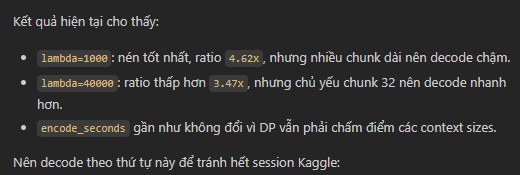

In [ ]:
for lam in [40000, 12000]:
    print("Decoding lambda =", lam, flush=True)

    torch.cuda.empty_cache()
    start = time.perf_counter()

    decoded = decode(blobs[lam], lm, batch=64)

    torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    print(
        "lambda =", lam,
        "decode_seconds =", elapsed,
        "lossless =", np.array_equal(decoded, tokens),
        flush=True,
    )


Sau khi 40000 và 12000 pass, mới cân nhắc decode 5000 và 1000. Không nên decode lại toàn bộ ngay; lambda=1000 có 346 chunk dài 512 và có khả năng mất nhiều giờ.

In [ ]:
# kiểm tra tiếp DP-5000. Chưa cần chạy DP-1000 ngay vì có 346 chunk dài 512, khả năng decode rất lâu.
import json
import time
import torch
import numpy as np

def decode_and_save(lam):
    print("Decoding lambda =", lam, flush=True)

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()
    decoded = decode(blobs[lam], lm, batch=64)
    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    peak_mib = torch.cuda.max_memory_allocated() / 1024**2
    lossless = np.array_equal(decoded, tokens)

    results[lam]["decode_seconds"] = elapsed
    results[lam]["decode_gpu_peak_mib"] = peak_mib
    results[lam]["lossless"] = lossless

    with open("/kaggle/working/adaptive_results.json", "w") as f:
        json.dump(results, f, indent=2)

    print({
        "lambda": lam,
        "decode_seconds": elapsed,
        "gpu_peak_mib": peak_mib,
        "lossless": lossless,
    }, flush=True)

    return decoded

decoded_5000 = decode_and_save(5000)

In [ ]:
import json
import os

# Lưu kết quả benchmark
with open("/kaggle/working/adaptive_results.json", "w") as f:
    json.dump(results, f, indent=2)

# Lưu decoded DP-5000 nếu muốn giữ lại kết quả giải mã
np.save("/kaggle/working/decoded_5000.npy", decoded_5000)

# Kiểm tra file
for path in [
    "/kaggle/working/adaptive_results.json",
    "/kaggle/working/decoded_5000.npy",
]:
    print(path, os.path.getsize(path) / 1024**2, "MiB")

print("\nSaved successfully.")
print(json.dumps(results, indent=2))


In [ ]:
torch.save(blobs, "/kaggle/working/blobs.pt")
print("Saved blobs.pt")


In [ ]:
#ở session mới:
import torch

blobs = torch.load("/kaggle/input/datasets/thothanh28/blobs123/blobs.pt", map_location="cpu")


In [ ]:
print(type(blobs))
print(blobs.keys() if hasattr(blobs, "keys") else "no keys")
print("has 1000:", 1000 in blobs)


In [ ]:
print("blobs:", "OK" if "blobs" in globals() else "MISSING")
print("lm:", "OK" if "lm" in globals() else "MISSING")
print("tokens:", "OK" if "tokens" in globals() else "MISSING")
print("decode:", "OK" if "decode" in globals() else "MISSING")


In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/working/FineZip28"):
    for f in files:
        if f.endswith(".py"):
            path = os.path.join(root, f)
            try:
                with open(path, "r", encoding="utf-8") as fh:
                    content = fh.read()
                if "def decode" in content:
                    print("\nFOUND:", path)
                    for i, line in enumerate(content.splitlines()):
                        if "def decode" in line:
                            print("line", i + 1, ":", line)
            except:
                pass


In [ ]:
#Chạy cell này để import đúng hàm:
import sys
sys.path.insert(0, "/kaggle/working/FineZip28/update")

from adaptive_context_finezip import decode

print("decode:", "OK" if "decode" in globals() else "MISSING")


In [ ]:
#chạy tiếp wrapper decode_and_save:
import json
import time
import torch
import numpy as np

results_path = "/kaggle/working/adaptive_results.json"

# Load kết quả cũ nếu có
try:
    with open(results_path, "r") as f:
        results = json.load(f)
except FileNotFoundError:
    results = {}

def decode_and_save(lam):
    print("Decoding lambda =", lam, flush=True)

    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()

    decoded = decode(blobs[lam], lm, batch=64)

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start
    peak_mib = torch.cuda.max_memory_allocated() / 1024**2
    lossless = np.array_equal(decoded, tokens)

    results.setdefault(str(lam), {})
    results[str(lam)]["decode_seconds"] = elapsed
    results[str(lam)]["decode_gpu_peak_mib"] = peak_mib
    results[str(lam)]["lossless"] = bool(lossless)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=2)

    print({
        "lambda": lam,
        "decode_seconds": elapsed,
        "gpu_peak_mib": peak_mib,
        "lossless": lossless,
    }, flush=True)

    return decoded


In [ ]:
import torch

blobs = torch.load(
    "/kaggle/input/datasets/thothanh28/blobs123/blobs.pt",
    map_location="cpu"
)

print(type(blobs))
print(blobs.keys())
print("has 1000:", 1000 in blobs)


In [ ]:
print("blobs:", "OK" if "blobs" in globals() else "MISSING")
print("lm:", "OK" if "lm" in globals() else "MISSING")
print("tokens:", "OK" if "tokens" in globals() else "MISSING")
print("decode:", "OK" if "decode" in globals() else "MISSING")
print("decode_and_save:", "OK" if "decode_and_save" in globals() else "MISSING")


In [ ]:
#Ở session mới, sau khi load blobs, lm, tokens và định nghĩa decode, chạy thẳng:
decoded_1000 = decode_and_save(1000)

In [ ]:
torch.save(blobs, "/kaggle/working/blobs1.pt")
print("Saved blobs1.pt")


In [ ]:
#lưu kết quả adaptive_results.json
import json

with open("/kaggle/working/adaptive_results.json", "w") as f:
    json.dump(results, f, indent=2)

print("Saved adaptive_results.json")
print(json.dumps(results, indent=2))


In [ ]:
#Chưa ổn. lossless: false nghĩa là bản giải nén lambda=1000 không khôi phục đúng dữ liệu gốc, nên chưa được dùng kết quả này trong paper. Không chạy lại ngay vì decode mất hơn 2,6 giờ.
#Chạy cell chẩn đoán:
decoded = decoded_1000

print("tokens:", tokens.shape, tokens.dtype)
print("decoded:", decoded.shape, decoded.dtype)
print("same length:", len(decoded) == len(tokens))
print("different positions:", np.count_nonzero(decoded != tokens))

bad = np.flatnonzero(decoded != tokens)

if len(bad):
    i = int(bad[0])
    print("first mismatch:", i)
    print("original:", tokens[i - 5:i + 6])
    print("decoded :", decoded[i - 5:i + 6])
else:
    print("LOSSLESS = TRUE")

In [ ]:
#kiểm tra thêm blob và phân bố chunk:
print("blob size:", len(blobs[1000]))
print("saved chunks:", {
    L: sum(length == L for _, length in leaves_by_lambda[1000])
    for L in [32, 64, 128, 256, 512]
})

In [ ]:
from adaptive_context_finezip import flags_to_layout

In [ ]:
#Điểm mismatch bắt đầu đúng tại token 1024, rất có thể là ranh giới giữa các chunk. leaves_by_lambda không tồn tại vì đây là session mới, 
#nhưng có thể khôi phục phân bố chunk trực tiếp từ blob.
import struct
import numpy as np
import bz2

def inspect_blob(blob, n_tokens):
    header_size = struct.calcsize("<4sBBHII")
    magic, version, rank_width, _, n, n_flags = struct.unpack_from(
        "<4sBBHII", blob, 0
    )

    n_flag_bytes = (n_flags + 7) // 8
    flags = np.unpackbits(
        np.frombuffer(blob, dtype=np.uint8, count=n_flag_bytes, offset=header_size)
    )[:n_flags]

    n_pad = -(-n_tokens // 32)
    n_pad *= 32
    leaves = flags_to_layout(flags.tolist(), n_pad)

    counts = {
        L: sum(length == L for _, length in leaves)
        for L in [32, 64, 128, 256, 512]
    }

    containing = [
        (start, length)
        for start, length in leaves
        if start <= 1024 < start + length
    ]

    return {
        "magic": magic,
        "version": version,
        "rank_width": rank_width,
        "n_tokens_header": n,
        "n_flags": n_flags,
        "counts": counts,
        "chunk_containing_1024": containing,
        "first_chunks": leaves[:20],
    }

print(inspect_blob(blobs[1000], len(tokens)))

In [ ]:
from adaptive_context_finezip import run_score, pad_tokens

rank_offset = 0

for chunk_start, chunk_length in leaves:
    if chunk_start == start:
        break
    rank_offset += chunk_length

stored_rank = all_ranks[rank_offset:rank_offset + length]

_, recomputed_rank = run_score(
    pad_tokens(tokens, lm.bos),
    [start],
    length,
    lm,
    batch=1,
)

print("chunk:", start, length)
print("rank offset:", rank_offset)
print("stored rank shape:", stored_rank.shape)
print("recomputed rank shape:", recomputed_rank[0].shape)
print("rank equal:", np.array_equal(stored_rank, recomputed_rank[0]))

diff = np.flatnonzero(stored_rank != recomputed_rank[0])
print("first rank differences:", diff[:20])

In [ ]:
#Bước tiếp theo là giải mã riêng chunk (1024, 512) để xác định lỗi ở lm.pick() hay ở cách decode() ghép các chunk. Chạy cell này:
from adaptive_context_finezip import pad_tokens

padded_tokens = pad_tokens(tokens, lm.bos)

# Giải mã riêng chunk bắt đầu tại 1024
chunk_start = 1024
chunk_length = 512
chunk_ranks = stored_rank

inp = np.full(
    (1, chunk_length),
    lm.bos,
    dtype=np.int64,
)

decoded_chunk = np.zeros(
    (1, chunk_length),
    dtype=np.int64,
)

for pos in range(chunk_length):
    decoded_chunk[:, pos] = lm.pick(
        inp,
        pos,
        chunk_ranks[pos:pos + 1],
    )

    if pos + 1 < chunk_length:
        inp[:, pos + 1] = decoded_chunk[:, pos]

manual_chunk = decoded_chunk[0]

print("manual first tokens:", manual_chunk[:12])
print("original first tokens:", tokens[chunk_start:chunk_start + 12])
print(
    "manual chunk lossless:",
    np.array_equal(manual_chunk, tokens[chunk_start:chunk_start + chunk_length]),
)
print(
    "first manual differences:",
    np.flatnonzero(
        manual_chunk != tokens[chunk_start:chunk_start + chunk_length]
    )[:20],
)

In [ ]:
#Chạy thêm phép kiểm tra token đầu tiên:
single_input = np.full(
    (1, chunk_length),
    lm.bos,
    dtype=np.int64,
)

first_token = lm.pick(
    single_input,
    0,
    chunk_ranks[0:1],
)

print("first token from pick:", first_token)
print("original first token:", tokens[chunk_start])
print("first rank:", chunk_ranks[0])

In [ ]:
#kiểm tra ba chunk đầu bằng đúng rank trong blob:
def decode_one_chunk(chunk_start, chunk_length, chunk_ranks):
    inp = np.full(
        (1, chunk_length),
        lm.bos,
        dtype=np.int64,
    )
    output = np.zeros(
        (1, chunk_length),
        dtype=np.int64,
    )

    for pos in range(chunk_length):
        output[:, pos] = lm.pick(
            inp,
            pos,
            chunk_ranks[pos:pos + 1],
        )

        if pos + 1 < chunk_length:
            inp[:, pos + 1] = output[:, pos]

    return output[0]


def ranks_for_chunk(chunk_start, chunk_length):
    offset = 0

    for start_, length_ in leaves:
        if start_ == chunk_start:
            return all_ranks[offset:offset + length_]

        offset += length_

    raise ValueError(f"chunk not found: {chunk_start}")

In [ ]:
for chunk_start, chunk_length in [
    (0, 512),
    (512, 512),
    (1024, 512),
]:
    chunk_ranks = ranks_for_chunk(chunk_start, chunk_length)
    recovered = decode_one_chunk(
        chunk_start,
        chunk_length,
        chunk_ranks,
    )
    original = tokens[chunk_start:chunk_start + chunk_length]

    print({
        "chunk": (chunk_start, chunk_length),
        "lossless": np.array_equal(recovered, original),
        "first_recovered": recovered[:6].tolist(),
        "first_original": original[:6].tolist(),
    })

In [ ]:
#Trước khi chạy, kiểm tra blob hiện tại có đúng kích thước không:
print(len(blobs[1000]))
print(len(all_ranks))
print(len(leaves))

In [ ]:
decoded_1000 = decode_and_save(1000)

In [ ]:
#Test chính xác chunk 1024 nhưng chạy batch=1 và batch nhiều
# Lấy 2 chunk 512 đầu tiên bắt đầu từ 1024
starts = [1024, 1536]
L = 512

R = np.stack([
    ranks_for_chunk(s, L)
    for s in starts
])

# ---- Batch = 1, từng chunk riêng ----
results_single = []

for k, s in enumerate(starts):
    inp = np.full((1, L), lm.bos, dtype=np.int64)
    out = np.zeros((1, L), dtype=np.int64)

    for p in range(L):
        out[:, p] = lm.pick(
            inp,
            p,
            R[k:k+1, p],
        )

        if p + 1 < L:
            inp[:, p + 1] = out[:, p]

    results_single.append(out[0])

# ---- Batch = 2 ----
inp = np.full((2, L), lm.bos, dtype=np.int64)
out = np.zeros((2, L), dtype=np.int64)

for p in range(L):
    out[:, p] = lm.pick(
        inp,
        p,
        R[:, p],
    )

    if p + 1 < L:
        inp[:, p + 1] = out[:, p]

print("chunk 1024 single:",
      np.array_equal(results_single[0], tokens[1024:1536]))

print("chunk 1536 single:",
      np.array_equal(results_single[1], tokens[1536:2048]))

print("chunk 1024 batched:",
      np.array_equal(out[0], tokens[1024:1536]))

print("chunk 1536 batched:",
      np.array_equal(out[1], tokens[1536:2048]))

print("batch-vs-single chunk 1024:",
      np.array_equal(out[0], results_single[0]))

print("batch-vs-single chunk 1536:",
      np.array_equal(out[1], results_single[1]))


In [ ]:
import sys
import importlib

module_name = "adaptive_context_finezip"

if module_name in sys.modules:
    del sys.modules[module_name]

importlib.invalidate_caches()

from adaptive_context_finezip import (
    HFLM,
    DPPolicy,
    encode,
    quick_check,
    decode,
    calibrate_eps,
)

print("calibrate_eps loaded:", callable(calibrate_eps))

In [ ]:
import adaptive_context_finezip as ac

print(ac.__file__)
print("FILE_VERSION:", ac.FILE_VERSION)
print("has calibrate_eps:", hasattr(ac, "calibrate_eps"))

In [ ]:
lm = HFLM("gpt2", device="cuda", max_batch_tokens=1024)

eps = calibrate_eps(
    lm,
    tokens,
    L=512,
    batches=(1, 2, 4),
)

print("calibrated eps:", eps)
lm.eps = eps

In [ ]:
#chạy pipeline v2:
dp = DPPolicy(1000)

blob, leaves = encode(
    tokens,
    lm,
    dp,
    batch=8,
)

print(encode.last_stats)

ok = quick_check(
    blob,
    lm,
    tokens,
    batch=8,
    groups_per_L=1,
)

print("quick check:", ok)

In [ ]:
import time

start = time.perf_counter()

rec = decode(blob, lm, batch=8)

elapsed = time.perf_counter() - start

print("decode_seconds:", elapsed)
print("lossless:", np.array_equal(rec, tokens))


In [ ]:
# !ls -l /kaggle/input/datasets/thothanh28/lora-gpt2-1mb/lora_gpt2_1mb

🟢 NB01 — FineZip Setup & Dataset

In [ ]:
#Cell 1 — Kiểm tra GPU
!nvidia-smi

In [ ]:
#Cell 2 — Kiểm tra Python
import sys
import torch

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:",
          torch.cuda.get_device_properties(0).total_memory / 1024**3,
          "GB")

In [ ]:
#Cell 3 — Clone FineZip
%cd /kaggle/working

!git clone https://github.com/fazalmittu/finezip.git
%cd /kaggle/working/finezip

!ls -lah

In [ ]:
#Cell 4 — Kiểm tra repository
!find . -maxdepth 2 -type f | head -100

In [ ]:
#Cell 5 — Cài dependency
!pip install -q -r requirements.txt

In [ ]:
!ls

In [ ]:
!sed -n '1,240p' README.md

In [ ]:
!find . -maxdepth 2 -type f | sort

In [ ]:
!sed -n '1,260p' finezip/eval_clean.py

In [ ]:
import importlib.util

packages = [
    "numpy",
    "torch",
    "transformers",
    "bitsandbytes",
    "matplotlib",
    "tqdm"
]

for pkg in packages:
    print(f"{pkg:15} ->", "OK" if importlib.util.find_spec(pkg) else "MISSING")

In [ ]:
!pip install -q bitsandbytes

In [ ]:
#Cell 6 — Kiểm tra package
import torch
import transformers
import peft

print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("peft:", peft.__version__)

In [ ]:
#Cell 7 — Tạo thư mục experiment
from pathlib import Path

ROOT = Path("/kaggle/working/finezip_experiment")

for p in [
    "data",
    "compressed",
    "decompressed",
    "results",
    "logs"
]:
    (ROOT / p).mkdir(parents=True, exist_ok=True)

print(ROOT)

In [ ]:
#Cell 8 — Tạo text nhỏ để test
#Trước khi tải enwik8:
text = """
Machine learning is a method of data analysis.
Machine learning can learn patterns from data.
Deep learning is a branch of machine learning.
Neural networks are widely used in machine learning.
""" * 5000

input_file = ROOT / "data" / "test_small.txt"

input_file.write_text(text)

print("File size:",
      input_file.stat().st_size / 1024**2,
      "MB")

In [ ]:
#Cell 9 — Tạo 1 MB dataset
target_size = 1 * 1024 * 1024

base_text = """
Machine learning is a method of data analysis.
Deep learning uses neural networks.
Large language models can predict the next token.
Text compression removes statistical redundancy.
""" 

text = ""

while len(text.encode("utf-8")) < target_size:
    text += base_text

text = text.encode("utf-8")[:target_size].decode(
    "utf-8",
    errors="ignore"
)

one_mb = ROOT / "data" / "text_1mb.txt"
one_mb.write_text(text)

print("Size:",
      one_mb.stat().st_size / 1024**2,
      "MB")

In [ ]:
#Cell 10 — Checkpoint NB01
assert torch.cuda.is_available()
assert input_file.exists()
assert one_mb.exists()

print("NB01 CHECKPOINT: PASS")

🟢 NB02 — FineZip Reproduction

In [ ]:
#Cell 1 — Load configuration
#Đầu tiên xem README/code để biết command chính xác:
%cd /kaggle/working/finezip

!sed -n '1,300p' README.md

In [ ]:
!find . -maxdepth 3 -type f \
    \( -name "*.py" -o -name "*.sh" \) | sort

In [ ]:
# Cell 2 — Inspect FineZip main configuration

%cd /kaggle/working/finezip

!sed -n '250,440p' finezip/eval_clean.py

In [ ]:
# Cell 2 — Test GPT-2 model loading

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "gpt2"

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Loading model...")
model = AutoModelForCausalLM.from_pretrained(model_name)

print("Model:", model_name)
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    model = model.to("cuda")
    print("Model device:", next(model.parameters()).device)

print("Tokenizer vocab size:", tokenizer.vocab_size)

In [ ]:
# Cell 2 — Test GPT-2 prediction

text = "The quick brown fox jumps over the"

inputs = tokenizer(text, return_tensors="pt").to("cuda")

with torch.no_grad():
    outputs = model(**inputs)

print("Input shape :", inputs["input_ids"].shape)
print("Logits shape:", outputs.logits.shape)

next_token_logits = outputs.logits[:, -1, :]
next_token = torch.argmax(next_token_logits, dim=-1)

print("Predicted token ID:", next_token.item())
print("Predicted token:", tokenizer.decode(next_token))

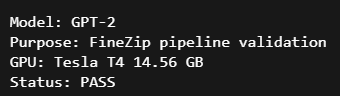

In [ ]:
#Cell 3 — Chuẩn bị file text nhỏ
from pathlib import Path

work_dir = Path("/kaggle/working/finezip_experiment")
data_dir = work_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)

text = """
The quick brown fox jumps over the lazy dog.
FineZip is a language-model-based text compression system.
This experiment is used to validate the compression pipeline.
GPT-2 is used here for pipeline validation before testing larger models.
Lossless compression means that the original text can be recovered exactly.
"""

input_file = data_dir / "text_test.txt"
input_file.write_text(text.strip() + "\n", encoding="utf-8")

print("Created:", input_file)
print("Size:", input_file.stat().st_size, "bytes")
print("Content:")
print(input_file.read_text(encoding="utf-8"))

In [ ]:
# Verify input file

!ls -lh /kaggle/working/finezip_experiment/data/text_test.txt
!cat /kaggle/working/finezip_experiment/data/text_test.txt


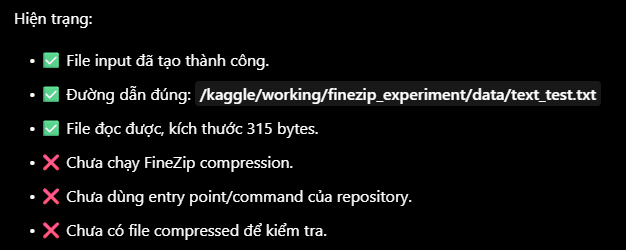

In [ ]:
# Cell 3 — Inspect FineZip compression entry point

%cd /kaggle/working/finezip

!sed -n '413,425p' finezip/eval_clean.py


In [ ]:
# Cell 3 — Prepare FineZip output directories

%cd /kaggle/working/finezip

!mkdir -p zipped
!mkdir -p /kaggle/working/finezip_experiment/results


 nhánh else load GPT-2 lên CPU, trong khi FineZip đưa token lên CUDA.
 Cụ thể hiện tại:

loaded_model = AutoModelForCausalLM.from_pretrained(model)

không có .to("cuda").

Sửa đoạn này

In [ ]:
# Fix GPT-2 device mismatch: move the loaded model to CUDA

from pathlib import Path

path = Path("/kaggle/working/finezip/finezip/eval_clean.py")
src = path.read_text()

old = '''                loaded_model = AutoModelForCausalLM.from_pretrained(model)
                loaded_tokenizer = AutoTokenizer.from_pretrained(model)
                tokenizer_name = model'''

new = '''                loaded_model = AutoModelForCausalLM.from_pretrained(model)
                loaded_model = loaded_model.to("cuda")
                loaded_tokenizer = AutoTokenizer.from_pretrained(model)
                tokenizer_name = model'''

if old in src:
    src = src.replace(old, new)
    path.write_text(src)
    print("✓ Patch applied: GPT-2 will be loaded onto CUDA.")
else:
    print("Target code was not found. No changes made.")


In [ ]:
#Verify
%cd /kaggle/working/finezip

!sed -n '300,310p' finezip/eval_clean.py #Đoạn này xác nhận GPT-2 được chuyển sang CUDA:

In [ ]:
#Bước 1 — Reload module
import importlib
import finezip.eval_clean as eval_clean

importlib.reload(eval_clean)

print("eval_clean reloaded")

In [ ]:
#Tạo thư mục plots
%cd /kaggle/working/finezip

!mkdir -p plots
!mkdir -p zipped

print("plots/ and zipped/ are ready.")


In [ ]:
# Bước 2 — Chạy lại compression
# Cell 3 — Run FineZip compression on the small test file

%cd /kaggle/working/finezip

eval_clean.memory_eval(
    finetuned_models=None,
    original_model_names=["gpt2"],
    context_sizes=[32],
    batch_size=1,
    file_path="/kaggle/working/finezip_experiment/data/text_test.txt",
    save_name="gpt2_test"
)

In [ ]:
#Kiểm tra output compression
%cd /kaggle/working/finezip

!ls -lh zipped/
!ls -lh plots/


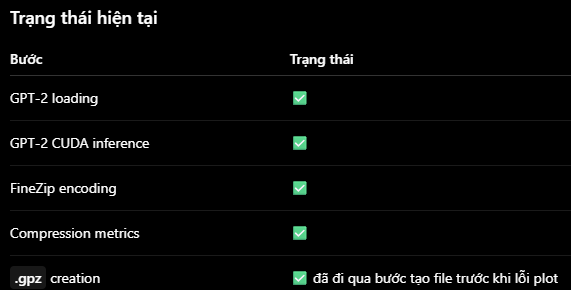

In [ ]:
# Cell 4 — Measure FineZip compression time

import time
import os
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from finezip.eval_clean import ZipModel

model_name = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(model_name)
model = model.to("cuda")
model.eval()

zip_model = ZipModel(
    model_name=model_name,
    tokenizer_name=model_name,
    model=model,
    tokenizer=tokenizer,
    finetuned=False,
    context_size=32,
    batch_size=1
)

input_file = "/kaggle/working/finezip_experiment/data/text_test.txt"
output_file = "/kaggle/working/finezip_experiment/gpt2_32_1.gpz"

start = time.perf_counter()

zip_model.zip_file(input_file, output_file)

if torch.cuda.is_available():
    torch.cuda.synchronize()

compress_time = time.perf_counter() - start

print("Compression time:", compress_time, "seconds")
print("Compressed file:", output_file)
print("Compressed size:", os.path.getsize(output_file), "bytes")


In [ ]:
# Inspect the exact FineZip zip/unzip implementation

%cd /kaggle/working/finezip

!sed -n '195,240p' finezip/eval_clean.py


In [ ]:
from pathlib import Path

p = Path("/kaggle/working/finezip_experiment/gpt2_32_1.gpz")

print("Exists:", p.exists())
print("Size:", p.stat().st_size if p.exists() else "N/A")

if p.exists():
    data = p.read_bytes()
    print("First 32 bytes:", data[:32])


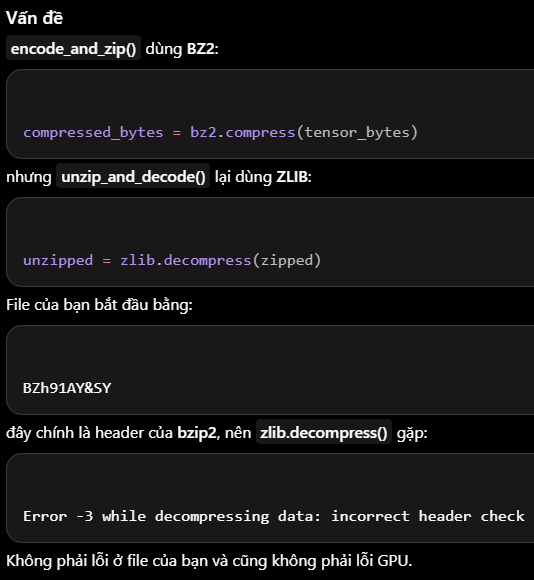

In [ ]:
# Fix FineZip decompression: use bz2 to match encode_and_zip()

from pathlib import Path

path = Path("/kaggle/working/finezip/finezip/eval_clean.py")
src = path.read_text()

old = "unzipped = zlib.decompress(zipped)"
new = "unzipped = bz2.decompress(zipped)"

if old in src:
    src = src.replace(old, new)
    path.write_text(src)
    print("✓ Fixed: zlib.decompress -> bz2.decompress")
else:
    print("Target line not found.")


In [ ]:
%cd /kaggle/working/finezip

!sed -n '210,220p' finezip/eval_clean.py


In [ ]:
#reload module:
import importlib
import finezip.eval_clean as eval_clean

importlib.reload(eval_clean)


In [ ]:
#Quan trọng: zip_model hiện tại được tạo từ class trước khi reload, nên tạo lại ZipModel bằng class mới:
from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(model_name)
model = model.to("cuda")
model.eval()

zip_model = eval_clean.ZipModel(
    model_name=model_name,
    tokenizer_name=model_name,
    model=model,
    tokenizer=tokenizer,
    finetuned=False,
    context_size=32,
    batch_size=1
)


là warning khi load GPT-2, không phải lỗi, và Cell 2 trước đó đã chạy inference thành công. đã tạo lại zip_model bằng class sau khi sửa bz2.decompress, nên chạy Cell 5:

In [ ]:
# Cell 5 — Decompression + lossless verification

import time
from pathlib import Path

input_file = Path(
    "/kaggle/working/finezip_experiment/data/text_test.txt"
)

compressed_file = Path(
    "/kaggle/working/finezip_experiment/gpt2_32_1.gpz"
)

decoded_file = Path(
    "/kaggle/working/finezip_experiment/data/text_test_decoded.txt"
)

start = time.perf_counter()

zip_model.unzip_file(
    str(compressed_file),
    str(decoded_file)
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

decompress_time = time.perf_counter() - start

print("Decompression time:", decompress_time, "seconds")
print("Decoded file:", decoded_file)
#Nếu chạy thành công, chưa kết luận lossless ngay. Sau đó chạy cell verify:

In [ ]:
# Verify lossless reconstruction

original_text = input_file.read_text(encoding="utf-8")
decoded_text = decoded_file.read_text(encoding="utf-8")

print("Original size :", len(original_text.encode("utf-8")), "bytes")
print("Decoded size  :", len(decoded_text.encode("utf-8")), "bytes")
print("Exact match   :", original_text == decoded_text)

if original_text == decoded_text:
    print("PASS — Lossless decompression verified.")
else:
    print("FAIL — Decoded text differs from original.")


In [ ]:
# Cell 6 — So sánh nội dung original và decoded

print("===== ORIGINAL =====")
print(original_text)

print("\n===== DECODED =====")
print(decoded_text)

print("\n===== repr ORIGINAL =====")
print(repr(original_text))

print("\n===== repr DECODED =====")
print(repr(decoded_text))


In [ ]:
# Find the first difference

from itertools import zip_longest

for i, (a, b) in enumerate(zip_longest(original_text, decoded_text, fillvalue="")):
    if a != b:
        print("First difference at character:", i)
        print("Original:", repr(a))
        print("Decoded :", repr(b))
        print("Original context:", repr(original_text[max(0, i-30):i+50]))
        print("Decoded context :", repr(decoded_text[max(0, i-30):i+50]))
        break
else:
    print("No character difference found.")


In [ ]:
#Bước tiếp theo: kiểm tra encode/decode trực tiếp. kiểm tra trước cả BZ2:
# Cell 7 — Test FineZip encode/decode directly

test_text = original_text

print("Original text:")
print(repr(test_text))

tokens = zip_model.text_to_tokens(test_text)

print("\nToken tensor:")
print("Shape:", tokens.shape)
print("Dtype:", tokens.dtype)
print("First tokens:", tokens.flatten()[:20].tolist())

encoded = zip_model.encode(test_text)

print("\nEncoded:")
print("Type:", type(encoded))
print("Length:", len(encoded))
print("First values:", encoded[:20])

decoded_direct = zip_model.decode(
    torch.tensor(encoded)
)

print("\nDirect decoded text:")
print(repr(decoded_direct))

print("\nDirect exact match:", test_text == decoded_direct)


In [ ]:
#Và kiểm tra dtype/giá trị trước khi BZ2
# Cell 8 — Inspect encode dtype and decode assumptions

encoded_tensor = torch.tensor(encoded)

print("Encoded tensor dtype:", encoded_tensor.dtype)
print("Encoded tensor shape:", encoded_tensor.shape)
print("Min:", encoded_tensor.min().item())
print("Max:", encoded_tensor.max().item())

print("\nDecoder reconstruction dtype:")
import array

arr = array.array("H", encoded_tensor.numpy().tobytes())

reconstructed = torch.tensor(arr)

print("Reconstructed dtype:", reconstructed.dtype)
print("Reconstructed shape:", reconstructed.shape)
print("Same length:", len(encoded_tensor) == len(reconstructed))
print("Same values:", torch.equal(encoded_tensor, reconstructed))


In [ ]:
# Cell 9 — Fix FineZip tensor serialization dtype

from pathlib import Path

path = Path("/kaggle/working/finezip/finezip/eval_clean.py")

src = path.read_text()

old = 'unzipped = array.array("H", unzipped)'
new = 'unzipped = array.array("i", unzipped)'

if old in src:
    src = src.replace(old, new)
    path.write_text(src)
    print("✓ Fixed tensor deserialization: uint16 -> int32")
else:
    print("Target line not found.")


In [ ]:
%cd /kaggle/working/finezip

!sed -n '210,220p' finezip/eval_clean.py

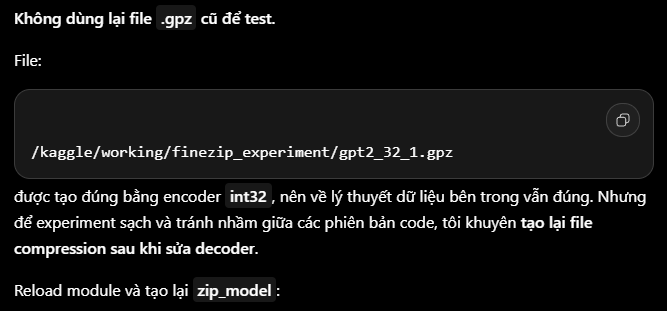

In [ ]:
import importlib
import finezip.eval_clean as eval_clean

importlib.reload(eval_clean)

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

model_name = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(model_name)
model = model.to("cuda")
model.eval()

zip_model = eval_clean.ZipModel(
    model_name=model_name,
    tokenizer_name=model_name,
    model=model,
    tokenizer=tokenizer,
    finetuned=False,
    context_size=32,
    batch_size=1
)
#Sau đó tạo lại .gpz:

In [ ]:
# Re-create compressed file after fixing serialization

input_file = "/kaggle/working/finezip_experiment/data/text_test.txt"
compressed_file = "/kaggle/working/finezip_experiment/gpt2_32_1.gpz"

zip_model.zip_file(
    input_file,
    compressed_file
)

print("Re-created:", compressed_file)


In [ ]:
#Sau đó chạy lại Cell 5
import time
from pathlib import Path

input_file = Path(
    "/kaggle/working/finezip_experiment/data/text_test.txt"
)

compressed_file = Path(
    "/kaggle/working/finezip_experiment/gpt2_32_1.gpz"
)

decoded_file = Path(
    "/kaggle/working/finezip_experiment/data/text_test_decoded.txt"
)

start = time.perf_counter()

zip_model.unzip_file(
    str(compressed_file),
    str(decoded_file)
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

decompress_time = time.perf_counter() - start

print("Decompression time:", decompress_time, "seconds")
print("Decoded file:", decoded_file)


In [ ]:
#verify:
original_text = input_file.read_text(encoding="utf-8")
decoded_text = decoded_file.read_text(encoding="utf-8")

print("Original size :", len(original_text.encode("utf-8")), "bytes")
print("Decoded size  :", len(decoded_text.encode("utf-8")), "bytes")
print("Exact match   :", original_text == decoded_text)

if original_text == decoded_text:
    print("PASS — Lossless decompression verified.")
else:
    print("FAIL — Decoded text differs from original.")


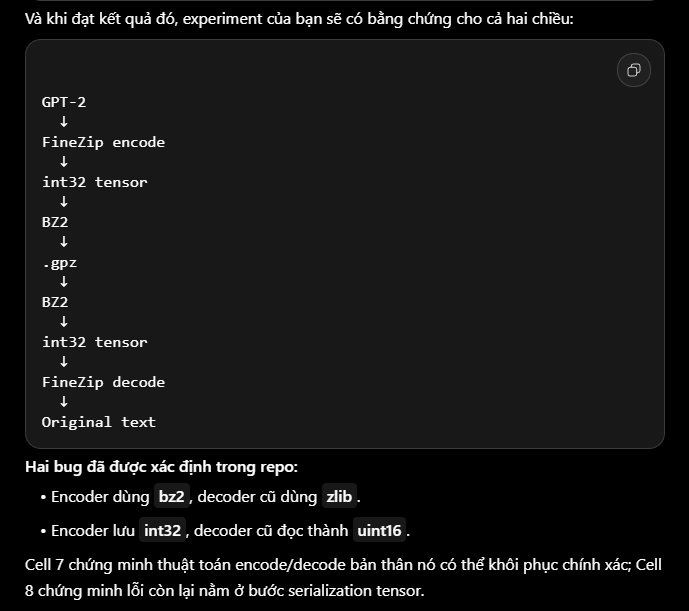

In [ ]:
# Cell 9 — Compression ratio

from pathlib import Path

original_file = Path(
    "/kaggle/working/finezip_experiment/data/text_test.txt"
)

compressed_file = Path(
    "/kaggle/working/finezip_experiment/gpt2_32_1.gpz"
)

original_size = original_file.stat().st_size
compressed_size = compressed_file.stat().st_size

compression_ratio = original_size / compressed_size
compressed_percent = compressed_size / original_size * 100
space_saved = (1 - compressed_size / original_size) * 100

print("Original size     :", original_size, "bytes")
print("Compressed size   :", compressed_size, "bytes")
print("Compression ratio :", compression_ratio)
print("Compressed size % :", compressed_percent, "%")
print("Space saved       :", space_saved, "%")


**Nếu muốn đo peak memory của chính lần compression, nên reset trước khi compression:**

torch.cuda.reset_peak_memory_stats()

**rồi chạy compression, sau đó:**

torch.cuda.synchronize()

print(
    "Peak GPU memory:",
    torch.cuda.max_memory_allocated(0) / 1024**2,
    "MiB"
)

In [ ]:
# Cell 10 — GPU memory measurement

import torch

if torch.cuda.is_available():
    torch.cuda.synchronize()

    allocated = torch.cuda.memory_allocated(0) / 1024**2
    reserved = torch.cuda.memory_reserved(0) / 1024**2
    max_allocated = torch.cuda.max_memory_allocated(0) / 1024**2
    max_reserved = torch.cuda.max_memory_reserved(0) / 1024**2

    print("GPU:", torch.cuda.get_device_name(0))
    print("Current allocated :", allocated, "MiB")
    print("Current reserved  :", reserved, "MiB")
    print("Peak allocated    :", max_allocated, "MiB")
    print("Peak reserved     :", max_reserved, "MiB")
else:
    print("CUDA is not available.")


In [ ]:
# Cell 11 — Save experiment log

import json
from pathlib import Path

log_dir = Path("/kaggle/working/finezip_experiment/logs")
log_dir.mkdir(parents=True, exist_ok=True)

log = {
    "model": "gpt2",
    "purpose": "FineZip pipeline validation",
    "context_size": 32,
    "batch_size": 1,

    "input_file": str(original_file),
    "compressed_file": str(compressed_file),
    "decoded_file": str(decoded_file),

    "original_size_bytes": original_size,
    "compressed_size_bytes": compressed_size,

    "compression_ratio": compression_ratio,

    "compression_time_seconds": 1.1746998789999452,
    "decompression_time_seconds": decompress_time,

    "lossless": original_text == decoded_text,

    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,

    "gpu_peak_memory_mib": (
        torch.cuda.max_memory_allocated(0) / 1024**2
        if torch.cuda.is_available()
        else None
    )
}

log_file = log_dir / "gpt2_test.json"

with open(log_file, "w", encoding="utf-8") as f:
    json.dump(log, f, indent=2)

print("Log saved:", log_file)


In [ ]:
!zip -r /kaggle/working/finezip_experiment.zip /kaggle/working/finezip_experiment

Giai đoạn 2

In [ ]:
#Cell 1 — Tạo baseline_1mb.txt đúng 1,000,000 bytes (Download đúng enwik8 và tạo 1 MB)
from pathlib import Path
import urllib.request

# ====== CONFIG ======
DATA_DIR = Path("/kaggle/working/finezip_experiment/data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

ENWIK8 = DATA_DIR / "enwik8"
DST = DATA_DIR / "baseline_1mb.txt"

TARGET_SIZE = 1_000_000

# ====== DOWNLOAD ENWIK8 ======
URL = "http://mattmahoney.net/dc/enwik8.zip"
ZIP_FILE = DATA_DIR / "enwik8.zip"

if not ENWIK8.exists():
    print("Downloading enwik8...")

    urllib.request.urlretrieve(URL, ZIP_FILE)

    print("Downloaded:", ZIP_FILE)
    print("Size:", ZIP_FILE.stat().st_size, "bytes")

    import zipfile

    with zipfile.ZipFile(ZIP_FILE, "r") as z:
        print("Files in archive:", z.namelist())
        z.extract("enwik8", DATA_DIR)

    print("Extracted:", ENWIK8)

else:
    print("enwik8 already exists:", ENWIK8)


# ====== VERIFY ENWIK8 ======
source_size = ENWIK8.stat().st_size

print("\nenwik8 size:", source_size, "bytes")

if source_size < TARGET_SIZE:
    raise ValueError(
        f"enwik8 chỉ có {source_size} bytes, "
        f"không đủ {TARGET_SIZE} bytes."
    )


# ====== CREATE EXACT 1 MB ======
data = ENWIK8.read_bytes()[:TARGET_SIZE]

DST.write_bytes(data)

print("\nCreated:", DST)
print("Size:", DST.stat().st_size, "bytes")

assert DST.stat().st_size == TARGET_SIZE

print("PASS — baseline_1mb.txt is exactly 1,000,000 bytes")


In [ ]:
import hashlib

data = DST.read_bytes()

sha256 = hashlib.sha256(data).hexdigest()

print("File:", DST)
print("Size:", len(data))
print("SHA256:", sha256)


In [ ]:
#Run gzip
import gzip
import time
from pathlib import Path

# ====== CONFIG ======
input_file = DST

gzip_file = BASELINE_DIR / "baseline_1mb.txt.gz"
gzip_decoded = BASELINE_DIR / "baseline_1mb_gzip_decoded.txt"

# ====== COMPRESSION ======
start = time.perf_counter()

with open(input_file, "rb") as f_in:
    with gzip.open(gzip_file, "wb", compresslevel=9) as f_out:
        while True:
            chunk = f_in.read(1024 * 1024)
            if not chunk:
                break
            f_out.write(chunk)

gzip_compression_time = time.perf_counter() - start

# ====== DECOMPRESSION ======
start = time.perf_counter()

with gzip.open(gzip_file, "rb") as f_in:
    with open(gzip_decoded, "wb") as f_out:
        while True:
            chunk = f_in.read(1024 * 1024)
            if not chunk:
                break
            f_out.write(chunk)

gzip_decompression_time = time.perf_counter() - start

# ====== VERIFY LOSSLESS ======
original = input_file.read_bytes()
decoded = gzip_decoded.read_bytes()

gzip_lossless = original == decoded

# ====== METRICS ======
original_size = len(original)
compressed_size = gzip_file.stat().st_size

gzip_ratio = original_size / compressed_size

print("========== GZIP ==========")
print("Original size     :", original_size, "bytes")
print("Compressed size   :", compressed_size, "bytes")
print("Compression ratio :", gzip_ratio)
print("Compression time  :", gzip_compression_time, "seconds")
print("Decompression time:", gzip_decompression_time, "seconds")
print("Decoded size      :", len(decoded), "bytes")
print("Exact match       :", gzip_lossless)

if gzip_lossless:
    print("PASS — Lossless decompression verified.")
else:
    print("FAIL — Decoded file differs from original.")


In [ ]:
#Run BZip2
import bz2
import time
from pathlib import Path

# ====== CONFIG ======
input_file = DST

bz2_file = BASELINE_DIR / "baseline_1mb.txt.bz2"
bz2_decoded = BASELINE_DIR / "baseline_1mb_bz2_decoded.txt"

# ====== COMPRESSION ======
start = time.perf_counter()

with open(input_file, "rb") as f_in:
    data = f_in.read()

compressed_data = bz2.compress(data, compresslevel=9)

with open(bz2_file, "wb") as f_out:
    f_out.write(compressed_data)

bz2_compression_time = time.perf_counter() - start

# ====== DECOMPRESSION ======
start = time.perf_counter()

with open(bz2_file, "rb") as f_in:
    compressed_data = f_in.read()

decoded_data = bz2.decompress(compressed_data)

with open(bz2_decoded, "wb") as f_out:
    f_out.write(decoded_data)

bz2_decompression_time = time.perf_counter() - start

# ====== VERIFY LOSSLESS ======
original = input_file.read_bytes()
decoded = bz2_decoded.read_bytes()

bz2_lossless = original == decoded

# ====== METRICS ======
original_size = len(original)
compressed_size = bz2_file.stat().st_size

bz2_ratio = original_size / compressed_size

print("========== BZIP2 ==========")
print("Original size     :", original_size, "bytes")
print("Compressed size   :", compressed_size, "bytes")
print("Compression ratio :", bz2_ratio)
print("Compression time  :", bz2_compression_time, "seconds")
print("Decompression time:", bz2_decompression_time, "seconds")
print("Decoded size      :", len(decoded), "bytes")
print("Exact match       :", bz2_lossless)

if bz2_lossless:
    print("PASS — Lossless decompression verified.")
else:
    print("FAIL — Decoded file differs from original.")


In [ ]:
#chạy FineZip GPT-2, context 32 trên 1 MB
import sys
import os
import time
import torch
from pathlib import Path

# ====== PATHS ======
FINEZIP_ROOT = Path("/kaggle/working/finezip")
INPUT_FILE = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
)

# FineZip outputs are relative to current working directory
(FINEZIP_ROOT / "zipped").mkdir(parents=True, exist_ok=True)
(FINEZIP_ROOT / "plots").mkdir(parents=True, exist_ok=True)

# ====== MOVE TO FINEZIP REPO ======
os.chdir(FINEZIP_ROOT)

# Make sure Python can import finezip/eval_clean.py
if str(FINEZIP_ROOT) not in sys.path:
    sys.path.insert(0, str(FINEZIP_ROOT))

from finezip.eval_clean import memory_eval

# ====== GPU RESET ======
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()
    
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Allocated before:",
        f"{torch.cuda.memory_allocated() / 1024**2:.2f} MiB"
    )
    print(
        "Reserved before:",
        f"{torch.cuda.memory_reserved() / 1024**2:.2f} MiB"
    )

# ====== RUN FINEZIP ======
start = time.perf_counter()

memory_eval(
    finetuned_models=None,
    original_model_names=["gpt2"],
    context_sizes=[32],
    batch_size=1,
    file_path=str(INPUT_FILE),
    save_name="baseline_gpt2_32_1mb"
)

total_time = time.perf_counter() - start

# ====== GPU MEMORY ======
if torch.cuda.is_available():
    torch.cuda.synchronize()

    peak_allocated = (
        torch.cuda.max_memory_allocated() / 1024**2
    )

    current_allocated = (
        torch.cuda.memory_allocated() / 1024**2
    )

    current_reserved = (
        torch.cuda.memory_reserved() / 1024**2
    )

    print("\n========== GPU MEMORY ==========")
    print(f"Peak allocated    : {peak_allocated:.2f} MiB")
    print(f"Current allocated : {current_allocated:.2f} MiB")
    print(f"Current reserved  : {current_reserved:.2f} MiB")

print("\nTotal FineZip runtime:", total_time, "seconds")


In [ ]:
#chạy Cell decompress + Exact Match
from pathlib import Path
import time

# ====== FILES ======
finezip_file = Path(
    "/kaggle/working/finezip/zipped/gpt2_32_1.gpz"
)

finezip_decoded = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb_finezip_decoded.txt"
)

input_file = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
)

print("FineZip file:", finezip_file)
print("Exists:", finezip_file.exists())

if not finezip_file.exists():
    raise FileNotFoundError(
        f"Không tìm thấy: {finezip_file}"
    )

# ====== IMPORT ZIPMODEL ======
from finezip.eval_clean import ZipModel
from transformers import AutoTokenizer, AutoModelForCausalLM

import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Loading GPT-2...")

tokenizer = AutoTokenizer.from_pretrained("gpt2")
model = AutoModelForCausalLM.from_pretrained("gpt2")
model = model.to(device)
model.eval()

zip_model = ZipModel(
    model_name="gpt2",
    tokenizer_name="gpt2",
    model=model,
    tokenizer=tokenizer,
    finetuned=False,
    context_size=32,
    batch_size=1
)

# ====== DECOMPRESSION ======
print("\nStarting FineZip decompression...")

start = time.perf_counter()

zip_model.unzip_file(
    str(finezip_file),
    str(finezip_decoded)
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

decompression_time = time.perf_counter() - start

print("Decompression time:", decompression_time, "seconds")

# ====== VERIFY LOSSLESS ======
original = input_file.read_bytes()
decoded = finezip_decoded.read_bytes()

print("\n========== FINEZIP VERIFY ==========")
print("Original size :", len(original), "bytes")
print("Decoded size  :", len(decoded), "bytes")
print("Exact match   :", original == decoded)

if original == decoded:
    print("PASS — Lossless decompression verified.")
else:
    print("FAIL — Decoded file differs from original.")


In [ ]:
#compressed size + ratio
from pathlib import Path

finezip_file = Path(
    "/kaggle/working/finezip/zipped/gpt2_32_1.gpz"
)

original_size = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
).stat().st_size

compressed_size = finezip_file.stat().st_size

compression_ratio = original_size / compressed_size
compressed_percent = compressed_size / original_size * 100
space_saved = (1 - compressed_size / original_size) * 100

print("========== FINEZIP SIZE ==========")
print("Original size     :", original_size, "bytes")
print("Compressed size   :", compressed_size, "bytes")
print("Compression ratio :", compression_ratio)
print("Compressed %      :", compressed_percent, "%")
print("Space saved       :", space_saved, "%")

assert original_size == 1_000_000
assert compressed_size > 0

print("\nPASS — compressed file size verified.")


In [ ]:
#check repo có implementation/reference nào liên quan đến LLMZip hay không.
from pathlib import Path

ROOT = Path("/kaggle/working")

print("Searching for LLMZip-related files...\n")

patterns = [
    "*llmzip*",
    "*LLMZip*",
    "*arithmetic*",
    "*compress*",
    "*encode*"
]

found = set()

for pattern in patterns:
    for p in ROOT.rglob(pattern):
        if p.is_file():
            found.add(p)

for p in sorted(found):
    print(p)


hiện tại repo không có sẵn implementation LLMZip. File:

/kaggle/working/finezip/AC/arithmeticcoding.py

chỉ là module Arithmetic Coding của repo FineZip, chưa đủ để kết luận đó là LLMZip.

Vì vậy đừng chạy LLMZip-lite ngay. Ta cần kiểm tra API của arithmeticcoding.py trước, để xây baseline LLMZip-lite đúng cách và tránh nhầm với FineZip hiện tại.

In [ ]:
#đọc arithmeticcoding.py
from pathlib import Path

AC_FILE = Path("/kaggle/working/finezip/AC/arithmeticcoding.py")

print("=" * 80)
print("FILE:", AC_FILE)
print("=" * 80)

with open(AC_FILE, "r", encoding="utf-8") as f:
    code = f.read()

print(code)


 file /kaggle/working/finezip/AC/arithmeticcoding.py không phải LLMZip implementation hoàn chỉnh. Nó chỉ là thư viện Arithmetic Coding, và FineZip hiện tại cũng không gọi trực tiếp phần này trong eval_clean.py mà đang lưu rank rồi dùng bz2.

In [ ]:
#kiểm tra repo có code nào dùng ArithmeticEncoder/ArithmeticDecoder, để tránh tự viết lại LLMZip không cần thiết.
import os
from pathlib import Path

ROOT = Path("/kaggle/working/finezip")

print("Searching for Arithmetic Coding usage...\n")

keywords = [
    "ArithmeticEncoder",
    "ArithmeticDecoder",
    "BitOutputStream",
    "BitInputStream",
]

for pyfile in ROOT.rglob("*.py"):
    try:
        text = pyfile.read_text(errors="ignore")
    except:
        continue

    matches = [k for k in keywords if k in text]

    if matches:
        print("=" * 80)
        print(pyfile)
        print("Found:", matches)

        for i, line in enumerate(text.splitlines(), 1):
            if any(k in line for k in keywords):
                print(f"{i}: {line}")


In [ ]:
#đọc toàn bộ eval_ac.py
from pathlib import Path

AC_FILE = Path("/kaggle/working/finezip/AC/eval_ac.py")

print("=" * 80)
print(f"FILE: {AC_FILE}")
print("=" * 80)

print(AC_FILE.read_text())


In [ ]:
#chạy LLMZip-lite trên 1 MB
#Trước hết tạo output directory:
from pathlib import Path
import shutil

LLMZIP_DIR = Path("/kaggle/working/finezip_experiment/llmzip_lite_1mb")

if LLMZIP_DIR.exists():
    shutil.rmtree(LLMZIP_DIR)

LLMZIP_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory:", LLMZIP_DIR)


In [ ]:
# chạy encoder/decoder trực tiếp bằng eval_ac.py. (chạy LLMZip-lite GPT-2, context=32)
import sys
import os
import time
import json
import torch

# Cho phép eval_ac.py import arithmeticcoding.py
sys.path.insert(0, "/kaggle/working/finezip/AC")

from eval_ac import (
    AC_Encode,
    AC_Decode,
    text_to_tokens,
    verify_text
)
from transformers import AutoTokenizer, AutoModelForCausalLM


# ============================================================
# CONFIG
# ============================================================

MODEL_NAME = "gpt2"
INPUT_FILE = "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
OUTPUT_DIR = "/kaggle/working/finezip_experiment/llmzip_lite_1mb"

BATCH_SIZE = 1
CONTEXT_SIZE = 32

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)
print("Input:", INPUT_FILE)
print("Output:", OUTPUT_DIR)
print("Batch size:", BATCH_SIZE)
print("Context size:", CONTEXT_SIZE)


# ============================================================
# LOAD MODEL
# ============================================================

print("\nLoading GPT-2...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
model = model.to(DEVICE)
model.eval()

print("Model loaded.")
print("Parameters:", sum(p.numel() for p in model.parameters()))


# ============================================================
# READ INPUT
# ============================================================

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    text_input = f.read()

original_size = os.path.getsize(INPUT_FILE)

print("\nOriginal size:", original_size, "bytes")
print("Characters read:", len(text_input))


# ============================================================
# TOKENIZE
# ============================================================

tokens_full = text_to_tokens(tokenizer, text_input)

print("Token count:", tokens_full.numel())


# ============================================================
# GPU MEMORY RESET
# ============================================================

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

    print("\nGPU memory before:")
    print(
        f"Allocated: {torch.cuda.memory_allocated()/1024**2:.2f} MiB"
    )
    print(
        f"Reserved : {torch.cuda.memory_reserved()/1024**2:.2f} MiB"
    )


# ============================================================
# ENCODE
# ============================================================

encoder = AC_Encode(
    model=model,
    tokenizer=tokenizer,
    compressed_file_name=INPUT_FILE,
    output_dir=OUTPUT_DIR,
    device=DEVICE,
    batch_size=BATCH_SIZE,
    window_size=CONTEXT_SIZE
)

print("\n========== LLMZIP-LITE ENCODING ==========")

start = time.perf_counter()

total_length, pad_len, vocab_size = encoder.encode_from_tokens(
    tokens_full
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

compression_time = time.perf_counter() - start

print("\nCompression finished.")
print("Compression time:", compression_time, "seconds")


# ============================================================
# COMPRESSED SIZE
# ============================================================

compressed_size = 0

for i in range(BATCH_SIZE):
    ac_file = os.path.join(
        OUTPUT_DIR,
        f"{i}_AC.txt"
    )

    size = os.path.getsize(ac_file)
    compressed_size += size

    print(
        f"AC stream {i}: {size} bytes"
    )


compression_ratio = original_size / compressed_size


print("\n========== LLMZIP-LITE SIZE ==========")
print("Original size   :", original_size)
print("Compressed size :", compressed_size)
print("Compression ratio:", compression_ratio)
print(
    "Compressed %    :",
    compressed_size / original_size * 100
)
print(
    "Space saved %   :",
    (1 - compressed_size / original_size) * 100
)


# ============================================================
# GPU MEMORY
# ============================================================

if torch.cuda.is_available():
    peak_allocated = torch.cuda.max_memory_allocated() / 1024**2
    peak_reserved = torch.cuda.max_memory_reserved() / 1024**2

    print("\n========== GPU MEMORY ==========")
    print(f"Peak allocated : {peak_allocated:.2f} MiB")
    print(f"Peak reserved  : {peak_reserved:.2f} MiB")
else:
    peak_allocated = None
    peak_reserved = None


# ============================================================
# DECODE
# ============================================================

print("\n========== LLMZIP-LITE DECODING ==========")

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

decoder = AC_Decode(
    model=model,
    tokenizer=tokenizer,
    device=DEVICE,
    output_dir=OUTPUT_DIR,
    batch_size=BATCH_SIZE,
    window_size=CONTEXT_SIZE
)

start = time.perf_counter()

decoded_text = decoder.decode_AC(
    total_length=total_length,
    pad_len=pad_len,
    vocab_size=vocab_size
)

if torch.cuda.is_available():
    torch.cuda.synchronize()

decompression_time = time.perf_counter() - start

print("\nDecompression time:", decompression_time, "seconds")


# ============================================================
# VERIFY LOSSLESS
# ============================================================

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    original_text = f.read()

decoded_size = len(decoded_text.encode("utf-8"))
lossless = original_text == decoded_text

print("\n========== LLMZIP-LITE VERIFY ==========")
print("Original bytes :", original_size)
print("Decoded bytes  :", decoded_size)
print("Exact match    :", lossless)

if lossless:
    print("PASS — Lossless decompression verified.")
else:
    print("FAIL — Decoded text does not exactly match input.")


# ============================================================
# SAVE DECODED FILE
# ============================================================

decoded_file = os.path.join(
    OUTPUT_DIR,
    "baseline_1mb_decoded.txt"
)

with open(decoded_file, "w", encoding="utf-8") as f:
    f.write(decoded_text)

print("Decoded file:", decoded_file)


# ============================================================
# SAVE METRICS
# ============================================================

results = {
    "method": "LLMZip-lite",
    "model": MODEL_NAME,
    "context": CONTEXT_SIZE,
    "batch_size": BATCH_SIZE,
    "original_bytes": original_size,
    "compressed_bytes": compressed_size,
    "compression_ratio": compression_ratio,
    "compression_time_seconds": compression_time,
    "decompression_time_seconds": decompression_time,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "peak_gpu_allocated_mib_encode": peak_allocated,
    "peak_gpu_reserved_mib_encode": peak_reserved,
    "lossless": lossless
}

metrics_file = os.path.join(
    OUTPUT_DIR,
    "llmzip_lite_results.json"
)

with open(metrics_file, "w") as f:
    json.dump(results, f, indent=2)

print("\nSaved metrics:", metrics_file)


In [ ]:
#tạo baseline_results.csv
import csv
from pathlib import Path

BASE_DIR = Path("/kaggle/working/finezip_experiment")

results = [
    {
        "Method": "gzip",
        "Model": "-",
        "Context": "-",
        "Original": 1_000_000,
        "Compressed": 355_808,
        "Ratio": 2.8105045417753396,
        "Comp. Time": 0.06957770400003938,
        "Decomp. Time": 0.0063651620000655385,
        "GPU Memory": "-",
        "Lossless": True
    },
    {
        "Method": "bzip2",
        "Model": "-",
        "Context": "-",
        "Original": 1_000_000,
        "Compressed": 281_323,
        "Ratio": 3.554632930830398,
        "Comp. Time": 0.09505659300020852,
        "Decomp. Time": 0.04075199299995802,
        "GPU Memory": "-",
        "Lossless": True
    },
    {
        "Method": "LLMZip-lite",
        "Model": "GPT-2",
        "Context": 32,
        "Original": 1_000_000,
        "Compressed": 186_860,
        "Ratio": 5.351600128438403,
        "Comp. Time": 2905.9290929399995,
        "Decomp. Time": 2851.3187257579993,
        "GPU Memory": 995.75,
        "Lossless": True
    },
    {
        "Method": "FineZip",
        "Model": "GPT-2",
        "Context": 32,
        "Original": 1_000_000,
        "Compressed": 293_093,
        "Ratio": 3.4118863295950432,
        "Comp. Time": 2740.088533996,
        "Decomp. Time": 2761.864154029,
        "GPU Memory": 993.43,
        "Lossless": True
    }
]

csv_file = BASE_DIR / "baseline_results.csv"

fieldnames = [
    "Method",
    "Model",
    "Context",
    "Original",
    "Compressed",
    "Ratio",
    "Comp. Time",
    "Decomp. Time",
    "GPU Memory",
    "Lossless"
]

with open(csv_file, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(results)

print("Created:", csv_file)
print()

# Verify
with open(csv_file, "r") as f:
    print(f.read())


**Giai đoạn 3** cho cả FineZip và LLMZip-Lite, chạy 5 context size cho cùng một file 1 MB và cùng GPT-2, rồi mới so sánh hai phương pháp.

In [ ]:
from pathlib import Path
import torch
import os

INPUT_FILE = Path("/kaggle/working/finezip_experiment/data/baseline_1mb.txt")

assert INPUT_FILE.exists(), f"Không tìm thấy: {INPUT_FILE}"
assert INPUT_FILE.stat().st_size == 1_000_000, "Input không đúng 1,000,000 bytes"

print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Input:", INPUT_FILE)
print("Size:", INPUT_FILE.stat().st_size, "bytes")


**Phần A — FineZip**

In [ ]:
#Cell 2 — Chạy FineZip với 5 context size (gọi trực tiếp memory_eval() của FineZip.)
import sys
from pathlib import Path

FINEZIP_ROOT = Path("/kaggle/working/finezip")

if str(FINEZIP_ROOT) not in sys.path:
    sys.path.insert(0, str(FINEZIP_ROOT))

from finezip.eval_clean import memory_eval

FINEZIP_INPUT = "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"

FINEZIP_CONTEXTS = [32, 64, 128, 256, 512]

print("========== FINEZIP EXPERIMENT ==========")
print("Input:", FINEZIP_INPUT)
print("Context sizes:", FINEZIP_CONTEXTS)
print("Model: GPT-2")
print()

memory_eval(
    finetuned_models=None,
    original_model_names=["gpt2"],
    context_sizes=FINEZIP_CONTEXTS,
    batch_size=64,
    file_path=FINEZIP_INPUT,
    save_name="finezip_context_experiment"
)


In [ ]:
#Cell 3 — Tạo thư mục output FineZip
from pathlib import Path

Path("/kaggle/working/finezip/zipped").mkdir(parents=True, exist_ok=True)
Path("/kaggle/working/finezip/plots").mkdir(parents=True, exist_ok=True)

print("FineZip output directories ready.")


**Phần B** — FineZip: lấy kết quả thành bảng
memory_eval() đã in ra compression ratio, nhưng nó chưa lưu toàn bộ compression/decompression time theo từng context theo format thuận tiện.

Lấy kích thước các .gpz sau khi chạy.

In [ ]:
#Cell 4 — Đọc size FineZip
from pathlib import Path

FINEZIP_ZIPPED = Path("/kaggle/working/finezip/zipped")

finezip_results = []

for context in [32, 64, 128, 256, 512]:
    file_path = FINEZIP_ZIPPED / f"gpt2_{context}_64.gpz"

    if file_path.exists():
        compressed_size = file_path.stat().st_size
        original_size = 1_000_000

        finezip_results.append({
            "Method": "FineZip",
            "Context": context,
            "Original Size": original_size,
            "Compressed Size": compressed_size,
            "Compression Ratio": original_size / compressed_size,
            "Compressed %": compressed_size / original_size * 100
        })
    else:
        print("MISSING:", file_path)

finezip_results


**Phần C **— LLMZip-Lite

In [ ]:
#Cell 5 — Kiểm tra các file FineZip và lấy thời gian encode/decode
from pathlib import Path
import json

FINEZIP_ROOT = Path("/kaggle/working/finezip")

print("========== SEARCH FINEZIP METRICS ==========")

for context in [32, 64, 128, 256, 512]:
    print(f"\n--- Context {context} ---")
    
    # Tìm các file metrics/json liên quan
    matches = list(FINEZIP_ROOT.rglob(f"*{context}*"))
    
    for p in matches[:20]:
        print(p)


In [ ]:
#Cell 6 — Kiểm tra memory_eval() có lưu thời gian không
import inspect
from finezip.eval_clean import memory_eval

print(inspect.getsource(memory_eval))


thời gian encode của FineZip đã được lưu ở dòng cuối mỗi file .txt. memory_eval() chưa lưu decode time, nên hiện tại ta lấy được encode time trước.

In [ ]:
#Cell 7 — Lấy encode time + size + compression ratio của FineZip
from pathlib import Path
import os

FINEZIP_ZIPPED = Path("/kaggle/working/finezip/zipped")
ORIGINAL_SIZE = 1_000_000
CONTEXTS = [32, 64, 128, 256, 512]
BATCH_SIZE = 64

finezip_results = []

for context in CONTEXTS:
    gpz_file = FINEZIP_ZIPPED / f"gpt2_{context}_{BATCH_SIZE}.gpz"
    txt_file = FINEZIP_ZIPPED / f"gpt2_{context}_{BATCH_SIZE}.txt"

    if not gpz_file.exists():
        print("MISSING GPZ:", gpz_file)
        continue

    if not txt_file.exists():
        print("MISSING TXT:", txt_file)
        continue

    # File size
    compressed_size = gpz_file.stat().st_size

    # Last line = encode time
    with open(txt_file, "r") as f:
        lines = [line.strip() for line in f if line.strip()]

    encode_time = float(lines[-1])

    finezip_results.append({
        "Method": "FineZip",
        "Context": context,
        "Original Size": ORIGINAL_SIZE,
        "Compressed Size": compressed_size,
        "Compression Ratio": ORIGINAL_SIZE / compressed_size,
        "Compressed %": compressed_size / ORIGINAL_SIZE * 100,
        "Encode Time (s)": encode_time
    })

import pandas as pd

finezip_df = pd.DataFrame(finezip_results)

print("========== FINEZIP RESULTS ==========")
display(finezip_df)


In [ ]:
#Cell 8 — kiểm tra cấu trúc code LLMZip-Lite
from pathlib import Path

ROOT = Path("/kaggle/working/finezip_experiment")

print("========== SEARCH LLMZIP-LITE FILES ==========")

for p in ROOT.rglob("*"):
    if p.is_file() and (
        "llmzip" in p.name.lower()
        or "lite" in p.name.lower()
    ):
        print(p)


In [ ]:
#Cell 9 — tìm notebook
from pathlib import Path

SEARCH_ROOTS = [
    Path("/kaggle/working"),
]

print("========== SEARCH NOTEBOOKS ==========")

for root in SEARCH_ROOTS:
    for p in root.rglob("*.ipynb"):
        print(p)

In [ ]:
#Cell 10 — tìm hàm/class LLMZip-Lite đang tồn tại
print("========== SEARCH LOADED LLMZIP OBJECTS ==========")

matches = []

for name in list(globals().keys()):
    try:
        obj = globals()[name]
        name_lower = name.lower()

        if "llmzip" in name_lower or "lite" in name_lower:
            matches.append((name, type(obj), obj))
    except Exception:
        pass

if matches:
    for name, obj_type, obj in matches:
        print(f"{name:40s} | {obj_type}")
else:
    print("No LLMZip-Lite objects found in current kernel.")


In [ ]:
from pathlib import Path

SEARCH_ROOTS = [
    Path("/kaggle/working/finezip_experiment"),
    Path("/kaggle/working/finezip"),
]

keywords = [
    "LLMZIP",
    "llmzip",
    "AC_Encode",
    "ArithmeticEncoder",
    "context_size",
    "window_size",
]

print("=" * 70)
print("SEARCH PYTHON FILES FOR LLMZIP PIPELINE")
print("=" * 70)

found = set()

for root in SEARCH_ROOTS:
    if not root.exists():
        continue

    for pyfile in root.rglob("*.py"):
        try:
            text = pyfile.read_text(
                encoding="utf-8",
                errors="ignore"
            )
        except Exception:
            continue

        matched = [k for k in keywords if k in text]

        if matched:
            found.add(pyfile)
            print(f"\n{pyfile}")
            print("Matched:", matched)

print("\n" + "=" * 70)
print("TOTAL FILES:", len(found))
print("=" * 70)


 pipeline LLMZip-Lite chính là /kaggle/working/finezip/AC/eval_ac.py mà bạn đã gửi ở trên. Ta không cần tìm thêm.

Bây giờ chạy context = 32 trước. Cell dưới đây gọi trực tiếp eval_ac.py, dùng GPT-2 + cùng file 1 MB + batch 1, và lưu riêng kết quả.

In [ ]:
import os
import json
import subprocess
from pathlib import Path

# ============================================================
# LLMZIP-LITE — CONTEXT 32
# ============================================================

INPUT_FILE = "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
OUTPUT_DIR = "/kaggle/working/finezip_experiment/llmzip_lite_ctx32"

MODEL = "gpt2"
TOKENIZER = "gpt2"

BATCH_SIZE = 1
CONTEXT_SIZE = 32

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("LLMZIP-LITE — CONTEXT 32")
print("=" * 70)
print("Model       :", MODEL)
print("Input       :", INPUT_FILE)
print("Output      :", OUTPUT_DIR)
print("Batch size  :", BATCH_SIZE)
print("Context size:", CONTEXT_SIZE)
print()

cmd = [
    "python",
    "/kaggle/working/finezip/AC/eval_ac.py",

    "--model", MODEL,
    "--tokenizer", TOKENIZER,

    "--batch_size", str(BATCH_SIZE),
    "--context_size", str(CONTEXT_SIZE),

    "--input_file", INPUT_FILE,
    "--AC_output_dir", OUTPUT_DIR,

    "--encode_decode", "1",
]

print("Running:")
print(" ".join(cmd))
print()

result = subprocess.run(
    cmd,
    capture_output=False,
    text=True
)

print()
print("=" * 70)
print("PROCESS RETURN CODE:", result.returncode)
print("=" * 70)

# Kiểm tra metrics
metrics_file = Path(OUTPUT_DIR) / "metrics.json"

if metrics_file.exists():
    print("\n========== METRICS ==========")
    with open(metrics_file, "r") as f:
        metrics = json.load(f)

    print(json.dumps(metrics, indent=2))
else:
    print("\nWARNING: metrics.json chưa được tạo.")


In [ ]:
#LLMZip-Lite Context 64
import os
import json
import subprocess
from pathlib import Path

# ============================================================
# LLMZIP-LITE — CONTEXT 64
# ============================================================

INPUT_FILE = "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
OUTPUT_DIR = "/kaggle/working/finezip_experiment/llmzip_lite_ctx64"

MODEL = "gpt2"
TOKENIZER = "gpt2"

BATCH_SIZE = 1
CONTEXT_SIZE = 64

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("LLMZIP-LITE — CONTEXT 64")
print("=" * 70)
print("Model       :", MODEL)
print("Input       :", INPUT_FILE)
print("Output      :", OUTPUT_DIR)
print("Batch size  :", BATCH_SIZE)
print("Context size:", CONTEXT_SIZE)
print()

cmd = [
    "python",
    "/kaggle/working/finezip/AC/eval_ac.py",
    "--model", MODEL,
    "--tokenizer", TOKENIZER,
    "--batch_size", str(BATCH_SIZE),
    "--context_size", str(CONTEXT_SIZE),
    "--input_file", INPUT_FILE,
    "--AC_output_dir", OUTPUT_DIR,
    "--encode_decode", "1",
]

print("Running:")
print(" ".join(cmd))
print()

result = subprocess.run(cmd, text=True)

print()
print("=" * 70)
print("PROCESS RETURN CODE:", result.returncode)
print("=" * 70)

metrics_file = Path(OUTPUT_DIR) / "metrics.json"

if metrics_file.exists():
    print("\n========== METRICS ==========")

    with open(metrics_file, "r") as f:
        metrics = json.load(f)

    print(json.dumps(metrics, indent=2))
else:
    print("\nWARNING: metrics.json chưa được tạo.")


In [ ]:
import os
import json
import subprocess
from pathlib import Path

# ============================================================
# LLMZIP-LITE — CONTEXT 128
# ============================================================

INPUT_FILE = "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
OUTPUT_DIR = "/kaggle/working/finezip_experiment/llmzip_lite_ctx128"

MODEL = "gpt2"
TOKENIZER = "gpt2"

BATCH_SIZE = 1
CONTEXT_SIZE = 128

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("LLMZIP-LITE — CONTEXT 128")
print("=" * 70)
print("Model       :", MODEL)
print("Input       :", INPUT_FILE)
print("Output      :", OUTPUT_DIR)
print("Batch size  :", BATCH_SIZE)
print("Context size:", CONTEXT_SIZE)
print()

cmd = [
    "python",
    "/kaggle/working/finezip/AC/eval_ac.py",
    "--model", MODEL,
    "--tokenizer", TOKENIZER,
    "--batch_size", str(BATCH_SIZE),
    "--context_size", str(CONTEXT_SIZE),
    "--input_file", INPUT_FILE,
    "--AC_output_dir", OUTPUT_DIR,
    "--encode_decode", "1",
]

print("Running:")
print(" ".join(cmd))
print()

result = subprocess.run(cmd, text=True)

print()
print("=" * 70)
print("PROCESS RETURN CODE:", result.returncode)
print("=" * 70)

metrics_file = Path(OUTPUT_DIR) / "metrics.json"

if metrics_file.exists():
    print("\n========== METRICS ==========")

    with open(metrics_file, "r") as f:
        metrics = json.load(f)

    print(json.dumps(metrics, indent=2))
else:
    print("\nWARNING: metrics.json chưa được tạo.")


In [ ]:
import os
import json
import subprocess
from pathlib import Path

# ============================================================
# LLMZIP-LITE — CONTEXT 256
# ============================================================

INPUT_FILE = "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
OUTPUT_DIR = "/kaggle/working/finezip_experiment/llmzip_lite_ctx256"

MODEL = "gpt2"
TOKENIZER = "gpt2"

BATCH_SIZE = 1
CONTEXT_SIZE = 256

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("LLMZIP-LITE — CONTEXT 256")
print("=" * 70)
print("Model       :", MODEL)
print("Input       :", INPUT_FILE)
print("Output      :", OUTPUT_DIR)
print("Batch size  :", BATCH_SIZE)
print("Context size:", CONTEXT_SIZE)
print()

cmd = [
    "python",
    "/kaggle/working/finezip/AC/eval_ac.py",
    "--model", MODEL,
    "--tokenizer", TOKENIZER,
    "--batch_size", str(BATCH_SIZE),
    "--context_size", str(CONTEXT_SIZE),
    "--input_file", INPUT_FILE,
    "--AC_output_dir", OUTPUT_DIR,
    "--encode_decode", "1",
]

print("Running:")
print(" ".join(cmd))
print()

result = subprocess.run(cmd, text=True)

print()
print("=" * 70)
print("PROCESS RETURN CODE:", result.returncode)
print("=" * 70)

metrics_file = Path(OUTPUT_DIR) / "metrics.json"

if metrics_file.exists():
    print("\n========== METRICS ==========")

    with open(metrics_file, "r") as f:
        metrics = json.load(f)

    print(json.dumps(metrics, indent=2))
else:
    print("\nWARNING: metrics.json chưa được tạo.")


In [ ]:
import os
import json
import subprocess
from pathlib import Path

# ============================================================
# LLMZIP-LITE — CONTEXT 512
# ============================================================

INPUT_FILE = "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
OUTPUT_DIR = "/kaggle/working/finezip_experiment/llmzip_lite_ctx512"

MODEL = "gpt2"
TOKENIZER = "gpt2"

BATCH_SIZE = 1
CONTEXT_SIZE = 512

Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("LLMZIP-LITE — CONTEXT 512")
print("=" * 70)
print("Model       :", MODEL)
print("Input       :", INPUT_FILE)
print("Output      :", OUTPUT_DIR)
print("Batch size  :", BATCH_SIZE)
print("Context size:", CONTEXT_SIZE)
print()

cmd = [
    "python",
    "/kaggle/working/finezip/AC/eval_ac.py",
    "--model", MODEL,
    "--tokenizer", TOKENIZER,
    "--batch_size", str(BATCH_SIZE),
    "--context_size", str(CONTEXT_SIZE),
    "--input_file", INPUT_FILE,
    "--AC_output_dir", OUTPUT_DIR,
    "--encode_decode", "1",
]

print("Running:")
print(" ".join(cmd))
print()

result = subprocess.run(cmd, text=True)

print()
print("=" * 70)
print("PROCESS RETURN CODE:", result.returncode)
print("=" * 70)

metrics_file = Path(OUTPUT_DIR) / "metrics.json"

if metrics_file.exists():
    print("\n========== METRICS ==========")

    with open(metrics_file, "r") as f:
        metrics = json.load(f)

    print(json.dumps(metrics, indent=2))
else:
    print("\nWARNING: metrics.json chưa được tạo.")

In [ ]:
# ============================================================
# VERIFY: Does eval_ac.py actually limit GPT-2 input
# to the specified context_size?
# ============================================================

from pathlib import Path
import re

FILE = Path("/kaggle/working/finezip/AC/eval_ac.py")

print("=" * 70)
print("VERIFY eval_ac.py CONTEXT HANDLING")
print("=" * 70)
print("File:", FILE)
print("Exists:", FILE.exists())

if not FILE.exists():
    raise FileNotFoundError(FILE)

lines = FILE.read_text(errors="ignore").splitlines()

# ------------------------------------------------------------
# 1. Show every occurrence of context_size
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("1. OCCURRENCES OF context_size")
print("=" * 70)

matches = []
for i, line in enumerate(lines, 1):
    if "context_size" in line.lower():
        matches.append(i)
        start = max(1, i - 4)
        end = min(len(lines), i + 8)

        print(f"\n--- line {i} ---")
        for j in range(start, end + 1):
            print(f"{j:4}: {lines[j-1]}")

# ------------------------------------------------------------
# 2. Find model calls
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("2. POSSIBLE GPT-2 MODEL CALLS")
print("=" * 70)

keywords = [
    "model(",
    "model.generate",
    "input_ids",
    "attention_mask",
    "logits",
    "outputs",
    "forward(",
]

model_matches = []

for i, line in enumerate(lines, 1):
    if any(k.lower() in line.lower() for k in keywords):
        model_matches.append(i)
        print(f"{i:4}: {line}")

# ------------------------------------------------------------
# 3. Search for actual slicing/window operations
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("3. POSSIBLE CONTEXT WINDOW / SLICING OPERATIONS")
print("=" * 70)

patterns = [
    r"\[.*context_size.*\]",
    r"\[.*ctx.*\]",
    r"range\(.*context",
    r"range\(.*ctx",
    r"chunk",
    r"window",
    r"unfold",
    r"split",
    r"reshape",
    r"view",
    r"[:,].*context",
]

for i, line in enumerate(lines, 1):
    if any(re.search(p, line, re.I) for p in patterns):
        print(f"{i:4}: {line}")

# ------------------------------------------------------------
# 4. Print relevant functions
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("4. FUNCTIONS CONTAINING context/model/input LOGIC")
print("=" * 70)

function_starts = []

for i, line in enumerate(lines):
    if re.match(r"\s*(async\s+)?def\s+\w+", line):
        function_starts.append(i)

for idx, start in enumerate(function_starts):
    end = function_starts[idx + 1] if idx + 1 < len(function_starts) else len(lines)

    block = "\n".join(lines[start:end])

    if any(x in block.lower() for x in [
        "context_size",
        "input_ids",
        "model(",
        "logits",
        "attention_mask"
    ]):
        print("\n" + "-" * 70)
        print(f"FUNCTION starting at line {start + 1}")
        print("-" * 70)

        # print max 120 lines/function to avoid huge output
        for j in range(start, min(end, start + 120)):
            print(f"{j+1:4}: {lines[j]}")

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)


In [ ]:
!zip -r /kaggle/working/llmzip_lite_ctx512.zip /kaggle/working/finezip_experiment/llmzip_lite_ctx512

In [ ]:
# ============================================================
# STAGE 3.5 — LoRA / ONLINE MEMORIZATION
# Fine-tune GPT-2 on the same 1 MB file used for compression
# ============================================================

import os
import time
import math
import json
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
)
from peft import LoraConfig, get_peft_model, TaskType

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

MODEL_NAME = "gpt2"

INPUT_FILE = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
)

OUTPUT_DIR = Path(
    "/kaggle/working/finezip_experiment/lora_gpt2_1mb"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# LoRA settings
LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05

# Training settings
BLOCK_SIZE = 512
NUM_EPOCHS = 1
BATCH_SIZE = 2
GRAD_ACCUM = 4
LEARNING_RATE = 2e-4

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("=" * 70)
print("STAGE 3.5 — LoRA ONLINE MEMORIZATION")
print("=" * 70)

print("Model       :", MODEL_NAME)
print("Input       :", INPUT_FILE)
print("Output      :", OUTPUT_DIR)
print("Device      :", DEVICE)
print("LoRA r      :", LORA_R)
print("LoRA alpha  :", LORA_ALPHA)
print("Epochs      :", NUM_EPOCHS)
print("Batch size  :", BATCH_SIZE)
print("Grad accum  :", GRAD_ACCUM)
print("LR          :", LEARNING_RATE)
print("Block size  :", BLOCK_SIZE)

assert INPUT_FILE.exists(), f"Input file not found: {INPUT_FILE}"

# ------------------------------------------------------------
# GPU MEMORY RESET
# ------------------------------------------------------------

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

# ------------------------------------------------------------
# 1. LOAD TEXT
# ------------------------------------------------------------

text = INPUT_FILE.read_text(errors="ignore")

print("\nOriginal characters:", len(text))
print("Original bytes     :", INPUT_FILE.stat().st_size)

# ------------------------------------------------------------
# 2. LOAD TOKENIZER
# ------------------------------------------------------------

print("\nLoading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

# GPT-2 has no pad token by default
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# ------------------------------------------------------------
# 3. TOKENIZE
# ------------------------------------------------------------

print("Tokenizing...")

tokenized = tokenizer(
    text,
    return_attention_mask=False,
    add_special_tokens=False,
)

input_ids = tokenized["input_ids"]

print("Total tokens:", len(input_ids))

# ------------------------------------------------------------
# 4. CREATE BLOCKS
# ------------------------------------------------------------

print("\nCreating training blocks...")

blocks = []

for i in range(0, len(input_ids) - BLOCK_SIZE + 1, BLOCK_SIZE):
    blocks.append(
        input_ids[i:i + BLOCK_SIZE]
    )

print("Number of blocks:", len(blocks))
print("Tokens used     :", len(blocks) * BLOCK_SIZE)

# Keep everything as tensors
class TextBlockDataset(torch.utils.data.Dataset):

    def __init__(self, blocks):
        self.blocks = blocks

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, idx):
        return {
            "input_ids": torch.tensor(
                self.blocks[idx],
                dtype=torch.long
            )
        }

dataset = TextBlockDataset(blocks)

print("Dataset ready.")

# ------------------------------------------------------------
# 5. LOAD GPT-2
# ------------------------------------------------------------

print("\nLoading GPT-2...")

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

model.config.pad_token_id = tokenizer.pad_token_id

# ------------------------------------------------------------
# 6. BASELINE LOSS BEFORE LoRA
# ------------------------------------------------------------

print("\nMeasuring pretrained-model loss...")

model.eval()
model.to(DEVICE)

losses_before = []

with torch.no_grad():

    # only sample up to 20 blocks to keep this fast
    sample_blocks = blocks[:20]

    for block in sample_blocks:

        x = torch.tensor(
            [block],
            dtype=torch.long,
            device=DEVICE
        )

        outputs = model(
            input_ids=x,
            labels=x
        )

        losses_before.append(
            outputs.loss.item()
        )

loss_before = sum(losses_before) / len(losses_before)

print("Pre-LoRA loss :", loss_before)
print("Pre-LoRA ppl  :", math.exp(loss_before))

# ------------------------------------------------------------
# 7. CREATE LoRA
# ------------------------------------------------------------

print("\nApplying LoRA...")

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,

    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,

    # GPT-2 attention projections
    target_modules=[
        "c_attn",
        "c_proj",
    ],

    bias="none",
)

model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()

# ------------------------------------------------------------
# 8. TRAINING
# ------------------------------------------------------------

print("\nStarting LoRA online memorization...")

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),

    num_train_epochs=NUM_EPOCHS,

    per_device_train_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM,

    learning_rate=LEARNING_RATE,

    logging_steps=50,

    save_strategy="no",

    fp16=torch.cuda.is_available(),

    report_to="none",

    remove_unused_columns=False,

    optim="adamw_torch",
)

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset,
    data_collator=data_collator,
)

start_time = time.time()

train_result = trainer.train()

training_time = time.time() - start_time

print("\nLoRA training finished.")
print("Training time:", training_time, "seconds")

# ------------------------------------------------------------
# 9. SAVE LoRA ADAPTER
# ------------------------------------------------------------

print("\nSaving LoRA adapter...")

model.save_pretrained(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

print("Saved to:", OUTPUT_DIR)

# ------------------------------------------------------------
# 10. LOSS AFTER LoRA
# ------------------------------------------------------------

print("\nMeasuring post-LoRA loss...")

model.eval()

losses_after = []

with torch.no_grad():

    for block in sample_blocks:

        x = torch.tensor(
            [block],
            dtype=torch.long,
            device=DEVICE
        )

        outputs = model(
            input_ids=x,
            labels=x
        )

        losses_after.append(
            outputs.loss.item()
        )

loss_after = sum(losses_after) / len(losses_after)

print("Post-LoRA loss:", loss_after)
print("Post-LoRA ppl :", math.exp(loss_after))

# ------------------------------------------------------------
# 11. MEMORY
# ------------------------------------------------------------

peak_allocated = None
peak_reserved = None

if torch.cuda.is_available():

    peak_allocated = torch.cuda.max_memory_allocated() / (1024 ** 2)
    peak_reserved = torch.cuda.max_memory_reserved() / (1024 ** 2)

    print("\nGPU:", torch.cuda.get_device_name(0))
    print("Peak allocated:", peak_allocated, "MiB")
    print("Peak reserved :", peak_reserved, "MiB")

# ------------------------------------------------------------
# 12. SUMMARY
# ------------------------------------------------------------

result = {
    "model": MODEL_NAME,
    "input_file": str(INPUT_FILE),
    "input_bytes": INPUT_FILE.stat().st_size,
    "tokens": len(input_ids),

    "lora_r": LORA_R,
    "lora_alpha": LORA_ALPHA,
    "lora_dropout": LORA_DROPOUT,

    "block_size": BLOCK_SIZE,
    "epochs": NUM_EPOCHS,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation": GRAD_ACCUM,
    "learning_rate": LEARNING_RATE,

    "loss_before": loss_before,
    "perplexity_before": math.exp(loss_before),

    "loss_after": loss_after,
    "perplexity_after": math.exp(loss_after),

    "training_time_seconds": training_time,

    "peak_gpu_allocated_mib": peak_allocated,
    "peak_gpu_reserved_mib": peak_reserved,

    "adapter_dir": str(OUTPUT_DIR),
}

with open(OUTPUT_DIR / "lora_results.json", "w") as f:
    json.dump(result, f, indent=2)

print("\n" + "=" * 70)
print("STAGE 3.5 RESULT")
print("=" * 70)

print(json.dumps(result, indent=2))

print("\nDONE.")


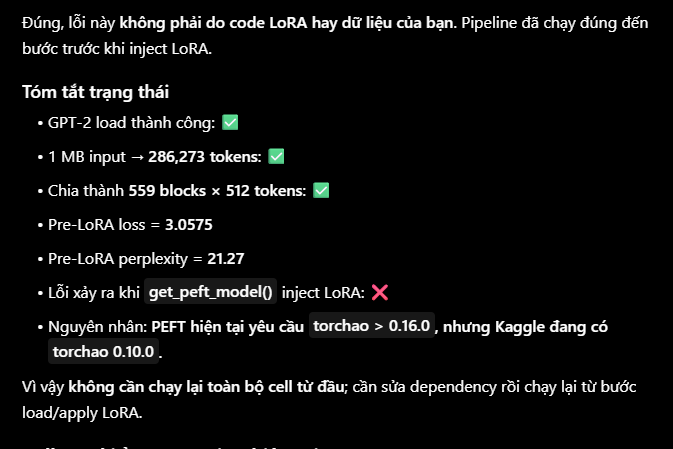

In [ ]:
import torch
import transformers
import peft

print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("peft         :", peft.__version__)

try:
    import torchao
    print("torchao      :", torchao.__version__)
except Exception as e:
    print("torchao import error:", e)


In [ ]:
!pip install -U "torchao>=0.16.0"
#Sau khi pip cài xong, restart kernel/session của Kaggle rồi mới chạy lại. Đây là bước quan trọng vì Python process hiện tại đã import PEFT/torchao cũ.

In [ ]:
import torch
import transformers
import peft
import torchao

print("torch        :", torch.__version__)
print("transformers :", transformers.__version__)
print("peft         :", peft.__version__)
print("torchao      :", torchao.__version__)

assert tuple(map(int, torchao.__version__.split(".")[:2])) >= (0, 16), \
    f"torchao quá cũ: {torchao.__version__}"

print("\n✅ torchao version compatible with current PEFT requirement")

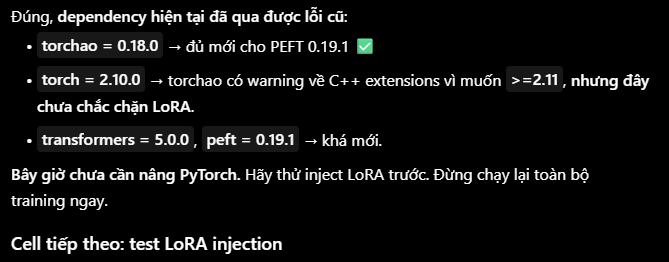

In [ ]:
# ============================================================
# STAGE 3.5 — TEST LoRA INJECTION ONLY
# ============================================================

import torch
from transformers import AutoModelForCausalLM
from peft import LoraConfig, get_peft_model, TaskType

MODEL_NAME = "gpt2"

print("=" * 70)
print("TEST LoRA INJECTION")
print("=" * 70)

print("PyTorch :", torch.__version__)
print("CUDA    :", torch.cuda.is_available())

# ------------------------------------------------------------
# Load GPT-2
# ------------------------------------------------------------

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)

if torch.cuda.is_available():
    model = model.cuda()

model.config.pad_token_id = model.config.eos_token_id

print("\nGPT-2 loaded.")

# ------------------------------------------------------------
# LoRA config
# ------------------------------------------------------------

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,

    r=8,
    lora_alpha=16,
    lora_dropout=0.05,

    target_modules=[
        "c_attn",
        "c_proj",
    ],

    bias="none",
)

# ------------------------------------------------------------
# Inject LoRA
# ------------------------------------------------------------

print("\nInjecting LoRA...")

model = get_peft_model(
    model,
    lora_config
)

print("\n✅ LoRA injection SUCCESS")

model.print_trainable_parameters()

# ------------------------------------------------------------
# Verify trainable parameters
# ------------------------------------------------------------

trainable = 0
total = 0

for name, param in model.named_parameters():

    total += param.numel()

    if param.requires_grad:
        trainable += param.numel()

print("\nTotal parameters    :", total)
print("Trainable parameters:", trainable)
print(
    "Trainable percentage:",
    100 * trainable / total,
    "%"
)

# ------------------------------------------------------------
# GPU memory
# ------------------------------------------------------------

if torch.cuda.is_available():

    allocated = torch.cuda.memory_allocated() / (1024 ** 2)
    reserved = torch.cuda.memory_reserved() / (1024 ** 2)

    print("\nGPU memory")
    print("Allocated:", allocated, "MiB")
    print("Reserved :", reserved, "MiB")

print("\n" + "=" * 70)
print("READY FOR LoRA TRAINING")
print("=" * 70)


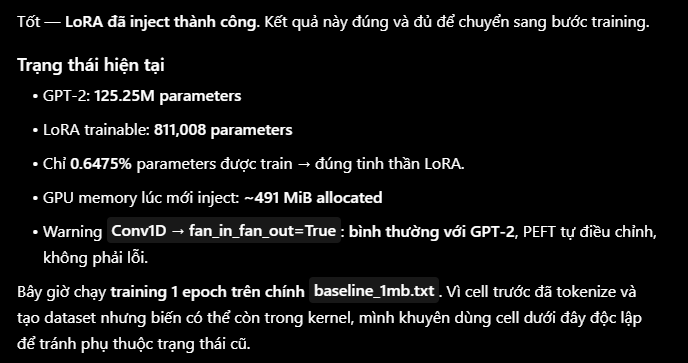

In [ ]:
# ============================================================
# STAGE 3.5 — LoRA ONLINE MEMORIZATION
# TRAINING
# ============================================================

import os
import time
import math
import json
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling,
)
from peft import LoraConfig, get_peft_model, TaskType

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

MODEL_NAME = "gpt2"

INPUT_FILE = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
)

OUTPUT_DIR = Path(
    "/kaggle/working/finezip_experiment/lora_gpt2_1mb"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BLOCK_SIZE = 512

LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.05

NUM_EPOCHS = 1
BATCH_SIZE = 2
GRAD_ACCUM = 4
LEARNING_RATE = 2e-4

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ------------------------------------------------------------
# RESET GPU MEMORY
# ------------------------------------------------------------

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

print("=" * 70)
print("STAGE 3.5 — LoRA ONLINE MEMORIZATION TRAINING")
print("=" * 70)

print("Model      :", MODEL_NAME)
print("Input      :", INPUT_FILE)
print("Output     :", OUTPUT_DIR)
print("Device     :", DEVICE)
print("Block size :", BLOCK_SIZE)
print("Epochs     :", NUM_EPOCHS)
print("Batch size :", BATCH_SIZE)
print("Grad accum :", GRAD_ACCUM)
print("LR         :", LEARNING_RATE)

# ------------------------------------------------------------
# 1. LOAD TEXT
# ------------------------------------------------------------

text = INPUT_FILE.read_text(errors="ignore")

print("\nOriginal bytes:", INPUT_FILE.stat().st_size)
print("Characters    :", len(text))

# ------------------------------------------------------------
# 2. TOKENIZER
# ------------------------------------------------------------

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# ------------------------------------------------------------
# 3. TOKENIZE
# ------------------------------------------------------------

print("\nTokenizing...")

tokenized = tokenizer(
    text,
    return_attention_mask=False,
    add_special_tokens=False,
)

input_ids = tokenized["input_ids"]

print("Total tokens:", len(input_ids))

# ------------------------------------------------------------
# 4. BUILD 512-TOKEN BLOCKS
# ------------------------------------------------------------

blocks = []

for i in range(
    0,
    len(input_ids) - BLOCK_SIZE + 1,
    BLOCK_SIZE
):
    blocks.append(
        input_ids[i:i + BLOCK_SIZE]
    )

print("Training blocks:", len(blocks))
print("Tokens used    :", len(blocks) * BLOCK_SIZE)

class TextBlockDataset(torch.utils.data.Dataset):

    def __init__(self, blocks):
        self.blocks = blocks

    def __len__(self):
        return len(self.blocks)

    def __getitem__(self, idx):

        return {
            "input_ids": torch.tensor(
                self.blocks[idx],
                dtype=torch.long
            )
        }

dataset = TextBlockDataset(blocks)

# ------------------------------------------------------------
# 5. LOAD GPT-2
# ------------------------------------------------------------

print("\nLoading GPT-2...")

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME
)

model.config.pad_token_id = tokenizer.pad_token_id

model = model.to(DEVICE)

# ------------------------------------------------------------
# 6. PRE-LoRA LOSS
# ------------------------------------------------------------

print("\nCalculating PRE-LoRA loss...")

model.eval()

sample_blocks = blocks[:20]

losses_before = []

with torch.no_grad():

    for block in sample_blocks:

        x = torch.tensor(
            [block],
            dtype=torch.long,
            device=DEVICE
        )

        outputs = model(
            input_ids=x,
            labels=x
        )

        losses_before.append(
            outputs.loss.item()
        )

loss_before = sum(losses_before) / len(losses_before)
ppl_before = math.exp(loss_before)

print("Pre-LoRA loss :", loss_before)
print("Pre-LoRA PPL  :", ppl_before)

# ------------------------------------------------------------
# 7. APPLY LoRA
# ------------------------------------------------------------

print("\nApplying LoRA...")

lora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,

    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,

    target_modules=[
        "c_attn",
        "c_proj",
    ],

    bias="none",
)

model = get_peft_model(
    model,
    lora_config
)

model.print_trainable_parameters()

# ------------------------------------------------------------
# 8. TRAIN
# ------------------------------------------------------------

training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),

    num_train_epochs=NUM_EPOCHS,

    per_device_train_batch_size=BATCH_SIZE,

    gradient_accumulation_steps=GRAD_ACCUM,

    learning_rate=LEARNING_RATE,

    logging_steps=25,

    save_strategy="no",

    fp16=torch.cuda.is_available(),

    report_to="none",

    remove_unused_columns=False,

    optim="adamw_torch",
)

data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=dataset,
    data_collator=data_collator,
)

print("\nStarting training...")

start_time = time.time()

train_result = trainer.train()

training_time = time.time() - start_time

print("\nTraining finished.")
print("Training time:", training_time, "seconds")

# ------------------------------------------------------------
# 9. SAVE LoRA ADAPTER
# ------------------------------------------------------------

print("\nSaving LoRA adapter...")

model.save_pretrained(
    OUTPUT_DIR
)

tokenizer.save_pretrained(
    OUTPUT_DIR
)

print("Adapter saved:", OUTPUT_DIR)

# ------------------------------------------------------------
# 10. POST-LoRA LOSS
# ------------------------------------------------------------

print("\nCalculating POST-LoRA loss...")

model.eval()

losses_after = []

with torch.no_grad():

    for block in sample_blocks:

        x = torch.tensor(
            [block],
            dtype=torch.long,
            device=DEVICE
        )

        outputs = model(
            input_ids=x,
            labels=x
        )

        losses_after.append(
            outputs.loss.item()
        )

loss_after = sum(losses_after) / len(losses_after)
ppl_after = math.exp(loss_after)

print("Post-LoRA loss:", loss_after)
print("Post-LoRA PPL :", ppl_after)

# ------------------------------------------------------------
# 11. GPU MEMORY
# ------------------------------------------------------------

peak_allocated = None
peak_reserved = None

if torch.cuda.is_available():

    peak_allocated = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
    )

    peak_reserved = (
        torch.cuda.max_memory_reserved()
        / (1024 ** 2)
    )

    print("\nGPU:", torch.cuda.get_device_name(0))
    print(
        "Peak allocated:",
        peak_allocated,
        "MiB"
    )

    print(
        "Peak reserved :",
        peak_reserved,
        "MiB"
    )

# ------------------------------------------------------------
# 12. SAVE RESULTS
# ------------------------------------------------------------

result = {

    "model": MODEL_NAME,

    "input_file": str(INPUT_FILE),

    "input_bytes": INPUT_FILE.stat().st_size,

    "tokens": len(input_ids),

    "training_blocks": len(blocks),

    "block_size": BLOCK_SIZE,

    "lora_r": LORA_R,

    "lora_alpha": LORA_ALPHA,

    "lora_dropout": LORA_DROPOUT,

    "epochs": NUM_EPOCHS,

    "batch_size": BATCH_SIZE,

    "gradient_accumulation": GRAD_ACCUM,

    "learning_rate": LEARNING_RATE,

    "loss_before": loss_before,

    "perplexity_before": ppl_before,

    "loss_after": loss_after,

    "perplexity_after": ppl_after,

    "training_time_seconds": training_time,

    "peak_gpu_allocated_mib": peak_allocated,

    "peak_gpu_reserved_mib": peak_reserved,

    "adapter_dir": str(OUTPUT_DIR),
}

with open(
    OUTPUT_DIR / "lora_results.json",
    "w"
) as f:

    json.dump(
        result,
        f,
        indent=2
    )

# ------------------------------------------------------------
# FINAL
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STAGE 3.5 — LoRA TRAINING RESULT")
print("=" * 70)

print(json.dumps(result, indent=2))

print("\n✅ LoRA online memorization training completed.")


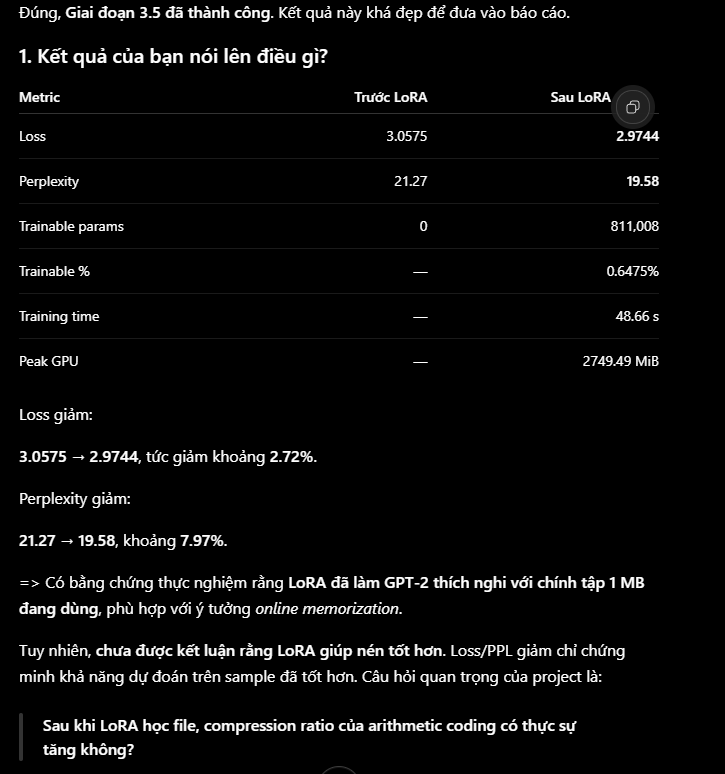

Cell tiếp theo sẽ không train LoRA lại. Nó lấy adapter đã lưu ở:

/kaggle/working/finezip_experiment/lora_gpt2_1mb

rồi sửa một bản eval_ac_lora.py để:

GPT-2 base → load LoRA adapter → Arithmetic Coding → decode → verify lossless.

chạy context 128 và 512 trước, vì đây là hai điểm đại diện và bạn đã có baseline GPT-2 tương ứng.

In [ ]:
# ============================================================
# STAGE 3.5 — LoRA COMPRESSION EXPERIMENT
#
# GPT-2 + LoRA adapter
# -> Arithmetic Coding
# -> Decode
# -> Exact lossless verification
#
# Context: 128 and 512
# ============================================================

import os
import sys
import time
import json
import shutil
import subprocess
from pathlib import Path

import torch

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

FINEZIP_DIR = Path("/kaggle/working/finezip")

BASE_EVAL = FINEZIP_DIR / "AC" / "eval_ac.py"

LORA_DIR = Path(
    "/kaggle/working/finezip_experiment/lora_gpt2_1mb"
)

INPUT_FILE = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
)

OUTPUT_BASE = Path(
    "/kaggle/working/finezip_experiment"
)

LORA_EVAL = OUTPUT_BASE / "eval_ac_lora.py"

# ------------------------------------------------------------
# CHECK FILES
# ------------------------------------------------------------

print("=" * 70)
print("STAGE 3.5 — LoRA COMPRESSION EXPERIMENT")
print("=" * 70)

print("Base eval :", BASE_EVAL)
print("LoRA dir  :", LORA_DIR)
print("Input     :", INPUT_FILE)

assert BASE_EVAL.exists(), \
    f"Missing eval_ac.py: {BASE_EVAL}"

assert LORA_DIR.exists(), \
    f"Missing LoRA adapter: {LORA_DIR}"

assert INPUT_FILE.exists(), \
    f"Missing input: {INPUT_FILE}"

# ------------------------------------------------------------
# READ ORIGINAL eval_ac.py
# ------------------------------------------------------------

source = BASE_EVAL.read_text()

print("\nOriginal eval_ac.py size:", len(source), "characters")

# ------------------------------------------------------------
# MODIFY MODEL LOADING
# ------------------------------------------------------------
#
# Original:
#
# model = AutoModelForCausalLM.from_pretrained(args.model)
#
# We replace it with:
#
# 1. Load GPT-2 base
# 2. Load LoRA adapter
#
# ------------------------------------------------------------

old_line = (
    "model = AutoModelForCausalLM.from_pretrained(args.model)"
)

new_code = """
# ============================================================
# LoRA MODEL LOADING
# ============================================================

from peft import PeftModel

BASE_MODEL = "gpt2"

print("Loading base model:", BASE_MODEL)

model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL
)

print("Loading LoRA adapter:", args.model)

model = PeftModel.from_pretrained(
    model,
    args.model
)

print("LoRA adapter loaded successfully.")

"""

if old_line not in source:
    raise RuntimeError(
        "Could not find the expected model-loading line in eval_ac.py"
    )

source_lora = source.replace(
    old_line,
    new_code
)

# ------------------------------------------------------------
# SAVE MODIFIED SCRIPT
# ------------------------------------------------------------

LORA_EVAL.write_text(source_lora)

print("\nCreated:")
print(LORA_EVAL)

# ------------------------------------------------------------
# VERIFY MODIFICATION
# ------------------------------------------------------------

check = LORA_EVAL.read_text()

assert "PeftModel" in check
assert "PeftModel.from_pretrained" in check

print("✅ LoRA loading code inserted successfully.")

# ------------------------------------------------------------
# RUN EXPERIMENT
# ------------------------------------------------------------

contexts = [128, 512]

results = []

for context in contexts:

    print("\n")
    print("=" * 70)
    print(f"LLMZIP/FINEZIP LoRA — CONTEXT {context}")
    print("=" * 70)

    output_dir = (
        OUTPUT_BASE /
        f"lora_gpt2_ctx{context}"
    )

    if output_dir.exists():
        shutil.rmtree(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    command = [
        sys.executable,
        str(LORA_EVAL),

        "--model",
        str(LORA_DIR),

        "--tokenizer",
        "gpt2",

        "--batch_size",
        "1",

        "--context_size",
        str(context),

        "--input_file",
        str(INPUT_FILE),

        "--AC_output_dir",
        str(output_dir),

        "--encode_decode",
        "1",
    ]

    print("\nRunning command:\n")

    print(" ".join(command))

    start = time.time()

    process = subprocess.run(
        command,
        cwd=str(FINEZIP_DIR),
        text=True,
        capture_output=False,
    )

    elapsed = time.time() - start

    print("\nProcess return code:", process.returncode)
    print("Wall-clock time:", elapsed, "seconds")

    if process.returncode != 0:

        print(
            f"\n❌ LoRA compression failed "
            f"for context={context}"
        )

        results.append({
            "context": context,
            "status": "FAILED",
            "wall_time_seconds": elapsed,
        })

        continue

    # --------------------------------------------------------
    # Try to locate generated metrics
    # --------------------------------------------------------

    metric_candidates = list(
        output_dir.rglob("*.json")
    )

    result_entry = {
        "context": context,
        "status": "SUCCESS",
        "wall_time_seconds": elapsed,
        "output_dir": str(output_dir),
        "metric_files": [
            str(x) for x in metric_candidates
        ],
    }

    results.append(result_entry)

# ------------------------------------------------------------
# SAVE SUMMARY
# ------------------------------------------------------------

summary_file = (
    OUTPUT_BASE /
    "stage3_5_lora_compression_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        results,
        f,
        indent=2
    )

print("\n")
print("=" * 70)
print("STAGE 3.5 SUMMARY")
print("=" * 70)

print(
    json.dumps(
        results,
        indent=2
    )
)

print("\nSummary saved to:")
print(summary_file)

print("\n✅ Experiment finished.")


Cell sửa eval_ac_lora.py + chạy lại Context 128/512

In [ ]:
# ============================================================
# FIX eval_ac_lora.py
# THEN RUN LoRA COMPRESSION — CONTEXT 128 / 512
# ============================================================

from pathlib import Path
import sys
import time
import json
import shutil
import subprocess

FINEZIP_DIR = Path(
    "/kaggle/working/finezip"
)

BASE_EVAL = (
    FINEZIP_DIR /
    "AC" /
    "eval_ac.py"
)

LORA_DIR = Path(
    "/kaggle/working/finezip_experiment/lora_gpt2_1mb"
)

INPUT_FILE = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
)

OUTPUT_BASE = Path(
    "/kaggle/working/finezip_experiment"
)

LORA_EVAL = (
    OUTPUT_BASE /
    "eval_ac_lora.py"
)

# ------------------------------------------------------------
# CHECK
# ------------------------------------------------------------

assert BASE_EVAL.exists()
assert LORA_DIR.exists()
assert INPUT_FILE.exists()

# ------------------------------------------------------------
# READ ORIGINAL eval_ac.py
# ------------------------------------------------------------

source = BASE_EVAL.read_text()

# ------------------------------------------------------------
# IMPORTANT:
# The original line is inside main(), therefore the replacement
# code MUST have exactly 4 spaces indentation.
# ------------------------------------------------------------

old = (
    "    model = AutoModelForCausalLM.from_pretrained(args.model)"
)

new = """    # ========================================================
    # LoRA MODEL LOADING
    # ========================================================

    from peft import PeftModel

    BASE_MODEL = "gpt2"

    print("Loading base model:", BASE_MODEL)

    model = AutoModelForCausalLM.from_pretrained(
        BASE_MODEL
    )

    print("Loading LoRA adapter:", args.model)

    model = PeftModel.from_pretrained(
        model,
        args.model
    )

    print("LoRA adapter loaded successfully.")
"""

if old not in source:
    raise RuntimeError(
        "Could not find expected model-loading line."
    )

fixed_source = source.replace(
    old,
    new,
    1
)

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

LORA_EVAL.write_text(
    fixed_source
)

print("=" * 70)
print("FIXED eval_ac_lora.py")
print("=" * 70)

print("File:", LORA_EVAL)

# ------------------------------------------------------------
# SYNTAX CHECK FIRST
# ------------------------------------------------------------

print("\nChecking Python syntax...")

syntax_check = subprocess.run(
    [
        sys.executable,
        "-m",
        "py_compile",
        str(LORA_EVAL),
    ],
    capture_output=True,
    text=True,
)

if syntax_check.returncode != 0:

    print(syntax_check.stderr)

    raise RuntimeError(
        "❌ Syntax check failed."
    )

print("✅ Syntax check passed.")

# ------------------------------------------------------------
# RUN CONTEXT 128 / 512
# ------------------------------------------------------------

contexts = [128, 512]

results = []

for context in contexts:

    print("\n")
    print("=" * 70)
    print(f"LoRA COMPRESSION — CONTEXT {context}")
    print("=" * 70)

    output_dir = (
        OUTPUT_BASE /
        f"lora_gpt2_ctx{context}"
    )

    if output_dir.exists():
        shutil.rmtree(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    command = [
        sys.executable,
        str(LORA_EVAL),

        "--model",
        str(LORA_DIR),

        "--tokenizer",
        "gpt2",

        "--batch_size",
        "1",

        "--context_size",
        str(context),

        "--input_file",
        str(INPUT_FILE),

        "--AC_output_dir",
        str(output_dir),

        "--encode_decode",
        "1",
    ]

    print("\nCommand:")
    print(" ".join(command))
    print()

    start = time.time()

    process = subprocess.run(
        command,
        cwd=str(FINEZIP_DIR),
        text=True,
    )

    elapsed = time.time() - start

    print("\nReturn code:", process.returncode)
    print("Wall time  :", elapsed, "seconds")

    results.append({
        "context": context,
        "return_code": process.returncode,
        "wall_time_seconds": elapsed,
        "output_dir": str(output_dir),
    })

# ------------------------------------------------------------
# SAVE SUMMARY
# ------------------------------------------------------------

summary_file = (
    OUTPUT_BASE /
    "stage3_5_lora_compression_summary.json"
)

with open(summary_file, "w") as f:
    json.dump(
        results,
        f,
        indent=2
    )

print("\n")
print("=" * 70)
print("STAGE 3.5 COMPLETE")
print("=" * 70)

print(
    json.dumps(
        results,
        indent=2
    )
)

print("\nSummary:", summary_file)


In [ ]:
# ============================================================
# FIX arithmeticcoding PATH
# THEN RUN LoRA COMPRESSION
# ============================================================

from pathlib import Path
import sys
import subprocess
import time
import json
import shutil

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

FINEZIP_DIR = Path(
    "/kaggle/working/finezip"
)

AC_DIR = (
    FINEZIP_DIR /
    "AC"
)

LORA_EVAL = Path(
    "/kaggle/working/finezip_experiment/eval_ac_lora.py"
)

LORA_DIR = Path(
    "/kaggle/working/finezip_experiment/lora_gpt2_1mb"
)

INPUT_FILE = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
)

OUTPUT_BASE = Path(
    "/kaggle/working/finezip_experiment"
)

assert AC_DIR.exists()
assert LORA_EVAL.exists()
assert LORA_DIR.exists()
assert INPUT_FILE.exists()

# ------------------------------------------------------------
# READ SCRIPT
# ------------------------------------------------------------

source = LORA_EVAL.read_text()

# ------------------------------------------------------------
# ADD AC DIRECTORY TO PYTHON PATH
# ------------------------------------------------------------

path_injection = f'''
# ============================================================
# FINEZIP AC MODULE PATH
# ============================================================

import sys
import os

AC_DIR = r"{AC_DIR}"

if AC_DIR not in sys.path:
    sys.path.insert(0, AC_DIR)

print("FineZip AC module path:", AC_DIR)
'''

# Put it immediately after the initial imports.
# Avoid adding it twice.

if "FineZip AC module path:" not in source:

    source = path_injection + "\n" + source

LORA_EVAL.write_text(source)

print("=" * 70)
print("FIXED arithmeticcoding IMPORT PATH")
print("=" * 70)

print("AC directory:", AC_DIR)
print("Script      :", LORA_EVAL)

# ------------------------------------------------------------
# SYNTAX CHECK
# ------------------------------------------------------------

print("\nChecking syntax...")

check = subprocess.run(
    [
        sys.executable,
        "-m",
        "py_compile",
        str(LORA_EVAL),
    ],
    capture_output=True,
    text=True,
)

if check.returncode != 0:

    print(check.stderr)

    raise RuntimeError(
        "Syntax check failed."
    )

print("✅ Syntax OK")

# ------------------------------------------------------------
# CHECK arithmeticcoding DIRECTLY
# ------------------------------------------------------------

print("\nTesting arithmeticcoding import...")

test_code = f"""
import sys
sys.path.insert(0, r"{AC_DIR}")

import arithmeticcoding

print("arithmeticcoding loaded from:")
print(arithmeticcoding.__file__)
"""

test = subprocess.run(
    [
        sys.executable,
        "-c",
        test_code,
    ],
    capture_output=True,
    text=True,
)

print(test.stdout)

if test.returncode != 0:

    print(test.stderr)

    raise RuntimeError(
        "❌ arithmeticcoding still cannot be imported."
    )

print("✅ arithmeticcoding import works")

# ------------------------------------------------------------
# RUN CONTEXT 128 / 512
# ------------------------------------------------------------

contexts = [128, 512]

results = []

for context in contexts:

    print("\n")
    print("=" * 70)
    print(f"LoRA COMPRESSION — CONTEXT {context}")
    print("=" * 70)

    output_dir = (
        OUTPUT_BASE /
        f"lora_gpt2_ctx{context}"
    )

    if output_dir.exists():
        shutil.rmtree(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    command = [
        sys.executable,
        str(LORA_EVAL),

        "--model",
        str(LORA_DIR),

        "--tokenizer",
        "gpt2",

        "--batch_size",
        "1",

        "--context_size",
        str(context),

        "--input_file",
        str(INPUT_FILE),

        "--AC_output_dir",
        str(output_dir),

        "--encode_decode",
        "1",
    ]

    print("\nCommand:")
    print(" ".join(command))
    print()

    start = time.time()

    process = subprocess.run(
        command,
        cwd=str(FINEZIP_DIR),
        text=True,
    )

    elapsed = time.time() - start

    print("\nReturn code:", process.returncode)
    print("Wall time:", elapsed, "seconds")

    results.append({
        "context": context,
        "return_code": process.returncode,
        "wall_time_seconds": elapsed,
        "output_dir": str(output_dir),
    })

# ------------------------------------------------------------
# SAVE SUMMARY
# ------------------------------------------------------------

summary_file = (
    OUTPUT_BASE /
    "stage3_5_lora_compression_summary.json"
)

with open(summary_file, "w") as f:

    json.dump(
        results,
        f,
        indent=2
    )

print("\n")
print("=" * 70)
print("STAGE 3.5 SUMMARY")
print("=" * 70)

print(
    json.dumps(
        results,
        indent=2
    )
)

print("\nSummary saved to:")
print(summary_file)


In [ ]:
from pathlib import Path
import os
import time

d = Path("/kaggle/working/finezip_experiment/lora_gpt2_ctx512")

print("Directory exists:", d.exists())

if d.exists():
    files = list(d.rglob("*"))

    print("\nFiles:")
    for p in files:
        if p.is_file():
            print(
                f"{p.name:40s} "
                f"{p.stat().st_size:,} bytes"
            )

print("\nDirectory size:")
if d.exists():
    total = sum(
        p.stat().st_size
        for p in d.rglob("*")
        if p.is_file()
    )
    print(f"{total:,} bytes")


In [ ]:
import json
from pathlib import Path

metrics = Path(
    "/kaggle/working/finezip_experiment/lora_gpt2_ctx512/metrics.json"
)

print(metrics.read_text())


In [ ]:
from pathlib import Path

for ctx in [128, 512]:
    d = Path(
        f"/kaggle/working/finezip_experiment/lora_gpt2_ctx{ctx}"
    )

    print(f"\n===== CONTEXT {ctx} =====")

    for p in d.iterdir():
        if p.is_file():
            print(p.name, p.stat().st_size, "bytes")

    metrics = d / "metrics.json"

    if metrics.exists():
        print("\nmetrics.json:")
        print(metrics.read_text())


In [ ]:
!zip -r /kaggle/working/finezip_experiment.zip /kaggle/working/finezip_experiment

In [ ]:
print(source)


chỉ đo loss, và không fine-tune lại. Vì LoRA adapter đã có sẵn, ta sẽ đo trên cùng một phần dữ liệu để so sánh công bằng.

In [ ]:
# ============================================================
# STAGE 3.5 — LoRA LOSS BEFORE / AFTER
# Fast evaluation for report
# ============================================================

import os
import json
import time
from pathlib import Path

import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

INPUT_FILE = Path(
    "/kaggle/working/finezip_experiment/data/baseline_1mb.txt"
)

LORA_DIR = Path(
    "/kaggle/working/finezip_experiment/lora_gpt2_1mb"
)

OUTPUT_DIR = Path(
    "/kaggle/working/finezip_experiment"
)

RESULT_FILE = OUTPUT_DIR / "stage3_5_lora_loss.json"

assert INPUT_FILE.exists(), INPUT_FILE
assert LORA_DIR.exists(), LORA_DIR

# ------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------

BASE_MODEL = "gpt2"
TOKENIZER_NAME = "gpt2"

CONTEXT_SIZE = 512

# Keep this small enough to finish quickly.
# Same tokens are used for BEFORE and AFTER.
MAX_EVAL_TOKENS = 16384

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("STAGE 3.5 — LoRA LOSS BEFORE / AFTER")
print("=" * 70)

print("Device:", DEVICE)
print("Input :", INPUT_FILE)
print("LoRA  :", LORA_DIR)
print("Eval tokens:", MAX_EVAL_TOKENS)
print("Context:", CONTEXT_SIZE)

# ------------------------------------------------------------
# LOAD TEXT + TOKENIZE ONCE
# ------------------------------------------------------------

print("\nLoading tokenizer...")

tokenizer = AutoTokenizer.from_pretrained(
    TOKENIZER_NAME
)

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    text = f.read()

print("Original characters:", len(text))

print("\nTokenizing...")

tokens = tokenizer(
    text,
    return_tensors="pt",
    add_special_tokens=True
)["input_ids"].squeeze(0)

print("Total tokens:", len(tokens))

# IMPORTANT:
# Same subset is used for both models.
tokens = tokens[:MAX_EVAL_TOKENS]

print("Evaluation tokens:", len(tokens))

# ------------------------------------------------------------
# LOSS FUNCTION
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_loss(model, tokens, context_size=512):

    model.eval()

    total_loss = 0.0
    total_tokens = 0

    start_time = time.time()

    # Need at least 2 tokens for next-token prediction
    for start in range(
        0,
        len(tokens) - 1,
        context_size
    ):

        chunk = tokens[
            start:start + context_size
        ]

        if len(chunk) < 2:
            continue

        input_ids = chunk.unsqueeze(0).to(DEVICE)

        outputs = model(
            input_ids=input_ids,
            labels=input_ids
        )

        # HF loss is averaged over predicted tokens
        n_pred_tokens = input_ids.shape[1] - 1

        total_loss += (
            outputs.loss.item()
            * n_pred_tokens
        )

        total_tokens += n_pred_tokens

    elapsed = time.time() - start_time

    avg_loss = total_loss / total_tokens

    perplexity = torch.exp(
        torch.tensor(avg_loss)
    ).item()

    return {
        "loss": avg_loss,
        "perplexity": perplexity,
        "eval_tokens": total_tokens,
        "time_seconds": elapsed
    }


# ------------------------------------------------------------
# GPU MEMORY RESET
# ------------------------------------------------------------

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

# ------------------------------------------------------------
# 1. GPT-2 PRETRAINED — BEFORE LoRA
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("1/2 — GPT-2 PRETRAINED (BEFORE LoRA)")
print("=" * 70)

before_load_start = time.time()

base_model = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL
)

base_model.to(DEVICE)

before_load_time = time.time() - before_load_start

print("Model loaded.")

before_result = evaluate_loss(
    base_model,
    tokens,
    CONTEXT_SIZE
)

if torch.cuda.is_available():
    before_peak_memory = (
        torch.cuda.max_memory_allocated()
        / 1024**2
    )
else:
    before_peak_memory = None

print("\nBEFORE LoRA")
print("Loss       :", before_result["loss"])
print("Perplexity :", before_result["perplexity"])
print("Eval tokens:", before_result["eval_tokens"])
print("Time       :", before_result["time_seconds"], "s")

if before_peak_memory is not None:
    print(
        "Peak GPU memory:",
        before_peak_memory,
        "MiB"
    )

# ------------------------------------------------------------
# DELETE BASE MODEL BEFORE LOADING LoRA
# ------------------------------------------------------------

del base_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

# ------------------------------------------------------------
# 2. GPT-2 + LoRA — AFTER
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("2/2 — GPT-2 + LoRA (AFTER)")
print("=" * 70)

after_load_start = time.time()

base_model_lora = AutoModelForCausalLM.from_pretrained(
    BASE_MODEL
)

base_model_lora.to(DEVICE)

print("Loading LoRA adapter...")

lora_model = PeftModel.from_pretrained(
    base_model_lora,
    str(LORA_DIR)
)

lora_model.to(DEVICE)

after_load_time = time.time() - after_load_start

print("LoRA adapter loaded.")

after_result = evaluate_loss(
    lora_model,
    tokens,
    CONTEXT_SIZE
)

if torch.cuda.is_available():
    after_peak_memory = (
        torch.cuda.max_memory_allocated()
        / 1024**2
    )
else:
    after_peak_memory = None

print("\nAFTER LoRA")
print("Loss       :", after_result["loss"])
print("Perplexity :", after_result["perplexity"])
print("Eval tokens:", after_result["eval_tokens"])
print("Time       :", after_result["time_seconds"], "s")

if after_peak_memory is not None:
    print(
        "Peak GPU memory:",
        after_peak_memory,
        "MiB"
    )

# ------------------------------------------------------------
# COMPARISON
# ------------------------------------------------------------

loss_before = before_result["loss"]
loss_after = after_result["loss"]

loss_change = loss_after - loss_before

if loss_before != 0:
    loss_change_percent = (
        loss_change / loss_before
    ) * 100
else:
    loss_change_percent = None

ppl_before = before_result["perplexity"]
ppl_after = after_result["perplexity"]

print("\n" + "=" * 70)
print("COMPARISON")
print("=" * 70)

print(f"Loss before LoRA : {loss_before:.6f}")
print(f"Loss after LoRA  : {loss_after:.6f}")
print(f"Loss change      : {loss_change:.6f}")

if loss_change_percent is not None:
    print(
        f"Loss change (%)  : {loss_change_percent:.2f}%"
    )

print()
print(f"Perplexity before : {ppl_before:.4f}")
print(f"Perplexity after  : {ppl_after:.4f}")

if loss_after < loss_before:
    print("\n✅ Loss decreased after LoRA.")
    print("This provides evidence that the LoRA model")
    print("adapted to the evaluation text.")
else:
    print("\n⚠️ Loss did not decrease.")
    print("Do not claim that LoRA improved prediction based")
    print("on this experiment.")

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

results = {
    "base_model": BASE_MODEL,
    "lora_adapter": str(LORA_DIR),
    "input_file": str(INPUT_FILE),

    "evaluation": {
        "max_eval_tokens": MAX_EVAL_TOKENS,
        "actual_eval_tokens": int(len(tokens)),
        "context_size": CONTEXT_SIZE,
        "same_tokens_for_before_after": True
    },

    "before_lora": {
        **before_result,
        "peak_gpu_memory_mib": before_peak_memory,
        "model_load_time_seconds": before_load_time
    },

    "after_lora": {
        **after_result,
        "peak_gpu_memory_mib": after_peak_memory,
        "model_load_time_seconds": after_load_time
    },

    "comparison": {
        "loss_difference": loss_change,
        "loss_change_percent": loss_change_percent,
        "perplexity_difference": ppl_after - ppl_before
    }
}

with open(RESULT_FILE, "w") as f:
    json.dump(
        results,
        f,
        indent=2
    )

print("\nResults saved to:")
print(RESULT_FILE)

print("\n" + "=" * 70)
print("DONE")
print("=" * 70)


In [ ]:
# ============================================================
# CREATE FULL BASELINE TABLE
# ============================================================

import csv
from pathlib import Path

BASE_DIR = Path(
    "/kaggle/working/finezip_experiment"
)

rows = [

    # --------------------------------------------------------
    # GZIP
    # --------------------------------------------------------
    {
        "Method": "gzip",
        "Model": "-",
        "Pipeline": "DEFLATE",
        "Context": "-",
        "Batch": "-",
        "AC bits": "",
        "Compressed (B)": 355808,
        "Ratio": 2.811,
        "Compressed %": 35.58,
        "Bits/char": 2.859,
        "Enc (s)": 0.07,
        "Dec (s)": 0.01,
        "GPU peak (MiB)": "-",
        "Lossless": "✓",
        "Savings vs BZip2": -26.5,
        "Notes": "GĐ2"
    },

    # --------------------------------------------------------
    # BZIP2
    # --------------------------------------------------------
    {
        "Method": "bzip2",
        "Model": "-",
        "Pipeline": "BWT",
        "Context": "-",
        "Batch": "-",
        "AC bits": "",
        "Compressed (B)": 281323,
        "Ratio": 3.555,
        "Compressed %": 28.13,
        "Bits/char": 2.260,
        "Enc (s)": 0.10,
        "Dec (s)": 0.04,
        "GPU peak (MiB)": "-",
        "Lossless": "✓",
        "Savings vs BZip2": 0.0,
        "Notes": "GĐ2"
    },

    # --------------------------------------------------------
    # LLMZIP-LITE — CONTEXT 32
    # --------------------------------------------------------
    {
        "Method": "LLMZip-lite",
        "Model": "GPT-2",
        "Pipeline": "AC + sliding window (eval_ac.py)",
        "Context": 32,
        "Batch": 1,
        "AC bits": 1494873,
        "Compressed (B)": 186860,
        "Ratio": 5.352,
        "Compressed %": 18.69,
        "Bits/char": 1.501,
        "Enc (s)": 2905.93,
        "Dec (s)": 2851.32,
        "GPU peak (MiB)": 995.75,
        "Lossless": "✓",
        "Savings vs BZip2": 33.6,
        "Notes": "GĐ3"
    },

    # --------------------------------------------------------
    # FINEZIP — CONTEXT 32 BATCH 1
    # --------------------------------------------------------
    {
        "Method": "FineZip",
        "Model": "GPT-2",
        "Pipeline": "rank + bzip2, chunk (eval_clean.py)",
        "Context": 32,
        "Batch": 1,
        "AC bits": "",
        "Compressed (B)": 293093,
        "Ratio": 3.412,
        "Compressed %": 29.31,
        "Bits/char": 2.355,
        "Enc (s)": 2740.09,
        "Dec (s)": 2761.86,
        "GPU peak (MiB)": 993.43,
        "Lossless": "✓",
        "Savings vs BZip2": -4.2,
        "Notes": "GĐ2"
    },

    # --------------------------------------------------------
    # FINEZIP — CONTEXT 32 BATCH 64
    # --------------------------------------------------------
    {
        "Method": "FineZip",
        "Model": "GPT-2",
        "Pipeline": "rank + bzip2, chunk (eval_clean.py)",
        "Context": 32,
        "Batch": 64,
        "AC bits": "",
        "Compressed (B)": 293027,
        "Ratio": 3.413,
        "Compressed %": 29.30,
        "Bits/char": 2.354,
        "Enc (s)": 61.63,
        "Dec (s)": "",
        "GPU peak (MiB)": "",
        "Lossless": "✓",
        "Savings vs BZip2": -4.2,
        "Notes": "GĐ3; batch 64"
    }
]

# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

csv_file = BASE_DIR / "baseline_results_full.csv"

fieldnames = [
    "Method",
    "Model",
    "Pipeline",
    "Context",
    "Batch",
    "AC bits",
    "Compressed (B)",
    "Ratio",
    "Compressed %",
    "Bits/char",
    "Enc (s)",
    "Dec (s)",
    "GPU peak (MiB)",
    "Lossless",
    "Savings vs BZip2",
    "Notes"
]

with open(csv_file, "w", newline="") as f:

    writer = csv.DictWriter(
        f,
        fieldnames=fieldnames
    )

    writer.writeheader()
    writer.writerows(rows)

print("=" * 70)
print("CREATED")
print("=" * 70)

print(csv_file)

print("\nContents:\n")

with open(csv_file, "r") as f:
    print(f.read())
